# 03 — Uncertainty Modeling

In Notebook 02 "System Modelling", a series of analyses were carried out to evaluate how infrastructure stages/projects and plans perform in a nominal future. This Notebook 03 "Uncertainty Modelling" expands these analyses towards a wider range of potential future scenarios. Therefore the main question is not **what could happen in one most likely future?**, but **what range of uncertain future conditions is plausible, which assumptions matter most, and under which combinations of uncertainties does a plan fail?** It shows how deep uncertainty can be represented, sampled, and analysed for the SBB MehrSpur case study using the **EMA (Exploratory Modelling and Analysis) Workbench**. Like Notebook 02, it is a demonstrative tutorial that you should adapt to your own case study.

As mentioned in the exercise sheets (and in the previous notebook) you will be presented with different types of calculations and tasks:
- **Tutorials/Supporting task (optional):** building understanding but are not meant as report deliverable.
- **Mandatory/Expected task:** producing a definition, assumption, or result needed later in the project.
- **Advanced task (optional):** extends the model beyond the supplied example.

## Roadmap and learning objectives

The notebook follows one continuous argument:
1. Define uncertain inputs
2. Translate probability distribution functions (PDFs) into future trajectories
3. Train and validate a fast surrogate model as an approximation of the original model
4. Sample plausible futures
5. Inspect outcomes
6. Identify drivers
7. Compare strategies
8. Discover failure conditions

The notebook is set out as follows:

- **Parts 1-2** define and parameterize uncertainty.
- **Part 3** trains and validates the transport surrogate.
- **Part 4** explains scenario sampling.
- **Part 5** explores outcome distributions.
- **Part 6** studies sensitivity.
- **Part 7** compares static infrastructure stages under shared futures.
- **Part 8** turns failures into interpretable vulnerability regions.

Check exercise-sheet Phase 3 for the corresponding deliverables.

By the end of this notebook, you will be able to:
1. Register the uncertainties (e.g. `PASSENGER_DEMAND_GROWTH`, `PT_ASC_SHIFT`) used in this notebook with the **EMA Workbench**.
2. Characterize how uncertainty evolves over time from Year 1 to Year 40.
3. Sample the uncertainty space using and comparing **Monte Carlo**, **Latin Hypercube (LHS)**, and **Sobol** designs.
4. Quantify physical outcome distributions (e.g. `pt_share`, `avg_travel_time_min`, `congestion_delay_hours`).
5. Rank influential uncertainties using **Extra Trees feature scoring**, **Morris Screening**, and **Sobol Sensitivity Analysis**.
6. Compare all three static plans under identical uncertainty futures:
   * **`baseline` (Stage 0):** No new infrastructure for 40 years.
   * **`static1` (Stage 1 from the start):** Station and access package built in Year 1.
   * **`static2` (Stages 1 + 2 from the start):** Station and tunnel packages both available from Year 1.
7. Perform **Scenario Discovery (using PRIM)** to identify failure boundaries where Year-40 public transport share falls below the target.

## Estimated time for Notebook 03

The transport model from Notebook 02 is too slow to rerun for every scenario (i.e., combination of future uncertain conditions). Part 3 therefore trains a **Gaussian process (GP)**, which is a statistical surrogate model, that approximates transport outputs (from the congested trip assignment model) from a small set of full model runs. Later sections of the notebook and later notebooks reuse the surrogate model instead of repeating the full simulation.

**The supplied MehrSpur example includes a trained GP and response table.** Leave `REBUILD_TRANSPORT_SURROGATE = False` and `REFRESH_RESPONSE_TABLE = False` to load them; no training is needed. Train a new surrogate after changing stages, the corridor, transport inputs or transport uncertainty ranges. Each build runs:
- **100 training simulations**: full model runs the GP learns from (25 per infrastructure configuration).
- **20 validation simulations**: hold-out runs that are *not* used for training, so you can check whether the GP generalises.

The build can take a few hours. It writes a **response table** of physical indicators. After it finishes, set `REBUILD_TRANSPORT_SURROGATE` and `REFRESH_RESPONSE_TABLE` to `False` so that later sessions **load the saved files** instead of training again.

**Your time at the desk:**
- Running the simulations to train the GP: about **2-3 hours**. This can run in the background. If those saved files already exist, the loading takes seconds (no full simulations).
- Reading this notebook without adapting it: about **2–3 hours**.
- Adapting it to your case study: extra time to set uncertainty ranges, rebuild the model training design, check the GP, and document choices.

## Scope

This notebook is deliberately **snapshot-based and static-plan-based**. It samples the uncertainty space and reports outcome *distributions* for the same two snapshots used in Notebook 02 (**Year 1** and **Year 40**) but it does not model full temporal trajectories or adaptive plans (explored in Notebook 4). It reports physical outcomes. Costs and benefits are assessed in the later planning and appraisal notebooks. 

This notebook builds directly on the deterministic Phase 2 model: the same infrastructure stages, the same implementation plans, and the same performance indicators.

> **Reproducibility note:** rerun cells after changing the model or its prepared response. Exported results record the fitted model identity; saved figures should be interpreted with the assumptions used to produce them.


## Setup

Run this notebook from either the repository root or the `notebooks` folder. This is the first notebook that needs the **EMA Workbench**, plus `SALib` (which EMA Workbench uses internally for Morris and Sobol sampling/analysis) and `scikit-learn` (used internally for feature scoring).

EMA Workbench is the experiment manager, not the transport model itself. It gives us a consistent way to register uncertain inputs, generate many futures, evaluate those futures, and pass the resulting dataset to sensitivity and scenario-discovery methods. Without this structure, we would be changing assumptions manually and could not make controlled comparisons across sampling designs or infrastructure stages.

Figures (PNG) and result tables (CSV) save as each analysis finishes to `figures/03_uncertainty_modeling/` and `results/03_uncertainty_modeling/`. Reruns replace files with the same names; files from skipped analyses remain. Set `SAVE_OUTPUTS = False` in Setup to disable these exports. The final shared files in `results/` are still written for subsequent notebooks. Interactive tools themselves are not exported.


In [1]:
# # Install the shared project requirements into the active notebook kernel
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
%pip install --quiet -r "{PROJECT_ROOT / 'requirements.txt'}"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Notebook setup: imports, paths, and the split between transport uncertainties
# (change the expensive coupled assignment) and post-modelling ones (only change
# annualisation/appraisal downstream of an already-computed MSA result).
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("default")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CODE_DIR = PROJECT_ROOT / "code"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures" / "03_uncertainty_modeling"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(CODE_DIR))

import parameters as p
import stages as stages_module
import adaptive_planning as plans_module
import simulation_engine as m
from surrogate_model.transport_surrogate import (
    load_transport_surrogate, load_surrogate_validation,
)

from additional import uncertainty as uc
from additional import notebook_exports as exports

SAVE_OUTPUTS = True  # Save each completed figure and result table; reruns replace files.
exports.configure(PROJECT_ROOT, "03_uncertainty_modeling", enabled=SAVE_OUTPUTS)

def show_table(name, table):
    exports.save_outputs(name, tables={"": table})
    display(table)


# ALL selects every uncertainty used for scenarios; [] keeps nominal paths.
ALL = uc.ALL
SCENARIO_UNCERTAINTIES = ALL
SCENARIO_NAMES = [name for name in uc.select_uncertainties(SCENARIO_UNCERTAINTIES, use="scenarios")
                  if not uc.is_deterministic(name)]
TRANSPORT_UNCERTAINTY_NAMES = [name for name in SCENARIO_NAMES
                              if p.STRUCTURAL_UNCERTAINTIES[name]["category"] == "transport_modelling"]
POST_UNCERTAINTY_NAMES = [name for name in SCENARIO_NAMES
                        if p.STRUCTURAL_UNCERTAINTIES[name]["category"] == "post_modelling"]
preferred = [name for name in ("PASSENGER_DEMAND_GROWTH", "PT_ASC_SHIFT") if name in SCENARIO_NAMES]
DEMO_UNCERTAINTIES = (preferred + [name for name in SCENARIO_NAMES if name not in preferred])[:2]
HAS_TWO_INPUTS = len(DEMO_UNCERTAINTIES) == 2
X_DEMO, Y_DEMO = DEMO_UNCERTAINTIES if HAS_TWO_INPUTS else (None, None)

from ema_workbench import (
    Model, RealParameter, CategoricalParameter, ScalarOutcome,
    SequentialEvaluator, perform_experiments, Samplers,
)
try:
    from ema_workbench import Policy
except ImportError:
    from ema_workbench import Sample as Policy
from ema_workbench.analysis import feature_scoring, prim
from ema_workbench.em_framework.salib_samplers import get_SALib_problem
from SALib.analyze import morris as morris_analyze
from SALib.analyze import sobol as sobol_analyze

import time as _time
_NB_START = _time.perf_counter()
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})
pd.set_option("display.max_columns", 30)

# Per-cell runtime display (live): shows a running stopwatch while each
# subsequent cell executes, using tqdm so long MSA/Sobol cells give visible
# feedback instead of going silent. Purely a teaching/debugging aid.
import threading as _cellclock_threading
from tqdm.auto import tqdm as _cellclock_tqdm

# Re-running Setup replaces its previous timer hooks and closes the active timer.
_cell_events = get_ipython().events
_previous_clock = globals().get("_CELL_CLOCK", {})
if _previous_clock.get("stop_event") is not None:
    _previous_clock["stop_event"].set()
if _previous_clock.get("thread") is not None:
    _previous_clock["thread"].join(timeout=2.0)
if _previous_clock.get("bar") is not None:
    _previous_clock["bar"].close()
for _event, _hook_name in (("pre_run_cell", "_cell_runtime_start"),
                          ("post_run_cell", "_cell_runtime_end")):
    for _hook in list(_cell_events.callbacks.get(_event, [])):
        if getattr(_hook, "__name__", "") == _hook_name:
            _cell_events.unregister(_event, _hook)

_CELL_CLOCK = {}

def _cell_runtime_start(_info):
    _cell_runtime_end(None)
    bar = _cellclock_tqdm(total=None, desc="cell running", bar_format="{desc}: {elapsed}")
    stop_event = _cellclock_threading.Event()

    def _tick():
        while not stop_event.wait(1.0):
            bar.update(0)

    thread = _cellclock_threading.Thread(target=_tick, daemon=True)
    thread.start()
    _CELL_CLOCK.update(bar=bar, stop_event=stop_event, thread=thread)

def _cell_runtime_end(_result):
    stop_event = _CELL_CLOCK.get("stop_event")
    if stop_event is not None:
        stop_event.set()
    thread = _CELL_CLOCK.get("thread")
    if thread is not None:
        thread.join(timeout=2.0)
    bar = _CELL_CLOCK.get("bar")
    if bar is not None:
        bar.close()
    _CELL_CLOCK.clear()

get_ipython().events.register("pre_run_cell", _cell_runtime_start)
get_ipython().events.register("post_run_cell", _cell_runtime_end)

print(f"Project root: {PROJECT_ROOT}")
print(f"Transport uncertainties ({len(TRANSPORT_UNCERTAINTY_NAMES)}): {TRANSPORT_UNCERTAINTY_NAMES}")
print(f"Post-modelling uncertainties ({len(POST_UNCERTAINTY_NAMES)}): {POST_UNCERTAINTY_NAMES}")

# Advanced analyses can be skipped without preventing the final exports.
PRIM_INPUTS = SCENARIO_NAMES.copy()
PRIM_PLOT_INPUTS = PRIM_INPUTS[:2]
PRIM_AVAILABLE = False
BASELINE_PRIM_ACCEPTED = False
MIN_CASES_PER_CLASS_FOR_PRIM = 15
PRIM_DENSITY_THRESHOLD = 0.75
box_baseline = None
bounds_baseline = pd.DataFrame()
feature_scores = {}
morris_df = pd.DataFrame()
REDUCED_PARAMS = SCENARIO_NAMES.copy()
N_REDUCED = len(REDUCED_PARAMS)
SOBOL_AVAILABLE = False

def accepted_prim_box(box):
    """A qualifying box must concentrate failures and restrict at least one input."""
    return bool(box is not None and np.isfinite(box.density)
                and box.density >= PRIM_DENSITY_THRESHOLD and box.res_dim > 0)


def has_variation(values):
    values = np.asarray(values, dtype=float)
    return len(values) > 1 and not np.allclose(values, values[0], rtol=1e-12, atol=1e-12)

def feature_scores_for(frame, values, target):
    values = np.asarray(values, dtype=float)
    valid = np.isfinite(values)
    if not valid.all():
        print(f"{target}: omitted {(~valid).sum()} rows without a defined outcome.")
    frame, values = frame.loc[valid], values[valid]
    if not has_variation(values):
        print(f"{target}: no outcome variation; feature importance is not defined.")
        return pd.Series(0.0, index=frame.columns)
    return feature_scoring.get_feature_scores_all(
        frame, {target: np.asarray(values)}, max_features=1.0, random_state=42,
    )[target]

def screening_input(name):
    # Finite bounds for endpoint-based screening, not a change to scenario draws.
    distribution = p.STRUCTURAL_UNCERTAINTIES[name]["distribution"]
    lower, upper = (.001, .999) if distribution in ("normal", "lognormal") else (0.0, 1.0)
    return RealParameter(name, lower, upper)

morris_panel_titles = {"pt_share_y40": "Year-40 PT share", "co2_tonnes_y40": "Year-40 car + rail CO2"}


c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\ema_workbench\em_framework\__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Project root: c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP
Transport uncertainties (4): ['PASSENGER_DEMAND_GROWTH', 'PT_ASC_SHIFT', 'EBIKE_SHARE', 'ROAD_FREIGHT_GROWTH']
Post-modelling uncertainties (5): ['CAR_CO2_KG_PER_VEHICLE_KM', 'OPEX_MULTIPLIER', 'CAPEX_MULTIPLIER', 'ACCIDENT_COST_MULTIPLIER', 'LOCAL_AIR_COST_MULTIPLIER']


c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\ema_workbench\analysis\prim.py:32: ImportWarning: altair based interactive inspection not available
  warnings.warn("altair based interactive inspection not available", ImportWarning)


### Select indicators for your case study

The catalogue below defines the physical outcomes available in this notebook. Choose indicators using the short lists beside each analysis; labels, units and subplot counts follow those lists. Shares are stored as fractions (0.35 means 35%) and displayed as percentages. Paired share changes are percentage points.

**Two modal-share definitions are available.** Keys ending in `_share_trips` include all modeled reporting-area trips, including short trips. Keys such as `pt_share` and `bike_share` are distance-weighted shares within the common strategic trip population (OD distance at least `MIN_STRATEGIC_PKM_DISTANCE`, currently 5 km). This is a reporting filter, not a cutoff on modeled demand or appraisal. Use `bike_share_trips` and `walk_share_trips` for headline active-travel indicators; use all four `_share_trips` keys for an ordinary modal split.

Counting-section indicators are optional and are available only when `SECTION` is active. Load and crowding additionally require PT crowding to be enabled. A missing indicator is not a zero. Plot selections can be changed without retraining; rerun the plotting cells when the outcomes are already in the experiment table. A new physical calculation must also be added to `_snapshot`.

Uncertainties are selected in Setup. Part 6 selects sensitivity targets; Part 8 selects vulnerability rules and the inputs used for PRIM.


In [3]:
from additional import section_flows as sf

# direction: higher/lower = preferred direction; context = no performance ranking.
# requirement: section or crowding; omit it for ordinary corridor indicators.
INDICATOR_CATALOG = {
    "pt_share": {"label": "PT share (strategic PKM)", "unit": "%", "format": "percent", "direction": "higher",
        "definition": "Common-distance-weighted PT share for reporting-area modeled trips at or above MIN_STRATEGIC_PKM_DISTANCE."},
    "car_share": {"label": "Car share (strategic PKM)", "unit": "%", "format": "percent", "direction": "lower",
        "definition": "Common-distance-weighted car share for the same strategic trip population."},
    "bike_share": {"label": "Cycling share (strategic PKM)", "unit": "%", "format": "percent", "direction": "higher",
        "definition": "Common-distance-weighted cycling share for the same strategic trip population."},
    "walk_share": {"label": "Walking share (strategic PKM)", "unit": "%", "format": "percent", "direction": "higher",
        "definition": "Common-distance-weighted walking share for the same strategic trip population."},
    "pt_share_trips": {"label": "PT trip share", "unit": "%", "format": "percent", "direction": "higher",
        "definition": "Share of reporting-area modeled peak person-trips, including short trips."},
    "car_share_trips": {"label": "Car trip share", "unit": "%", "format": "percent", "direction": "lower",
        "definition": "Share of reporting-area modeled peak person-trips, including short trips."},
    "bike_share_trips": {"label": "Cycling trip share", "unit": "%", "format": "percent", "direction": "higher",
        "definition": "Share of reporting-area modeled peak person-trips, including short trips."},
    "walk_share_trips": {"label": "Walking trip share", "unit": "%", "format": "percent", "direction": "higher",
        "definition": "Share of reporting-area modeled peak person-trips, including short trips."},
    "pt_journey_time_min": {"label": "Average PT journey time", "unit": "min/trip", "direction": "lower",
        "definition": "In-vehicle + waiting + access + egress + transfer-walking time per reporting-area modeled PT passenger. Excludes crowding and supplementary passengers; passenger composition can change across plans."},
    "avg_travel_time_min": {"label": "Average car/PT in-vehicle time + road delay", "unit": "min/trip", "direction": "lower",
        "definition": "Combined car/PT peak average, excluding PT waiting/walking."},
    "congestion_delay_hours": {"label": "Road delay", "unit": "person-hours/year", "direction": "lower",
        "definition": "Modeled passenger-car delay, converted using the configured peak hours and equivalent days."},
    "co2_tonnes": {"label": "Operating CO2 (car + rail)", "unit": "tonnes/year", "direction": "lower",
        "definition": "Passenger-car and supplied rail-service operating emissions; excludes construction emissions."},
    "car_vehicle_km": {"label": "Passenger-car distance", "unit": "vehicle-km/year", "direction": "lower",
        "definition": "Modeled passenger-car distance divided by occupancy and annualized; excludes background vehicle-km."},
    "pt_daily_trips": {"label": "Modeled PT demand", "unit": "person-trips/day", "direction": "context",
        "definition": "Reporting-area modeled peak PT passengers divided by PT_PEAK_SHARE; excludes supplementary passengers."},
    "total_peak_trips": {"label": "Total modeled peak demand", "unit": "person-trips/peak hour", "direction": "context",
        "definition": "All modes combined; infrastructure changes redistribute this OD demand across modes."},
    "total_demand": {"label": "Annual trip equivalents", "unit": "person-trips/year", "direction": "context",
        "definition": "Sum of mode-specific annual trip equivalents. Changes can reflect modal conversion factors, not induced demand."},
    "section_reference_minutes": {"label": "Section reference journey", "unit": "min", "direction": "lower", "requirement": "section",
        "definition": "Fixed-reference journey time for the selected mode (PT in-vehicle time for this rail section); not a passenger-wide mean."},
    "section_modeled_daily": {"label": "Modeled section flow", "unit": "person-trips/day", "direction": "context", "requirement": "section",
        "definition": "Modeled journeys covered by the section recipe, using its mode's peak-to-daily conversion."},
    "section_external_daily": {"label": "Supplementary section flow", "unit": "person-trips/day", "direction": "context", "requirement": "section",
        "definition": "Configured external cohort with its specified growth; zero when external flows are disabled."},
    "section_combined_daily": {"label": "Combined section flow", "unit": "person-trips/day", "direction": "context", "requirement": "section",
        "definition": "Modeled plus supplementary journeys covered by the counting section."},
    "section_load_ratio": {"label": "Peak section load/capacity", "unit": "ratio", "direction": "lower", "requirement": "crowding",
        "definition": "Combined peak passengers divided by the stage's comfort threshold; not measured seating capacity."},
    "section_crowding_penalty_min": {"label": "Peak crowding penalty", "unit": "equivalent min", "direction": "lower", "requirement": "crowding",
        "definition": "(Crowding multiplier - 1) times section reference minutes; discomfort, not extra physical journey time."},
}

def indicator_available(key):
    requirement = INDICATOR_CATALOG[key].get("requirement")
    if requirement is None:
        return True
    section = sf.section_config()
    return section["active"] and (requirement == "section" or
        (section["mode"] == "PT" and section["crowding_enabled"]))

def select_indicators(names, frame=None, year="y40", required=False):
    unknown = set(names) - set(INDICATOR_CATALOG)
    if unknown:
        raise ValueError(f"Unknown indicators: {sorted(unknown)}. Choose keys from INDICATOR_CATALOG.")
    selected, unavailable = [], []
    for name in dict.fromkeys(names):
        if not indicator_available(name):
            unavailable.append(name)
            continue
        if frame is not None:
            column = f"{name}_{year}"
            if column not in frame:
                raise ValueError(f"{column} is missing. Rerun the snapshot and experiment cells to populate this indicator.")
            if not np.isfinite(frame[column].to_numpy(dtype=float)).any():
                unavailable.append(name)
                continue
        selected.append(name)
    if unavailable:
        message = f"Unavailable indicators: {unavailable}. Check section settings or whether the mode has passengers."
        if required:
            raise ValueError(message)
        print(message + " Omitted from this display.")
    return selected

def indicator_label(key):
    spec = INDICATOR_CATALOG[key]
    return f"{spec['label']} ({spec['unit']})"

def indicator_format(value, key):
    return f"{value:.1%}" if INDICATOR_CATALOG[key].get("format") == "percent" else f"{value:,.3g}"

def format_indicator_axis(ax, key, axis="y"):
    if INDICATOR_CATALOG[key].get("format") == "percent":
        getattr(ax, axis + "axis").set_major_formatter(mtick.PercentFormatter(1.0))

show_table('03_indicator_catalog', pd.DataFrame.from_dict(INDICATOR_CATALOG, orient="index")
        .assign(available=lambda frame: [indicator_available(key) for key in frame.index])
        .fillna(""))


cell running: 00:00

,label,unit,format,direction,definition,requirement,available
pt_share,PT share (strategic PKM),%,percent,higher,Common-distance-weighted PT share for reportin...,,True
car_share,Car share (strategic PKM),%,percent,lower,Common-distance-weighted car share for the sam...,,True
bike_share,Cycling share (strategic PKM),%,percent,higher,Common-distance-weighted cycling share for the...,,True
walk_share,Walking share (strategic PKM),%,percent,higher,Common-distance-weighted walking share for the...,,True
pt_share_trips,PT trip share,%,percent,higher,Share of reporting-area modeled peak person-tr...,,True
car_share_trips,Car trip share,%,percent,lower,Share of reporting-area modeled peak person-tr...,,True
bike_share_trips,Cycling trip share,%,percent,higher,Share of reporting-area modeled peak person-tr...,,True
walk_share_trips,Walking trip share,%,percent,higher,Share of reporting-area modeled peak person-tr...,,True
pt_journey_time_min,Average PT journey time,min/trip,,lower,In-vehicle + waiting + access + egress + trans...,,True
avg_travel_time_min,Average car/PT in-vehicle time + road delay,min/trip,,lower,"Combined car/PT peak average, excluding PT wai...",,True


# Part 1 — What uncertain inputs change the transport model?

## 1.1 Modelling the uncertainties (mandatory task)

An uncertainty works only when its name is a parameter the model already supports. Use the public name from General parameters (`NOMINAL_PARAMS`), such as `PASSENGER_DEMAND_GROWTH`. That same name must also be on the supported list in `code/additional/uncertainty.py`. Register it in Uncertainties (`STRUCTURAL_UNCERTAINTIES`) to give it a distribution.

`category` must match the list that name belongs to. A `transport_modelling` input changes demand, mode choice, or assignment. A `post_modelling` input is applied after the transport result, in the appraisal. We differentiate them because only the `transport_modelling` uncertainties need to be included in the training and validation of the surrogate model. Changes in the `post_modelling` uncertainties do not need to retrain the surrogate model.

`use` chooses the nature of the uncertainty. `use="scenarios"` includes the input in the futures sampled in this notebook. This means that the uncertainty is an actual future condition (e.g., population growth). `use="sensitivity"` keeps it for the appraisal sensitivity tests in Notebook 05. This means that the uncertainty is used only as a varying parameter, not a real future condition (e.g., discount rate).

**`transient=True`** means the quantity can change over the horizon. With a draw, the distribution sets the Year-40 endpoint and the path moves linearly from today's General value to that endpoint (an optional `initial_distribution` can also make Year 1 uncertain). Without a draw, the same flag still gives the deterministic nominal `KEY` → `KEY_Y40` path. **`transient=False`** means one value is held for the whole horizon: the nominal today if unsampled, or one distribution draw if sampled.

In the current example, the supplied `transport_modelling` inputs are `PASSENGER_DEMAND_GROWTH`, `PT_ASC_SHIFT`, `EBIKE_SHARE`, and `ROAD_FREIGHT_GROWTH`. Passenger growth scales the retained OD matrix. PT ASC shift modifies the preference towards PT. Freight growth scales prepared background vehicles on its own. Ebike-share changes cycling travel times. Appraisal inputs, such as cost multipliers and emission factors, are `post_modelling`.

Set `SCENARIO_UNCERTAINTIES` in the setup cell to choose which registered inputs are sampled in this notebook:
- `ALL` — sample every input whose `use` is `scenarios`.
- a list of registered names, for example `["PASSENGER_DEMAND_GROWTH", "PT_ASC_SHIFT"]` — sample those names when their `use` is `scenarios`.
- `[]` — sample none.

A supported parameter keeps its nominal path when it is left out of the sample. With `transient=True`, the path runs from today's value (`KEY`) to `KEY_Y40`, or stays at `KEY` when no Year-40 value is set. With `transient=False`, one nominal value is used in every year. A name in `SCENARIO_UNCERTAINTIES` is sampled only when it is registered with `use="scenarios"`.

In [4]:
# General parameters define nominal paths even when no uncertainty is registered.
nominal_paths = uc.nominal_paths()
show_table('03_nominal_transport_paths', pd.DataFrame([
    {"parameter": name, "Year 1": nominal_paths[name][0], "Year 40": nominal_paths[name][-1],
     "training minimum": spec["minimum"], "training maximum": spec["maximum"]}
    for name, spec in uc.TRANSPORT_SURROGATE_INPUTS.items()
]))


cell running: 00:00

,parameter,Year 1,Year 40,training minimum,training maximum
0,PASSENGER_DEMAND_GROWTH,0.00,0.2,0.000000,0.440000
1,PT_ASC_SHIFT,0.00,0.1,0.000000,0.300000
2,EBIKE_SHARE,0.25,0.5,0.250000,0.800000
3,ROAD_FREIGHT_GROWTH,0.00,0.1,-0.054512,0.254512


# Part 2 — Register uncertainty quantiles and map them to trajectories

## 2.1 Connecting the uncertainties to the EMA Workbench (mandatory task)

Part 1.1 explained that `SCENARIO_UNCERTAINTIES` in the setup cell selects **which** keys are sampled, and that each key still has a nominal `KEY` → `KEY_Y40` path. Part 2 registers **how** those selected keys enter EMA Workbench and how a draw becomes a Year-1 to Year-40 trajectory.

EMA does not sample parameter values directly. For each selected key it registers a unit interval $u \in [0,1]$. The mapping in `code/additional/uncertainty.py` (`get_trajectory`) converts that $u$ into a trajectory using the distribution in `STRUCTURAL_UNCERTAINTIES` in `parameters.py`.

When a key is sampled, the nominal anchors the distribution in `parameters.py`: as the **mode** for a triangular distribution (`minimum`–`maximum`), or as the **mean** for a normal distribution (with spread `sigma`). For a skewed triangular distribution, the median draw ($u = 0.5$) can therefore differ from the nominal.

The table below lists the selected scenario keys and whether their Year-1 value is fixed or sampled. With the current settings, transport inputs start at a fixed baseline; non-transient inputs such as CAPEX and OPEX multipliers are sampled from Year 1. Registration reads `parameters.py` automatically.


In [5]:
ema_uncertainties = [RealParameter(name, 0.0, 1.0) for name in SCENARIO_NAMES]

def year1_status(name):
    starts = [uc.get_trajectory(name, u)[0] for u in (0.1, 0.5, 0.9)]
    return "Sampled from Year 1" if has_variation(starts) else "Fixed starting value"

uncertainty_registry = pd.DataFrame([
    {"parameter": name, "category": spec["category"], "use": spec["use"],
     "transient": spec["transient"], "distribution": spec["distribution"],
     "Year 1 status": year1_status(name),
     "nominal Year 1": uc.get_trajectory(name)[0], "nominal Year 40": uc.get_trajectory(name)[-1],
     "sigma": spec.get("sigma"), "minimum": spec.get("minimum"), "maximum": spec.get("maximum")}
    for name in SCENARIO_NAMES for spec in [p.STRUCTURAL_UNCERTAINTIES[name]]
])
show_table('03_uncertainty_registry', uncertainty_registry)
print(f"Registered {len(ema_uncertainties)} scenario uncertainty quantiles.")


cell running: 00:00

,parameter,category,use,transient,distribution,Year 1 status,nominal Year 1,nominal Year 40,sigma,minimum,maximum
0,PASSENGER_DEMAND_GROWTH,transport_modelling,scenarios,True,triangular,Fixed starting value,0.000,0.20,NaN,0.05,0.44
1,PT_ASC_SHIFT,transport_modelling,scenarios,True,triangular,Fixed starting value,0.000,0.10,NaN,0.00,0.30
2,EBIKE_SHARE,transport_modelling,scenarios,True,triangular,Fixed starting value,0.250,0.50,NaN,0.35,0.80
3,ROAD_FREIGHT_GROWTH,transport_modelling,scenarios,True,normal,Fixed starting value,0.000,0.10,0.05,NaN,NaN
4,CAR_CO2_KG_PER_VEHICLE_KM,post_modelling,scenarios,True,normal,Fixed starting value,0.139,0.05,0.15,NaN,NaN
5,OPEX_MULTIPLIER,post_modelling,scenarios,False,uniform,Sampled from Year 1,1.000,1.00,NaN,0.70,1.50
6,CAPEX_MULTIPLIER,post_modelling,scenarios,False,triangular,Sampled from Year 1,1.000,1.00,NaN,0.85,1.40
7,ACCIDENT_COST_MULTIPLIER,post_modelling,scenarios,True,normal,Fixed starting value,1.000,0.85,0.15,NaN,NaN
8,LOCAL_AIR_COST_MULTIPLIER,post_modelling,scenarios,True,normal,Fixed starting value,1.000,0.65,0.15,NaN,NaN


Registered 9 scenario uncertainty quantiles.


## 2.2 From today's baseline to uncertain Year 40 (tutorial/supporting task)

Transient parameters share today's baseline by default and diverge toward sampled final-year values. To edit them, edit the endpoint distributions in `STRUCTURAL_UNCERTAINTIES` and the nominal values in General parameters, then restart the kernel and rerun the notebook. The registry table gives the current distribution and range for each input.

The table below shows Year-40 low, median and high quantiles. The Year-1 column is the fixed starting value, or the median where Year 1 is sampled. A median is not necessarily the nominal value: for a triangular distribution, the nominal is its mode.

The training bounds are shown in Part 1. Bounded transport inputs use their full declared limits and the baseline. For unbounded sides, training covers at least the central **99.8%** of each distribution (**0.1% in each tail**).


In [6]:
# Show starting values and the sampled Year-40 endpoint range.
rows = []
for name in SCENARIO_NAMES:
    spec = p.STRUCTURAL_UNCERTAINTIES[name]
    path_low = uc.get_trajectory(name, 0.1)
    path_mid = uc.get_trajectory(name, 0.5)
    path_high = uc.get_trajectory(name, 0.9)
    rows.append({
        "uncertainty": name,
        "category": spec["category"], "transient": spec["transient"],
        "Year 1 status": year1_status(name),
        "Year 1 (u=.5)": path_mid[0], "Year 40 (u=.5)": path_mid[-1],
        "Year 40 (u=.1)": path_low[-1], "Year 40 (u=.9)": path_high[-1],
    })
trajectory_table = pd.DataFrame(rows, columns=["uncertainty", "category", "transient", "Year 1 status", "Year 1 (u=.5)", "Year 40 (u=.5)", "Year 40 (u=.1)", "Year 40 (u=.9)"]).set_index("uncertainty")
show_table('03_trajectory_endpoints', trajectory_table.style.format(precision=3))


cell running: 00:00

,category,transient,Year 1 status,Year 1 (u=.5),Year 40 (u=.5),Year 40 (u=.1),Year 40 (u=.9)
uncertainty,,,,,,,
PASSENGER_DEMAND_GROWTH,transport_modelling,True,Fixed starting value,0.000,0.224,0.126,0.343
PT_ASC_SHIFT,transport_modelling,True,Fixed starting value,0.000,0.127,0.055,0.223
EBIKE_SHARE,transport_modelling,True,Fixed starting value,0.250,0.540,0.432,0.684
ROAD_FREIGHT_GROWTH,transport_modelling,True,Fixed starting value,0.000,0.100,0.036,0.164
CAR_CO2_KG_PER_VEHICLE_KM,post_modelling,True,Fixed starting value,0.139,0.050,0.040,0.060
OPEX_MULTIPLIER,post_modelling,False,Sampled from Year 1,1.100,1.100,0.780,1.420
CAPEX_MULTIPLIER,post_modelling,False,Sampled from Year 1,1.068,1.068,0.941,1.252
ACCIDENT_COST_MULTIPLIER,post_modelling,True,Fixed starting value,1.000,0.850,0.687,1.013
LOCAL_AIR_COST_MULTIPLIER,post_modelling,True,Fixed starting value,1.000,0.650,0.525,0.775


## 2.3 Visualising transport uncertainty (tutorial/supporting task)

The figure shows the selected transport inputs at Year 1 and Year 40.
Parameter keys and distributions come from the uncertainty registry.


cell running: 00:00

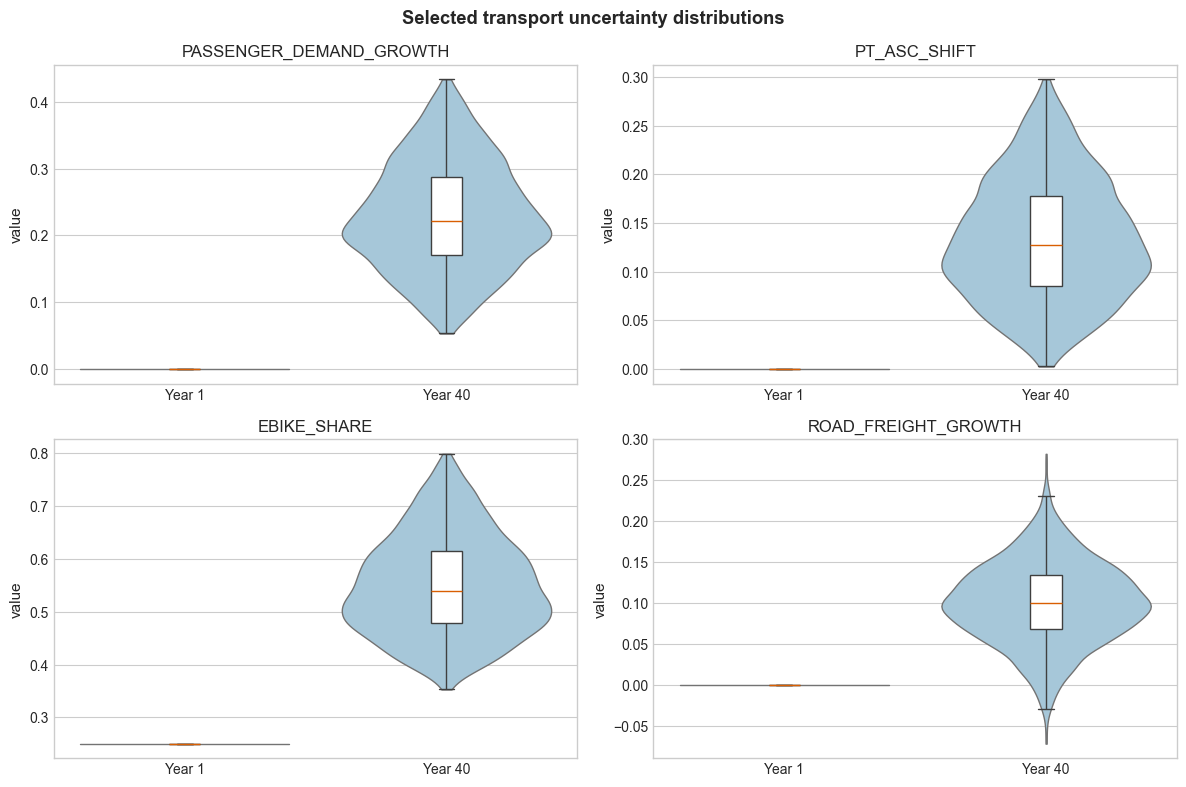

In [7]:
if TRANSPORT_UNCERTAINTY_NAMES:
    # Show the fixed baseline and the sampled final-year distribution.
    N_DIST = 3000
    rng = np.random.default_rng(0)
    n_rows = max(1, int(np.ceil(len(TRANSPORT_UNCERTAINTY_NAMES) / 2)))
    fig, axes = plt.subplots(n_rows, 2, figsize=(12, 4 * n_rows), squeeze=False)
    distribution_samples = []
    for ax, name in zip(axes.flat, TRANSPORT_UNCERTAINTY_NAMES):
        draws = rng.uniform(0, 1, N_DIST)
        y1 = np.array([uc.get_trajectory(name, u)[0] for u in draws])
        y40 = np.array([uc.get_trajectory(name, u)[-1] for u in draws])
        frame = pd.DataFrame({
            "value": np.r_[y1, y40],
            "year": ["Year 1"] * N_DIST + ["Year 40"] * N_DIST,
        })
        distribution_samples.append(frame.assign(parameter=name))
        sns.violinplot(data=frame, x="year", y="value", inner=None, cut=0, ax=ax,
                        color="#9ecae1", linewidth=1)
        sns.boxplot(data=frame, x="year", y="value", width=0.12, ax=ax,
                    showfliers=False, boxprops={"facecolor": "white", "zorder": 3},
                    whiskerprops={"zorder": 3}, medianprops={"color": "#d95f02", "zorder": 4})
        ax.set_title(name)
        ax.set_xlabel("")
    for ax in axes.flat[len(TRANSPORT_UNCERTAINTY_NAMES):]:
        ax.remove()
    plt.suptitle("Selected transport uncertainty distributions", fontweight="bold")
    plt.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_year1_vs_year40_violin.png").stem, figure=plt.gcf())
    exports.save_outputs("03_year1_vs_year40_violin", tables={"": pd.concat(distribution_samples, ignore_index=True)})
    plt.show()
else:
    print('No transport uncertainties selected for the distribution plot.')


# Part 3 - The fast transport surrogate model

## 3.1 Why use a surrogate? (tutorial/supporting task)

The transport model (coupled mode-choice and road-assignment model) is computationally expensive (i.e., it can take from a few minutes to multiple hours to run depending on the settings). A **Gaussian process (GP)** learns how its output changes across a sample of input combinations, so later scenario analysis can avoid repeating the full simulation.

We use **one GP for all four configurations**. Its current inputs are four uncertainties: `PASSENGER_DEMAND_GROWTH`, `PT_ASC_SHIFT`, `EBIKE_SHARE` and `ROAD_FREIGHT_GROWTH`, and four infrastructure states: baseline, stage 1, stage 2 and both stages.

The surrogate model approximates an OD matrix of extra car travel-time minutes caused by congestion. During preparation below, predicted delays update the car skims. The original five-mode choice, section counting and welfare appraisal then derive performance indicators and matched OD/submode summaries. These are saved in a response table.

The next build uses a fixed Latin-hypercube design, balanced across stages: 100 training simulations in total, with 20 extra validation simulations (20% of the training count). Validation uses five new physical input combinations at all four infrastructure states, so that project and baseline benefits can be compared at matching inputs.

The saved manifest records the training design, assignment stopping rule and validation results for the fitted surrogate model. The training domain comes from the uncertainty definitions in Part 2. The preparation cell below fits the GP and creates the response table used by this notebook and Notebooks 04–05.

The following two-dimensional example uses **16 points per method** in quantile space. It illustrates coverage; it is not the actual four-input, four-state training design.

- **Monte Carlo:** independent random draws can leave gaps and clusters.
- **Latin Hypercube:** exactly one point lies in each of the 16 intervals along each axis. This does not guarantee even coverage of the two-dimensional grid.
- **Sobol:** a scrambled low-discrepancy sequence balances coverage across dimensions. In this 16-point example, each of the 16 squares in the 4-by-4 grid contains one point.

The upper panels show joint coverage, with empty cells shaded. The lower panels show the axis counts that distinguish LHS from ordinary random sampling. All three designs sample uniform quantiles; the uncertainty distributions convert these to physical parameter values later.

cell running: 00:00

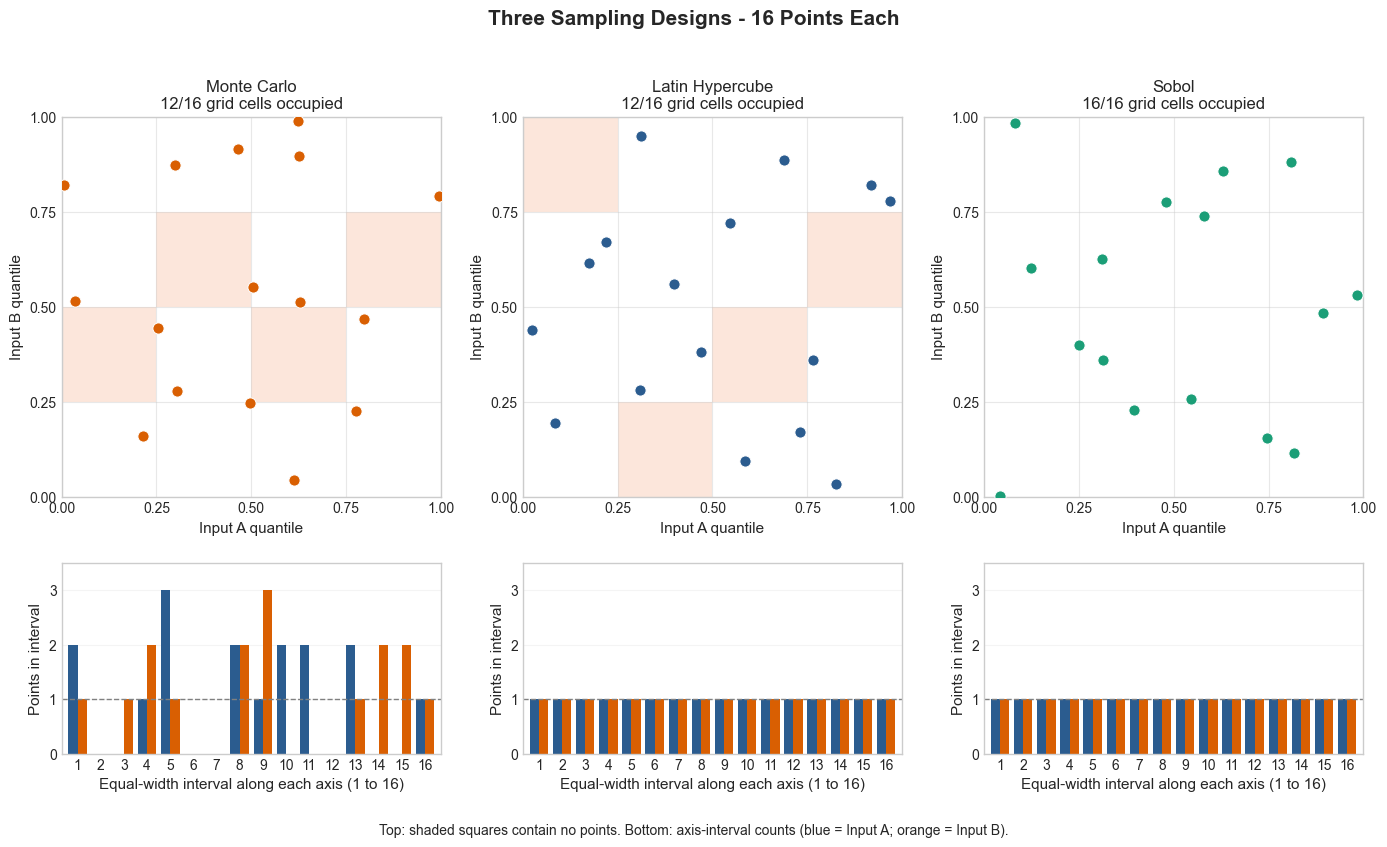

{'table:': WindowsPath('C:/Users/Enea/Documents/GitHub/IP-HS26-MehrSpur-CaseStudy-IP/results/03_uncertainty_modeling/03_sampling_preview.csv')}

In [8]:
# A small, reproducible 2D example: joint coverage above, axis coverage below.
from scipy.stats import qmc as _qmc_preview
from matplotlib.patches import Rectangle

PREVIEW_POWER = 4  # 2**4 = 16 points; Sobol balance uses powers of two.
N_PREVIEW = 2 ** PREVIEW_POWER
PREVIEW_SEED = 7
preview_designs = {
    "Monte Carlo": np.random.default_rng(PREVIEW_SEED).random((N_PREVIEW, 2)),
    "Latin Hypercube": _qmc_preview.LatinHypercube(d=2, seed=PREVIEW_SEED).random(N_PREVIEW),
    "Sobol": _qmc_preview.Sobol(d=2, scramble=True, seed=PREVIEW_SEED).random_base2(PREVIEW_POWER),
}

coarse_bins = np.linspace(0, 1, 5)
axis_bins = np.linspace(0, 1, N_PREVIEW + 1)
preview_colors = {"Monte Carlo": "#d95f02", "Latin Hypercube": "#2b5c8f", "Sobol": "#1b9e77"}
preview_counts = {}
for name, points in preview_designs.items():
    preview_counts[name] = {
        "grid": np.histogram2d(points[:, 0], points[:, 1], bins=(coarse_bins, coarse_bins))[0],
        "A": np.histogram(points[:, 0], bins=axis_bins)[0],
        "B": np.histogram(points[:, 1], bins=axis_bins)[0],
    }
max_axis_count = max(counts[axis].max() for counts in preview_counts.values() for axis in ("A", "B"))
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5), gridspec_kw={"height_ratios": [3, 1.3]})
for column, (name, points) in enumerate(preview_designs.items()):
    counts = preview_counts[name]
    ax = axes[0, column]
    for i in range(4):
        for j in range(4):
            if counts["grid"][i, j] == 0:
                ax.add_patch(Rectangle((i / 4, j / 4), .25, .25,
                                      facecolor="#fce6db", edgecolor="none", zorder=0))
    ax.scatter(points[:, 0], points[:, 1], s=65, color=preview_colors[name],
               edgecolors="white", linewidths=.7, zorder=3)
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xticks=coarse_bins, yticks=coarse_bins,
           xlabel="Input A quantile", ylabel="Input B quantile",
           title=f"{name}\n{np.count_nonzero(counts['grid'])}/16 grid cells occupied")
    ax.grid(alpha=.45, linestyle="-")
    ax.tick_params(labelsize=10)

    ax = axes[1, column]
    positions = np.arange(1, N_PREVIEW + 1)
    ax.bar(positions - .2, counts["A"], width=.4, color="#2b5c8f", label="Input A")
    ax.bar(positions + .2, counts["B"], width=.4, color="#d95f02", label="Input B")
    ax.axhline(1, color="gray", linestyle="--", linewidth=1)
    tick_step = max(1, N_PREVIEW // 16)
    ax.set(xlim=(.3, N_PREVIEW + .7), ylim=(0, max_axis_count + .5),
           xticks=positions[::tick_step], yticks=range(int(max_axis_count) + 1),
           xlabel=f"Equal-width interval along each axis (1 to {N_PREVIEW})",
           ylabel="Points in interval")
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", alpha=.2)
fig.suptitle(f"Three Sampling Designs - {N_PREVIEW} Points Each", fontsize=15, fontweight="bold")
fig.text(.5, .01, "Top: shaded squares contain no points. Bottom: axis-interval counts (blue = Input A; orange = Input B).",
         ha="center", fontsize=10)
fig.tight_layout(rect=(0, .04, 1, .95), h_pad=3.0)
exports.save_outputs(Path(FIGURES_DIR / "03_sampling_preview.png").stem, figure=fig)
plt.show()

exports.save_outputs("03_sampling_preview", tables={
    "": pd.concat([pd.DataFrame(points, columns=["input_A_quantile", "input_B_quantile"])
                    .assign(method=name, sample=np.arange(len(points)))
                    for name, points in preview_designs.items()], ignore_index=True),
})


### Adapting the surrogate to your project

The GP predicts **OD car congestion delays**, updated car skims then feed the mode-choice and welfare estimations, and finally results are stored in the **response table**.

**Where edits to the model go (a refresher)**

- Study area, nominal parameters, and transport uncertainty modelling: `code/parameters.py` (this also reshapes the GP training domain).
- Stage packages / interventions: `code/stages.py`.
- Deployment rules: `code/adaptive_planning.py`.

**What to re-run**

- **Rebuild the GP** (`REBUILD_TRANSPORT_SURROGATE`) if anything that changes road congestion response changes: transport inputs or their training domain, network/corridor data, stage definitions, or assignment settings. In case you want to add a new input that affects demand, mode choice, or assignment, this must also be wired into the surrogate builder. This is not expected nor necessary.
- **Refresh the response table only** (`REFRESH_RESPONSE_TABLE`) if the GP delays are still valid but you changed how reported performance indicators are extracted (e.g. adding PT share or CO₂-style outcomes), or the interpolation grid. Section 3.5 inspects those derived outcomes.

After a rebuild, inspect the saved diagnostics. Details: `code/surrogate_model/README.md`.

For the next rebuild, assignment checks the **feasible-road relative gap**: remaining excess vehicle travel time relative to current shortest routes. The default checks every four iterations after iteration eight and stops at 2%, with a cap of 64. Reaching the cap is reported separately. This road criterion can be tipically stricter in practice to ensure that transport simulations reach equilibrium.

**Preparation controls:**

`TRANSPORT_SURROGATE_WORKERS` sets the number of parallel training workers (default 4). Reduce it if memory is limited.

- Both flags `False`: load the saved response table; GP coefficients load only when needed.
- `REBUILD_TRANSPORT_SURROGATE = True`: train **100 cases total** (20 per configuration), validate on **20 separate cases**, and prepare the response table. Allow several hours. This takes precedence over the refresh flag.
- `REFRESH_RESPONSE_TABLE = True`, with rebuild `False`: recreate the response table from the saved GP, typically in about five minutes. Use this after changing a reported indicator, matched welfare summaries or the interpolation grid while the underlying transport response remains unchanged, or to replace a missing table.

Reset both flags to `False` after preparation. Missing or incompatible artifacts report an error; choose the relevant preparation flag explicitly. Validation findings remain advisory warnings.


In [9]:
from surrogate_model.build_transport_surrogate import build_transport_surrogate
from surrogate_model.response_table import prepare_response_table

SURROGATE_DIR = PROJECT_ROOT / "data" / "processed" / "transport_surrogate"
REBUILD_TRANSPORT_SURROGATE = False  # Train the GP and create its response table.
REFRESH_RESPONSE_TABLE = False      # Recreate only the table from the saved GP.
N_TRAIN = 100
VALIDATION_FRACTION = 0.20
TRANSPORT_SURROGATE_WORKERS = 4

# Optional uncertainty-guided MSA fill-in. The independent holdout remains fixed.
ADAPTIVE_FILL_IN = False
MAX_FILL_IN_POINTS = 20       # Total extra MSA cases across all stages.
FILL_IN_BATCH_SIZE = 4        # Refit and recheck the fixed holdout after each batch.
# Set a target to None to disable it. All enabled targets must be reached.
FILL_IN_TARGETS = {
    "weighted_mae_min": None,         # Absolute passenger-weighted OD MAE [min].
    "weighted_rmse_min": 0.20,        # Absolute passenger-weighted OD RMSE [min].
    "weighted_nrmse": None,           # RMSE / holdout truth RMS.
    "maximum_case_scaled_error": None, # Worst holdout-case RMSE / that case's truth RMS.
}

# Show transport validation here; monetary diagnostics are retained for Notebook 05.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=r"^Surrogate validation warning:", category=UserWarning)
    if REBUILD_TRANSPORT_SURROGATE:
        build_transport_surrogate(
            n_train=N_TRAIN, validation_fraction=VALIDATION_FRACTION, n_jobs=TRANSPORT_SURROGATE_WORKERS, seed=42,
            min_iterations=8, max_iterations=64, check_every=4,
            road_gap_threshold=0.02,
            adaptive_fill_in=ADAPTIVE_FILL_IN, max_fill_in_points=MAX_FILL_IN_POINTS,
            fill_in_batch_size=FILL_IN_BATCH_SIZE, fill_in_targets=FILL_IN_TARGETS,
        )

    elif REFRESH_RESPONSE_TABLE:
        prepare_response_table(PROJECT_ROOT, force=True, progress=True)

    # Load both saved artifacts; missing or stale files report an error.
    transport_emulator = load_transport_surrogate(PROJECT_ROOT, use_response_table=True)

# Report the transport findings separately from the shared appraisal diagnostics.
transport_validation = transport_emulator.manifest.get("validation", {}).get("od", {})
transport_findings = []
if transport_validation.get("passed") is False:
    transport_findings.append("OD-delay accuracy")
if transport_emulator.manifest.get("source_convergence_passed") is False:
    transport_findings.append("MSA reference convergence")
if transport_findings:
    warnings.warn("Transport validation warning: " + ", ".join(transport_findings)
                  + " did not meet the configured targets. Review Section 3.2.", UserWarning)
print("Shared transport response ready for Notebooks 03–05.")


cell running: 00:00

Shared transport response ready for Notebooks 03–05.


In [10]:
# Inspect the prepared model and define the snapshot calculations.
SURROGATE_MANIFEST = transport_emulator.manifest
SURROGATE_ARTIFACT_SHA256 = SURROGATE_MANIFEST["artifact_sha256"]
STATIC_PLANS = ["baseline", "static1", "static2"]
PLAN_STAGE = {name: plans_module.PLANS[name]["initial_stage"] for name in STATIC_PLANS}

def _paths_from_draws(draws):
    return uc.build_paths(draws)

# Canonical parameter keys pass directly from trajectories to the GP.
def _snapshot(stage, year_idx, paths):
    physical_inputs = uc.transport_surrogate_inputs_from_paths(paths, year_idx)
    g = float(uc.target_path(paths, "PASSENGER_DEMAND_GROWTH")[year_idx])
    transport_state = transport_emulator.predict_transport_state(
        stage=stage, **physical_inputs,
    )
    params = uc.year_parameters(paths, year_idx)
    metrics = transport_state["metrics"]
    physical = m.annual_physical_indicators(
        metrics, g, params=params,
        extra_delay=float(metrics.get("congestion_delay_hours", 0.0)),
        demand_scaled=True, stage=stage,
    )
    factors = m.annualizers(params)
    pt_trips = float(metrics["pt_trips"])
    pt_hours = sum(float(metrics[key]) for key in (
        "pt_tt_hours", "pt_wait_hours", "pt_access_hours",
        "pt_egress_hours", "pt_transfer_walk_hours",
    ))
    result = {
        **{key: float(metrics[key]) for key in (
            "car_share", "pt_share", "bike_share", "walk_share",
            "car_share_trips", "pt_share_trips", "bike_share_trips", "walk_share_trips",
        )},
        "pt_journey_time_min": 60.0 * pt_hours / pt_trips if pt_trips > 0 else np.nan,
        "avg_travel_time_min": physical["avg_tt_min"],
        "congestion_delay_hours": physical["congestion_delay_hours"],
        "co2_tonnes": physical["co2_tonnes"],
        "car_vehicle_km": float(metrics["car_vehicle_km"]) * factors["car"],
        "pt_daily_trips": pt_trips / float(params["PT_PEAK_SHARE"]),
        "total_peak_trips": sum(float(metrics[mode + "_trips"]) for mode in ("car", "pt", "bike", "walk")),
        "total_demand": sum(float(metrics[mode + "_trips"]) * factors[mode]
                            for mode in ("car", "pt", "bike", "walk")),
    }
    sf.external_flow_config(params)  # Validate external-flow settings even if the section is disabled.
    if sf.section_config(params)["active"]:
        # Reuse the engine's section flow/capacity rules; only physical results are reported.
        section = m._section_and_external_costs(metrics, 1.0, 1.0 + g, stage, params, factors)
        result.update({name: section[name] for name in (
            "section_reference_minutes", "section_modeled_daily",
            "section_external_daily", "section_combined_daily",
        )})
        if section["section_capacity_peak"] > 0:
            result["section_load_ratio"] = section["section_load_ratio"]
            result["section_crowding_penalty_min"] = (
                section["section_crowding_multiplier"] - 1.0) * section["section_reference_minutes"]
    return {name: result[name] for name in OUTCOME_BASE}



def forch_snapshot_model(plan="baseline", **draws):
    paths = _paths_from_draws(draws)
    stage = int(PLAN_STAGE.get(plan, 0))
    snapshots = {
        "y1": _snapshot(stage, 0, paths),
        "y40": _snapshot(stage, p.N_YEARS - 1, paths),
    }
    return {f"{key}_{year}": value for year, values in snapshots.items() for key, value in values.items()}

OUTCOME_BASE = [name for name in INDICATOR_CATALOG if indicator_available(name)]
OUTCOMES = [f"{name}_{year}" for name in OUTCOME_BASE for year in ("y1", "y40")]

nominal_by_stage = pd.DataFrame([
    {"plan": plan, **forch_snapshot_model(plan=plan)} for plan in STATIC_PLANS
])
show_table('03_nominal_stage_summary', nominal_by_stage[["plan", "pt_share_y40", "bike_share_trips_y40", "pt_journey_time_min_y40"]])
print(f"Loaded the surrogate for configurations {SURROGATE_MANIFEST['stages']}.")
construction_totals = {
    plan: sum(stages_module.construction_emissions_tonnes(package)
              for package, active in enumerate(stages_module.stage_components(PLAN_STAGE[plan]), start=1)
              if active)
    for plan in STATIC_PLANS
}
print("Package construction emissions (total tonnes; separate from annual operating snapshots):")
show_table('03_construction_co2', pd.Series(construction_totals, name="Construction CO2 (tonnes)").to_frame())


def evaluate_design(model, count, sampler, policies=None):
    """Sample selected uncertainties, or evaluate each nominal plan once."""
    if not list(model.uncertainties):
        rows, values = [], []
        for policy in policies or [None]:
            arguments = {} if policy is None else dict(policy)
            rows.append({"scenario": 0, "policy": "nominal" if policy is None else policy.name, **arguments})
            values.append(model.function(**arguments))
        return pd.DataFrame(rows), {name: np.array([value[name] for value in values]) for name in OUTCOMES}
    with SequentialEvaluator(model) as evaluator:
        options = {} if policies is None else {"policies": policies}
        return perform_experiments(model, count, evaluator=evaluator,
                                   uncertainty_sampling=sampler, log_progress=False, **options)

exports.save_outputs("03_nominal_stage_outcomes", tables={"": nominal_by_stage})


cell running: 00:00

,plan,pt_share_y40,bike_share_trips_y40,pt_journey_time_min_y40
0,baseline,0.182431,0.143878,35.961811
1,static1,0.183703,0.143629,35.817256
2,static2,0.183933,0.143529,35.766531


Loaded the surrogate for configurations [0, 1, 2, 3].
Package construction emissions (total tonnes; separate from annual operating snapshots):


,Construction CO2 (tonnes)
baseline,0.0
static1,0.0
static2,0.0


{'table:': WindowsPath('C:/Users/Enea/Documents/GitHub/IP-HS26-MehrSpur-CaseStudy-IP/results/03_uncertainty_modeling/03_nominal_stage_outcomes.csv')}

## 3.2 How accurate is the OD-delay approximation? (mandatory task)

Compare the GP’s predictions with the full assignment results saved for hold-out input combinations that were not used to fit the GP. Read the error table, observed-versus-predicted plot and residual plot together. Errors are in **minutes**. Demand weights give busier OD relations more influence. Small average errors can hide a difficult case or a biased project-versus-baseline difference.

These plots read saved validation arrays only, so they do not rerun the traffic assignment or mode choice. If a transport accuracy or assignment-convergence threshold is missed, the notebook provides a warning and still lets you inspect the results. Review these warnings when you interpret later sections.

This section shows transport checks. Monetary benefit diagnostics are saved during preparation for review in Notebook 05.


In [11]:
# Read saved evidence, not new simulations.
VALIDATION_PACKAGE = load_surrogate_validation(PROJECT_ROOT)
VALIDATION_CASES = VALIDATION_PACKAGE["cases"].copy()
OD_ACTUAL = np.asarray(VALIDATION_PACKAGE["actual"])
OD_PREDICTED = np.asarray(VALIDATION_PACKAGE["mean"])
OD_WEIGHTS = np.asarray(VALIDATION_PACKAGE["weights"], dtype=float).reshape(OD_ACTUAL.shape[1:])
OD_WEIGHTS = OD_WEIGHTS / OD_WEIGHTS.sum()
transport_diagnostics = transport_emulator.describe().drop(columns=["appraisal_diagnostics"], errors="ignore")
show_table('03_transport_diagnostics', transport_diagnostics)
show_table('03_validation_cases', VALIDATION_CASES)
print(f"Saved validation: {len(VALIDATION_PACKAGE['ids'])} stage/input cases.")
from surrogate_model.transport_surrogate import artifact_status
SURROGATE_STATUS = artifact_status(PROJECT_ROOT)
print(f"GP: {SURROGATE_STATUS['gp_status']}; response table: {SURROGATE_STATUS['response_status']}")


cell running: 00:00

,stage,n_training,n_validation,weighted_mae_min,weighted_rmse_min,od_passed,reference_convergence_passed
0,0,25,5,0.010905,0.024508,True,True
1,1,25,5,0.016596,0.038918,True,True
2,2,25,5,0.010628,0.024330,True,True
3,3,25,5,0.010733,0.022465,True,True


,id,stage,weighted_mae_min,weighted_rmse_min,weighted_observed_delay_min,weighted_predicted_delay_min
0,test_000_stage0,0,0.018652,0.042925,2.883848,2.901030
1,test_000_stage1,1,0.023025,0.054263,2.879262,2.897592
2,test_000_stage2,2,0.018875,0.040219,2.882561,2.897071
3,test_000_stage3,3,0.015963,0.032496,2.877942,2.890243
4,test_001_stage0,0,0.010839,0.020431,3.344425,3.348907
5,test_001_stage1,1,0.020644,0.049302,3.339239,3.359044
6,test_001_stage2,2,0.012221,0.026855,3.342732,3.352844
7,test_001_stage3,3,0.014495,0.029246,3.337931,3.351270
8,test_002_stage0,0,0.008551,0.016483,3.217533,3.219732
9,test_002_stage1,1,0.011079,0.020880,3.212964,3.214862


Saved validation: 20 stage/input cases.
GP: ready; response table: ready


cell running: 00:00

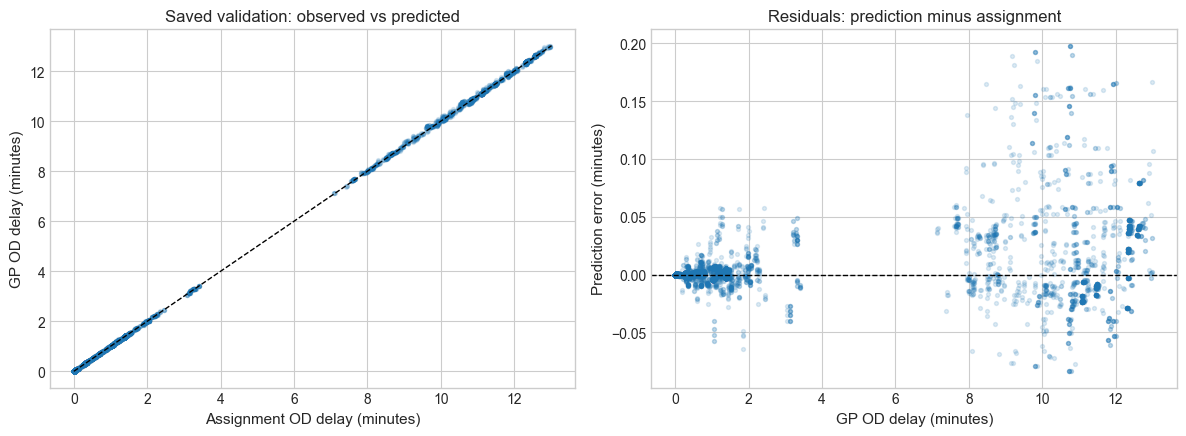

In [12]:
# A small reproducible demand-weighted sample keeps the plots readable.
# The reported MAE/RMSE still use all OD pairs, not this plotting sample.
plot_rng = np.random.default_rng(42)
sample_od = plot_rng.choice(OD_WEIGHTS.size, size=400, replace=True, p=OD_WEIGHTS.ravel())
observed_plot = OD_ACTUAL.reshape(len(OD_ACTUAL), -1)[:, sample_od].ravel()
predicted_plot = OD_PREDICTED.reshape(len(OD_PREDICTED), -1)[:, sample_od].ravel()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(observed_plot, predicted_plot, s=8, alpha=.15)
upper = max(float(observed_plot.max()), float(predicted_plot.max()))
axes[0].plot([0, upper], [0, upper], "k--", lw=1)
axes[0].set(xlabel="Assignment OD delay (minutes)", ylabel="GP OD delay (minutes)", title="Saved validation: observed vs predicted")
axes[1].scatter(predicted_plot, predicted_plot - observed_plot, s=8, alpha=.15)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="GP OD delay (minutes)", ylabel="Prediction error (minutes)", title="Residuals: prediction minus assignment")
plt.tight_layout()
exports.save_outputs(Path(FIGURES_DIR / "03_od_validation.png").stem, figure=plt.gcf())
exports.save_outputs("03_od_validation", tables={"sample": pd.DataFrame({
    "validation_case": np.repeat(VALIDATION_PACKAGE["ids"], len(sample_od)),
    "flat_od_index": np.tile(sample_od, len(OD_ACTUAL)),
    "assignment_delay_min": observed_plot, "predicted_delay_min": predicted_plot,
})})
plt.show()


cell running: 00:00

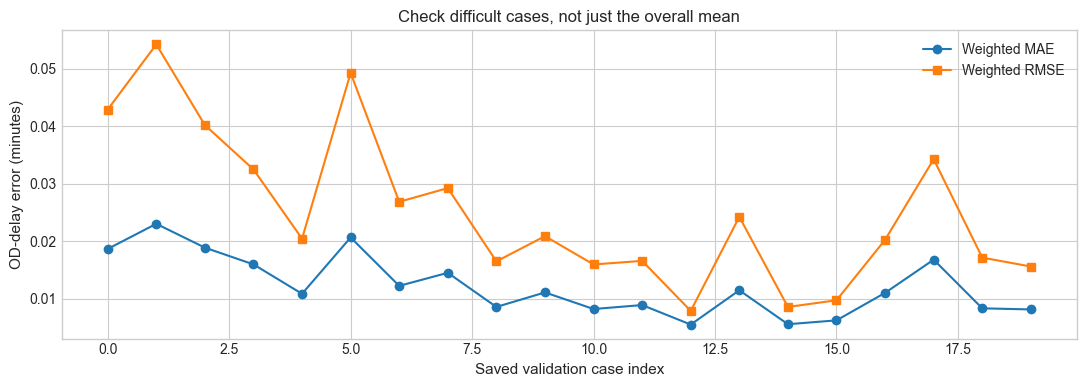

In [13]:
# Full-matrix, demand-weighted errors for each saved validation case.
case_mae = np.array([np.sum(np.abs(pred - actual) * OD_WEIGHTS)
                     for actual, pred in zip(OD_ACTUAL, OD_PREDICTED)])
case_rmse = np.array([np.sqrt(np.sum((pred - actual) ** 2 * OD_WEIGHTS))
                      for actual, pred in zip(OD_ACTUAL, OD_PREDICTED)])
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(case_mae, "o-", label="Weighted MAE")
ax.plot(case_rmse, "s-", label="Weighted RMSE")
ax.set(xlabel="Saved validation case index", ylabel="OD-delay error (minutes)", title="Check difficult cases, not just the overall mean")
ax.legend()
plt.tight_layout()
exports.save_outputs("03_validation_case_errors", figure=fig, tables={"": pd.DataFrame({
    "validation_case": VALIDATION_PACKAGE["ids"], "weighted_mae_min": case_mae,
    "weighted_rmse_min": case_rmse,
})})
plt.show()


## 3.3 Inspect an OD relation (advanced task)

The table below identifies OD pairs contributing most to the demand-weighted error in one saved case. An origin or destination can be a zone or boundary gate. These are road-delay predictions; PT, cycling and walking demand is calculated later by the native mode-choice model. A large local error might deserve inspection even if the overall average is small.


In [14]:
SELECTED_VALIDATION_CASE = 0  # choose an index shown in the previous plot
case_index = int(SELECTED_VALIDATION_CASE)
if not 0 <= case_index < len(OD_ACTUAL):
    raise ValueError("Select an existing validation case index.")
case_actual = OD_ACTUAL[case_index]
case_prediction = OD_PREDICTED[case_index]
case_error = case_prediction - case_actual
top_flat = np.argsort((np.abs(case_error) * OD_WEIGHTS).ravel())[-15:][::-1]
origins, destinations = np.unravel_index(top_flat, case_actual.shape)
od_labels = np.asarray(VALIDATION_PACKAGE["labels"])
print("Saved case:", VALIDATION_PACKAGE["ids"][case_index])
show_table('03_selected_validation_od_errors', pd.DataFrame({
    "origin": od_labels[origins], "destination": od_labels[destinations],
    "assignment_delay_min": case_actual[origins, destinations],
    "predicted_delay_min": case_prediction[origins, destinations],
    "error_min": case_error[origins, destinations],
    "demand_weight": OD_WEIGHTS[origins, destinations],
}).assign(validation_case=VALIDATION_PACKAGE["ids"][case_index]))


cell running: 00:00

Saved case: test_000_stage0


,origin,destination,assignment_delay_min,predicted_delay_min,error_min,demand_weight,validation_case
0,G15,G01,10.646233,10.800643,0.154410,0.018829,test_000_stage0
1,G15,G40,10.591476,10.752803,0.161326,0.017192,test_000_stage0
2,G15,G18,1.060172,1.066773,0.006601,0.319777,test_000_stage0
3,G11,G40,9.639294,9.794687,0.155394,0.007913,test_000_stage0
4,G11,G01,9.694050,9.842526,0.148477,0.004502,test_000_stage0
5,G15,G06,11.014882,11.127263,0.112381,0.003798,test_000_stage0
6,G40,G18,11.112932,11.106651,-0.006281,0.046412,test_000_stage0
7,G15,G25,10.068259,10.171508,0.103249,0.002432,test_000_stage0
8,G15,G30,9.537344,9.638976,0.101632,0.002391,test_000_stage0
9,G15,G43,10.491512,10.597492,0.105980,0.001699,test_000_stage0


cell running: 00:00

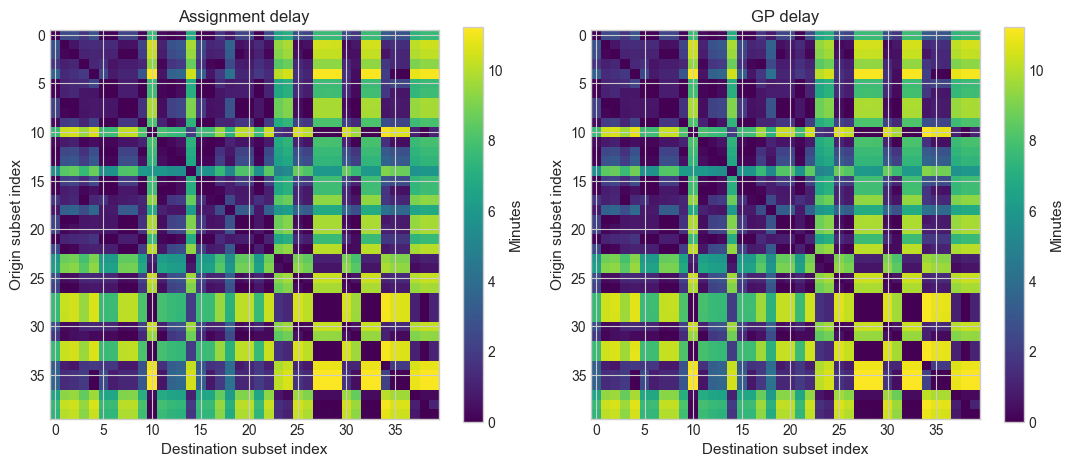

In [15]:
# Inspect the same busiest OD subset in both matrices. 
busy = np.argsort(OD_WEIGHTS.sum(axis=0) + OD_WEIGHTS.sum(axis=1))[-40:]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
extent = float(max(case_actual[np.ix_(busy, busy)].max(), case_prediction[np.ix_(busy, busy)].max()))
for ax, values, title in zip(axes, (case_actual, case_prediction), ("Assignment delay", "GP delay")):
    picture = ax.imshow(values[np.ix_(busy, busy)], vmin=0, vmax=max(extent, 1e-9), cmap="viridis")
    ax.set(title=title, xlabel="Destination subset index", ylabel="Origin subset index")
    fig.colorbar(picture, ax=ax, label="Minutes")
plt.tight_layout()
subset_origins, subset_destinations = np.meshgrid(busy, busy, indexing="ij")
exports.save_outputs("03_validation_od_matrices", figure=fig, tables={"": pd.DataFrame({
    "validation_case": VALIDATION_PACKAGE["ids"][case_index],
    "origin": od_labels[subset_origins.ravel()], "destination": od_labels[subset_destinations.ravel()],
    "assignment_delay_min": case_actual[np.ix_(busy, busy)].ravel(),
    "predicted_delay_min": case_prediction[np.ix_(busy, busy)].ravel(),
})})
plt.show()


## 3.4 Keep the evidence and its limits visible

The input domain below is the physical range where the surrogate may be queried (the GP training domain from Part 2). Staying inside those bounds  means you are not asking the surrogate model to extrapolate far outside its training box.

Bear in mind that there are multiple error sources:

- **Surrogate fit error**: how well the fitted OD-delay model matches hold-out assignment runs (Section 3.2–3.3).
- **Response-table interpolation**: a second approximation when planning queries look up prepared indicators. The saved GP diagnostics do not measure this interpolation error. The response table has been designed so the error is minimal.
- **Upstream model and data limits**: incomplete MSA convergence, missing links, uncertain inputs, or wrong capacity/crowding assumptions. The diagnostic checks do not catch these.

In [16]:
show_table('03_surrogate_input_domain', pd.DataFrame(SURROGATE_MANIFEST["input_domain"]).T)
print("Surrogate method:", SURROGATE_MANIFEST["method"])
print("Artifact fingerprint:", SURROGATE_MANIFEST["model_fingerprint"])
print("The saved manifest records the actual training and validation provenance.")

cell running: 00:00

,minimum,maximum,nominal
PASSENGER_DEMAND_GROWTH,0.000000,0.440000,0.00
PT_ASC_SHIFT,0.000000,0.300000,0.00
EBIKE_SHARE,0.250000,0.800000,0.25
ROAD_FREIGHT_GROWTH,-0.054512,0.254512,0.00


Surrogate method: Pooled one-hot ARD Matérn-5/2 GP of full directional OD delays; no PCA
Artifact fingerprint: bac1b45d8da80bcf9eba
The saved manifest records the actual training and validation provenance.


## 3.5 From OD delays to reported outcomes

The response table interpolates performance indicators and matched welfare summaries prepared from the GP and native mode-choice model. Select a stage and indicators below to inspect nominal Year-1 outcomes. Annual conversions, external passengers and crowding use the shared model rules.

Indicators derived from quantities already stored in the response table need no table refresh or GP retraining. A new calculation requiring additional stored transport quantities needs a response-table refresh; adding a catalogue name alone does not implement it.


In [17]:
INSPECT_STAGE = 0
INSPECT_INDICATORS = ["pt_share", "bike_share_trips", "walk_share_trips", "pt_journey_time_min", "co2_tonnes"]
inspection = _snapshot(INSPECT_STAGE, 0, uc.nominal_paths())
selected = select_indicators(INSPECT_INDICATORS)
show_table('03_nominal_inspection', pd.DataFrame([
    {"indicator": key, "value": inspection[key], "unit": INDICATOR_CATALOG[key]["unit"],
     "definition": INDICATOR_CATALOG[key]["definition"]}
    for key in selected
], columns=["indicator", "value", "unit", "definition"]).set_index("indicator"))
print("Nominal Year-1 physical outcomes from the shared response table; share values are fractions.")


cell running: 00:00

,value,unit,definition
indicator,,,
pt_share,0.172620,%,Common-distance-weighted PT share for reportin...
bike_share_trips,0.127829,%,Share of reporting-area modeled peak person-tr...
walk_share_trips,0.264093,%,Share of reporting-area modeled peak person-tr...
pt_journey_time_min,36.381419,min/trip,In-vehicle + waiting + access + egress + trans...
co2_tonnes,45955.439648,tonnes/year,Passenger-car and supplied rail-service operat...


Nominal Year-1 physical outcomes from the shared response table; share values are fractions.


## 3.6 Minimal worked example: two selected inputs (tutorial/supporting task)

Later figures need a **2D slice** of the inputs so that coverage and outcomes are easy to plot.

- This example uses the two scenario keys `PASSENGER_DEMAND_GROWTH` and `PT_ASC_SHIFT`.
- All other scenario keys stay on their nominal paths for this demo.
- If fewer than two scenario keys are selected, the 2D plots below are skipped.

In [18]:
ema_model_2d = Model("Forch2D", function=forch_snapshot_model)
ema_model_2d.uncertainties = [RealParameter(name, 0.0, 1.0) for name in DEMO_UNCERTAINTIES]
ema_model_2d.outcomes = [ScalarOutcome(o) for o in OUTCOMES]
print("Teaching subset:", DEMO_UNCERTAINTIES)

cell running: 00:00

Teaching subset: ['PASSENGER_DEMAND_GROWTH', 'PT_ASC_SHIFT']


## 3.7 Full uncertainty model: all selected scenario inputs (mandatory task)

The full model registers every selected scenario uncertainty. Transport inputs enter the GP/MSA response. Post-modelling (e.g., appraisal) inputs and analytics are then applied to the resulting transport state. Assumptions with `use="sensitivity"` remain nominal here and are tested separately in Notebook 05.

In [19]:
N_SCENARIOS = 1000
ema_model_full = Model("ForchPhysical", function=forch_snapshot_model)
ema_model_full.uncertainties = [RealParameter(name, 0.0, 1.0) for name in SCENARIO_NAMES]
ema_model_full.outcomes = [ScalarOutcome(o) for o in OUTCOMES]
U_COLS_FULL = [u.name for u in ema_model_full.uncertainties]
print(f"Full model: {len(U_COLS_FULL)} uncertainties ({len(TRANSPORT_UNCERTAINTY_NAMES)} transport + {len(POST_UNCERTAINTY_NAMES)} post-modelling).")

cell running: 00:00

Full model: 9 uncertainties (4 transport + 5 post-modelling).


# Part 4 — How we generate future scenarios

## 4.1 Compare sampling designs in a visible 2D example (tutorial/supporting task)

To explore a wide range of scenarios, a efficient sampling strategy is key so we dont need to run a combinatorial set of simulations (which could be in the order of thousands or millions). The EMA Workbench supports several experimental designs:

* **Monte Carlo (MC)**: Independent random uniform draws. Simple, but can leave un-sampled gaps or create redundant clusters, especially with a low number of runs.
* **Latin Hypercube Sampling (LHS)**: Stratifies each parameter into equal-probability bins and guarantees even marginal coverage along every single axis. Usually the preferred default for exploratory modeling.
* **Sobol/Saltelli sensitivity design**: EMA expands paired Sobol sequences to estimate variance contributions. The second-order design has $N \times (2D + 2)$ rows, where $D$ is the number of uncertainties and $N$ is a power-of-two base sample. These dependent rows can repeat points. This differs from the ordinary Sobol sequence shown in the preview.

Below, we run an `N_SCENARIOS` experiment on the 2D core model to compare how these algorithms cover the parameter space.

cell running: 00:00

100%|█████████████████████████████████████| 1536/1536 [00:07<00:00, 194.74it/s]


Simulation Runs Generated:
  • Monte Carlo     : 2000 evaluations; 2000 distinct points
  • Latin Hypercube : 2000 evaluations; 2000 distinct points
  • Sobol           : 1536 evaluations; 1024 distinct points


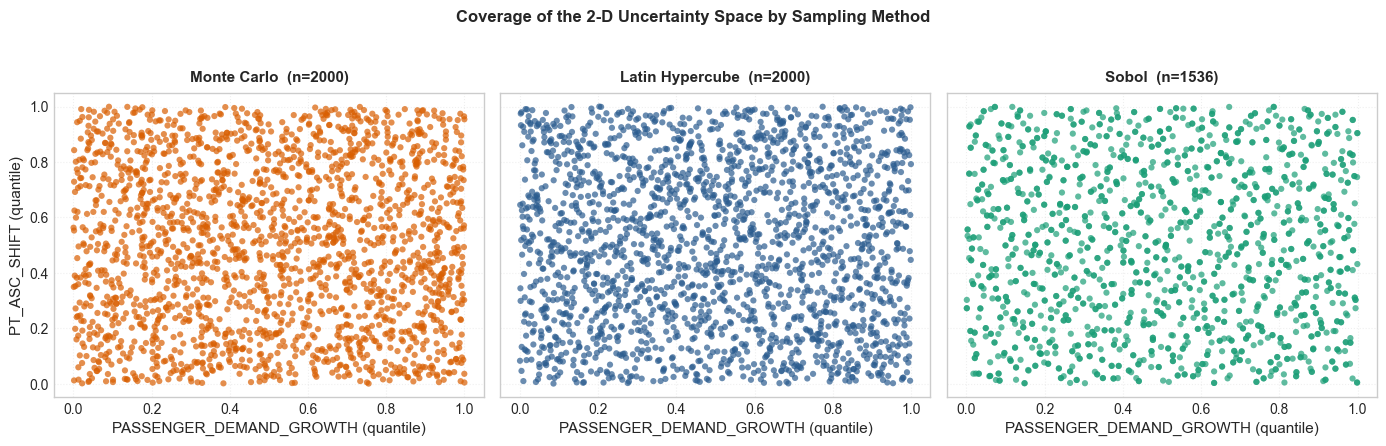

Sobol here is an expanded sensitivity design; repeated points serve variance estimation.


In [20]:
N_SCENARIOS = 2000
colors = {"Monte Carlo": "#d95f02", "Latin Hypercube": "#2b5c8f", "Sobol": "#1b9e77"}
sampling_results_2d = {}
if HAS_TWO_INPUTS:
    # Compare three sampling strategies (Monte Carlo, Latin Hypercube, Sobol) on
    # how evenly they cover a 2D uncertainty slice (PASSENGER_DEMAND_GROWTH x PT_ASC_SHIFT).
    # Sobol's run count is fixed by its N*(2D+2) saltelli scheme, not chosen freely.
    sampling_results_2d = {}

    for label, sampler, count in [("Monte Carlo", Samplers.MC, N_SCENARIOS),
                                  ("Latin Hypercube", Samplers.LHS, N_SCENARIOS),
                                  ("Sobol", Samplers.SOBOL, 2 ** max(1, int(np.floor(np.log2(max(2, N_SCENARIOS // 6))))))]:
        experiments, outcomes = evaluate_design(ema_model_2d, count, sampler)
        frame = experiments.copy()
        for name, values in outcomes.items():
            frame[name] = values
        sampling_results_2d[label] = frame
        exports.save_outputs(f"03_sampling_2d_{label}", tables={"": frame})

    # 3. Print counts and visualize the 2D coverage
    print("Simulation Runs Generated:")
    for label, df in sampling_results_2d.items():
        print(f"  • {label:<16}: {len(df)} evaluations; {len(df[DEMO_UNCERTAINTIES].drop_duplicates())} distinct points")

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharex=True, sharey=True)

    for ax, (label, df) in zip(axes, sampling_results_2d.items()):
        ax.scatter(df[X_DEMO], df[Y_DEMO], s=20, alpha=0.7, color=colors[label], edgecolors="none")
        ax.set_title(f"{label}  (n={len(df)})", fontsize=11, fontweight="bold", pad=8)
        ax.set_xlabel(X_DEMO + " (quantile)")
        ax.grid(alpha=0.3, linestyle=":")
    
    axes[0].set_ylabel(Y_DEMO + " (quantile)")

    plt.suptitle("Coverage of the 2-D Uncertainty Space by Sampling Method", y=1.03, fontsize=12, fontweight="bold")
    plt.tight_layout()

    # Save figure
    figures_path = FIGURES_DIR / "03_sampling_coverage_2d.png"
    exports.save_outputs(Path(figures_path).stem, figure=plt.gcf())
    plt.show()

    print("Sobol here is an expanded sensitivity design; repeated points serve variance estimation.")
else:
    print('Two-input sampling demonstration skipped: select at least two scenario uncertainties.')


## 4.2 Does the estimated outcome mean stabilize? (tutorial/supporting task)

Choose `CONVERGENCE_INDICATOR` below; the default is Year-40 PT share. The running means compare Monte Carlo, Latin Hypercube and Sobol designs. Their pooled mean is a finite-design reference, not a known population value.


cell running: 00:00

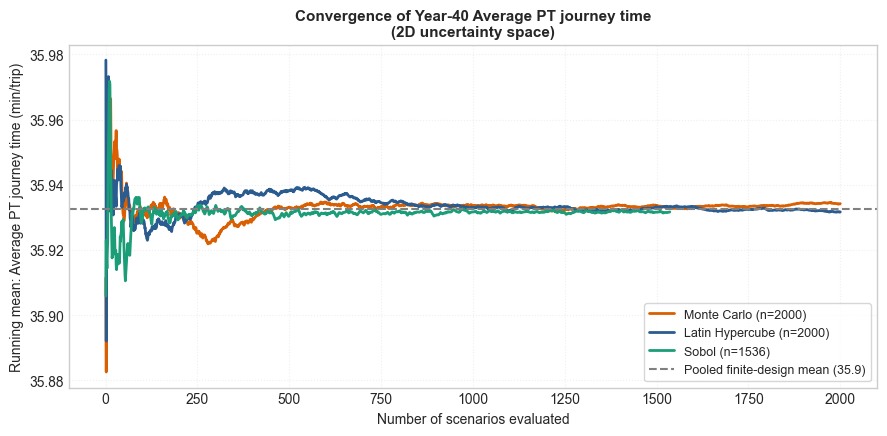

In [21]:
CONVERGENCE_INDICATOR = "pt_journey_time_min"  # Any available catalogue key.
select_indicators([CONVERGENCE_INDICATOR], required=True)
CONVERGENCE_OUTCOME = f"{CONVERGENCE_INDICATOR}_y40"

def running_mean(series):
    return series.expanding().mean()

if HAS_TWO_INPUTS:
    # Track each sampler's running mean of the selected outcome as scenarios are
    # added, to see which method's estimate settles down (converges) fastest.
    fig, ax = plt.subplots(figsize=(9, 4.5))

    # 1. Plot running means for all samplers
    for label, color in colors.items():
        df = sampling_results_2d[label]
    
        ax.plot(
            range(1, len(df) + 1),
            running_mean(df[CONVERGENCE_OUTCOME]),
            color=color,
            linewidth=2,
            label=f"{label} (n={len(df)})",
        )

    # 2. Pooled finite-design benchmark (not a known true population mean)
    all_results = pd.concat(
        [df[CONVERGENCE_OUTCOME] for df in sampling_results_2d.values()],
        ignore_index=True,
    )
    reference_mean = all_results.mean()

    ax.axhline(
        reference_mean,
        color="grey",
        linestyle="--",
        linewidth=1.5,
        label=f"Pooled finite-design mean ({indicator_format(reference_mean, CONVERGENCE_INDICATOR)})"
    )

    # 3. Formatting
    ax.set_xlabel("Number of scenarios evaluated", fontsize=10)
    ax.set_ylabel("Running mean: " + indicator_label(CONVERGENCE_INDICATOR), fontsize=10)
    ax.set_title(f"Convergence of Year-40 {INDICATOR_CATALOG[CONVERGENCE_INDICATOR]['label']}\n(2D uncertainty space)", fontsize=11, fontweight="bold")
    ax.legend(fontsize=9, loc="lower right", frameon=True)
    ax.grid(alpha=0.3, linestyle=":")

    # Formatter for percentage y-axis
    import matplotlib.ticker as mtick
    format_indicator_axis(ax, CONVERGENCE_INDICATOR)

    plt.tight_layout()
    figures_path = FIGURES_DIR / "03_sampling_convergence_2d.png"
    exports.save_outputs(Path(figures_path).stem, figure=plt.gcf())
    exports.save_outputs("03_sampling_convergence_2d", tables={"": pd.concat([
        pd.DataFrame({"method": label, "evaluation": np.arange(1, len(frame) + 1),
                      "outcome": CONVERGENCE_OUTCOME, "running_mean": running_mean(frame[CONVERGENCE_OUTCOME]).to_numpy(),
                      "pooled_reference_mean": reference_mean})
        for label, frame in sampling_results_2d.items()], ignore_index=True)})
    plt.show()
else:
    print('Two-input convergence plot skipped.')


## 4.3 Convergence in the full uncertainty space (tutorial/supporting task)

The full experiment uses the selected transport and post-modelling scenarios.
Sobol's required run count grows as $N(2D+2)$, where $D$ is the number of
selected uncertainties. Coverage comparisons use equal numbers of design points.
With no uncertainties selected, each plan is evaluated once on nominal paths.


cell running: 00:00

c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\code\additional\uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)
100%|█████████████████████████████████████| 2000/2000 [00:11<00:00, 172.57it/s]
c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\code\additional\uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)
100%|█████████████████████████████████████| 1280/1280 [00:06<00:00, 183.30it/s]


D = 9 uncertainties.
Sobol/Saltelli design: N=64, 1280 rows.
For a robust analysis, N=512 would require 10,240 runs for a single plan!


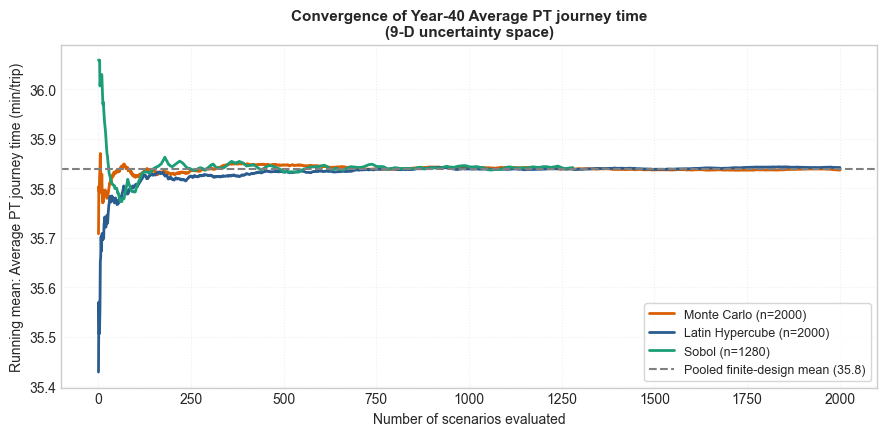

In [22]:
# Repeat the sampler-convergence comparison, but now across the FULL set of
# structural uncertainties (not just the 2D demand/PT-preference slice), to
# see how the run-count cost of Sobol explodes with dimensionality D.
sampling_results_full = {}

N_SOBOL_FULL = 2 ** max(1, int(np.floor(np.log2(max(2, N_SCENARIOS // (2 * len(SCENARIO_NAMES) + 2))))))
for label, sampler, count in [("Monte Carlo", Samplers.MC, N_SCENARIOS),
                              ("Latin Hypercube", Samplers.LHS, N_SCENARIOS),
                              ("Sobol", Samplers.SOBOL, N_SOBOL_FULL)]:
    experiments, outcomes = evaluate_design(ema_model_full, count, sampler)
    frame = experiments.copy()
    for name, values in outcomes.items():
        frame[name] = values
    sampling_results_full[label] = frame
    exports.save_outputs(f"03_sampling_full_{label}", tables={"": frame})

# 3. Print design summary
n_uncertainties = len(ema_model_full.uncertainties)
print(f"D = {n_uncertainties} uncertainties.")
if n_uncertainties:
    print(f"Sobol/Saltelli design: N={N_SOBOL_FULL}, {len(sampling_results_full['Sobol'])} rows.")
else:
    print("No uncertain inputs selected: each design evaluates the nominal path once.")
print(f"For a robust analysis, N=512 would require {512 * (2 * n_uncertainties + 2):,} runs for a single plan!")

# 4. Visualize convergence
fig, ax = plt.subplots(figsize=(9, 4.5))

for label, color in colors.items():
    df = sampling_results_full[label]
    
    ax.plot(
        range(1, len(df) + 1),
        running_mean(df[CONVERGENCE_OUTCOME]),
        color=color,
        linewidth=2,
        label=f"{label} (n={len(df)})",
    )

all_results = pd.concat(
    [df[CONVERGENCE_OUTCOME] for df in sampling_results_full.values()],
    ignore_index=True,
)
reference_mean = all_results.mean()

ax.axhline(
    reference_mean,
    color="grey",
    linestyle="--",
    linewidth=1.5,
    label=f"Pooled finite-design mean ({indicator_format(reference_mean, CONVERGENCE_INDICATOR)})"
)

ax.set_xlabel("Number of scenarios evaluated", fontsize=10)
ax.set_ylabel("Running mean: " + indicator_label(CONVERGENCE_INDICATOR), fontsize=10)
ax.set_title(f"Convergence of Year-40 {INDICATOR_CATALOG[CONVERGENCE_INDICATOR]['label']}\n({n_uncertainties}-D uncertainty space)", fontsize=11, fontweight="bold")
ax.legend(fontsize=9, loc="lower right", frameon=True)
ax.grid(alpha=0.3, linestyle=":")
format_indicator_axis(ax, CONVERGENCE_INDICATOR)

plt.tight_layout()
figures_path = FIGURES_DIR / "03_sampling_convergence_full.png"
exports.save_outputs(Path(figures_path).stem, figure=plt.gcf())
exports.save_outputs("03_sampling_convergence_full", tables={"": pd.concat([
    pd.DataFrame({"method": label, "evaluation": np.arange(1, len(frame) + 1),
                  "outcome": CONVERGENCE_OUTCOME, "running_mean": running_mean(frame[CONVERGENCE_OUTCOME]).to_numpy(),
                  "pooled_reference_mean": reference_mean})
    for label, frame in sampling_results_full.items()], ignore_index=True)})
plt.show()


## 4.4 Quantifying coverage and discrepancy (advanced task)

The full design samples every selected scenario uncertainty. A plot can still show only two axes at a time, so coverage must also be checked in the full space.

Two diagnostics are reported:

- **Discrepancy** measures how far the sample departs from uniform coverage. Lower is better.
- **Mean pairwise grid coverage** averages, over every 2D projection of the inputs, the fraction of grid cells that contain at least one point. Higher is better.

The above two metrics help judge whether the sampling design fills the uncertainty space evenly.

cell running: 00:00

,n_total,n_compared,n_distinct,fullD_discrepancy,fullD_coverage,2D_discrepancy,2D_coverage
method,,,,,,,
Monte Carlo,2000,1280,1280,0.0044,1.0000,0.0003,1.0000
Latin Hypercube,2000,1280,1280,0.0028,1.0000,0.0002,1.0000
Sobol,1280,1280,1280,0.0090,0.9347,0.0001,0.9000


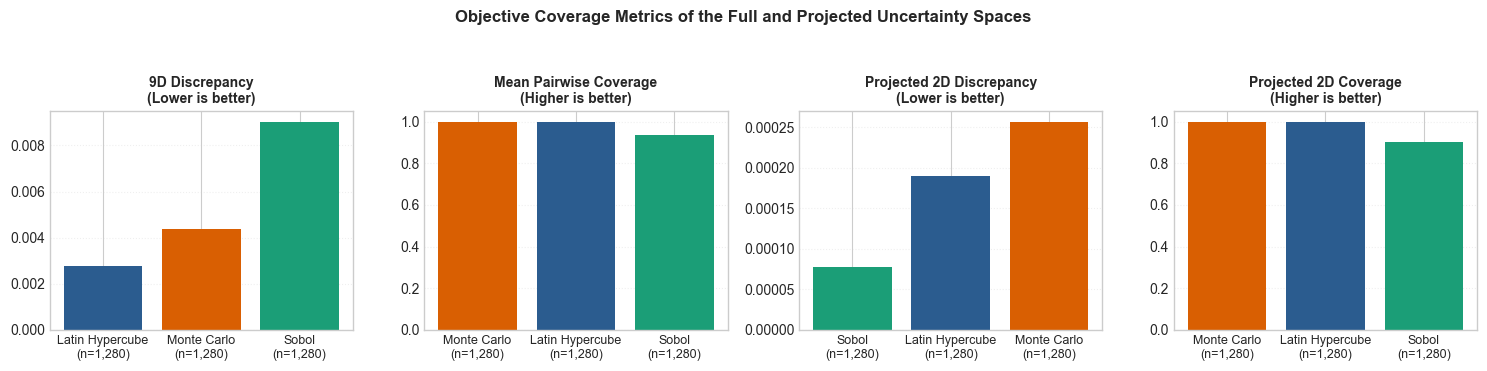

Each metric uses 1280 evaluation rows; distinct-point counts differ for expanded designs. Rankings are descriptive.


In [23]:
if HAS_TWO_INPUTS:
    # Quantify design quality beyond a 2D picture: discrepancy (lower = more
    # evenly spread) and grid-occupancy coverage (higher = fewer empty cells),
    # computed both in the full D-dimensional space and reprojected to 2D, on
    # equal-size subsets so the comparison isn't just rewarding a larger n.
    from itertools import combinations
    from scipy.stats import qmc

    def grid_coverage(X, bins=10):
        """Calculates the percentage of bins occupied by at least one sample."""
        cells = np.floor(X * bins).clip(0, bins - 1).astype(int)
        return len(np.unique(cells, axis=0)) / (bins ** X.shape[1])

    rows = []
    n_equal = min(len(df) for df in sampling_results_full.values())
    coverage_rng = np.random.default_rng(2026)

    for method, df in sampling_results_full.items():
        # Compare equal-size subsets: discrepancy and occupancy improve mechanically
        # with n, so using each design's full (unequal) run count would be unfair.
        take = coverage_rng.choice(len(df), size=n_equal, replace=False)
        compared = df.iloc[np.sort(take)]
        X_full = compared[U_COLS_FULL].to_numpy()
        X_2 = compared[[X_DEMO, Y_DEMO]].to_numpy()

        # Calculate coverage for all possible 2D pairs in the active space
        pair_coverages = [
            grid_coverage(X_full[:, [i, j]])
            for i, j in combinations(range(X_full.shape[1]), 2)
        ]

        rows.append({
            "method": method,
            "n_total": len(df),
            "n_compared": n_equal,
            "n_distinct": len(compared[U_COLS_FULL].drop_duplicates()),
            "fullD_discrepancy": qmc.discrepancy(X_full),
            "fullD_coverage": np.mean(pair_coverages),
            "2D_discrepancy": qmc.discrepancy(X_2),
            "2D_coverage": grid_coverage(X_2),
        })

    comparison = pd.DataFrame(rows).set_index("method")
    show_table('03_sampling_coverage_metrics', comparison.style.format(precision=4))

    # ---------------------------------------------------------
    # Plotting the metrics
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))

    metrics = {
        "fullD_discrepancy": f"{n_uncertainties}D Discrepancy\n(Lower is better)",
        "fullD_coverage": "Mean Pairwise Coverage\n(Higher is better)",
        "2D_discrepancy": "Projected 2D Discrepancy\n(Lower is better)",
        "2D_coverage": "Projected 2D Coverage\n(Higher is better)",
    }

    for ax, (metric, title) in zip(axes, metrics.items()):
        # Discrepancy sorts ascending (lower is better); Coverage sorts descending (higher is better)
        ascending = "discrepancy" in metric
        order = comparison[metric].sort_values(ascending=ascending).index
        labels = [f"{x}\n(n={comparison.loc[x, 'n_compared']:,})" for x in order]

        ax.bar(labels, comparison.loc[order, metric], color=[colors[x] for x in order])
        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.tick_params(axis="x", labelsize=9)
        ax.grid(axis="y", alpha=0.3, linestyle=":")

    plt.suptitle("Objective Coverage Metrics of the Full and Projected Uncertainty Spaces", y=1.05, fontsize=12, fontweight="bold")
    plt.tight_layout()

    figures_path = FIGURES_DIR / "03_sampling_coverage_metrics.png"
    exports.save_outputs(Path(figures_path).stem, figure=plt.gcf())
    plt.show()

    print(f"Each metric uses {n_equal} evaluation rows; distinct-point counts differ for expanded designs. Rankings are descriptive.")
else:
    print('Two-input comparison skipped: select at least two scenario uncertainties.')


---

## 4.5 Establishing the working dataset (mandatory task)

From here through Part 6, we use one reusable Latin Hypercube dataset named `df_baseline`: all uncertainty draws are evaluated on the **baseline plan only**. Part 7 later creates a different dataset, `df_plan`, which evaluates shared draws across `baseline`, `static1`, and `static2`. The similar names therefore refer to different table structures and should not be conflated.

In [24]:
# Reuse the full LHS sample, or generate it if the optional comparison was skipped.
if "sampling_results_full" in globals() and "Latin Hypercube" in sampling_results_full:
    df_baseline = sampling_results_full["Latin Hypercube"].copy()
else:
    experiments, outcomes = evaluate_design(ema_model_full, N_SCENARIOS, Samplers.LHS)
    df_baseline = experiments.assign(**outcomes)
n_uncertainties = len(U_COLS_FULL)
print(f"✅ Working dataset established: {len(df_baseline)} scenarios x {n_uncertainties} uncertainties")
print(f"   (baseline plan, Year 1 + Year 40 snapshots).")
exports.save_outputs("03_baseline_experiments", tables={"": df_baseline})
# Select a compact summary; all available outcomes remain in df_baseline.
WORKING_SUMMARY_INDICATORS = ["pt_share", "bike_share_trips", "congestion_delay_hours", "co2_tonnes", "pt_journey_time_min"]
summary_keys = select_indicators(WORKING_SUMMARY_INDICATORS, df_baseline)
show_table('03_baseline_summary', df_baseline[U_COLS_FULL + [f"{key}_y40" for key in summary_keys]].describe().style.format(precision=3))

cell running: 00:00

✅ Working dataset established: 2000 scenarios x 9 uncertainties
   (baseline plan, Year 1 + Year 40 snapshots).


,PASSENGER_DEMAND_GROWTH,PT_ASC_SHIFT,EBIKE_SHARE,ROAD_FREIGHT_GROWTH,CAR_CO2_KG_PER_VEHICLE_KM,OPEX_MULTIPLIER,CAPEX_MULTIPLIER,ACCIDENT_COST_MULTIPLIER,LOCAL_AIR_COST_MULTIPLIER,pt_share_y40,bike_share_trips_y40,congestion_delay_hours_y40,co2_tonnes_y40,pt_journey_time_min_y40
count,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000
mean,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.185,0.148,760024.944,20787.106,35.842
std,0.289,0.289,0.289,0.289,0.289,0.289,0.289,0.289,0.289,0.007,0.008,84659.889,2945.399,0.183
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.167,0.132,544864.034,11400.861,35.201
25%,0.250,0.250,0.250,0.250,0.250,0.250,0.250,0.250,0.250,0.180,0.142,697882.212,18721.854,35.714
50%,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.185,0.146,750435.034,20700.113,35.856
75%,0.750,0.750,0.750,0.750,0.750,0.750,0.750,0.750,0.750,0.190,0.153,817061.962,22707.433,35.982
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.205,0.169,1028436.179,31660.466,36.297


## 4.6 Visual overview of the working dataset (tutorial/supporting task)

Select the inputs and outcomes using `HISTOGRAM_UNCERTAINTIES` and `HISTOGRAM_INDICATORS` below. These histograms show **physical Year-40 input values** and Year-40 outcomes for the baseline plan. Each sampled quantile is converted with the same trajectory mapping and transport bounds used by the model, so triangular and normal assumptions appear in their physical units. The original quantiles remain the inputs for sensitivity analysis and PRIM.

Dashed orange lines show means and dotted black lines show medians. A fixed value appears as a line rather than a distribution. Year 1 is used as a reference in Part 5.


cell running: 00:00

c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\code\additional\uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)
c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\matplotlib\_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\matplotlib\_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\matplotlib\_mathtext.py:2010: PyparsingDeprecati

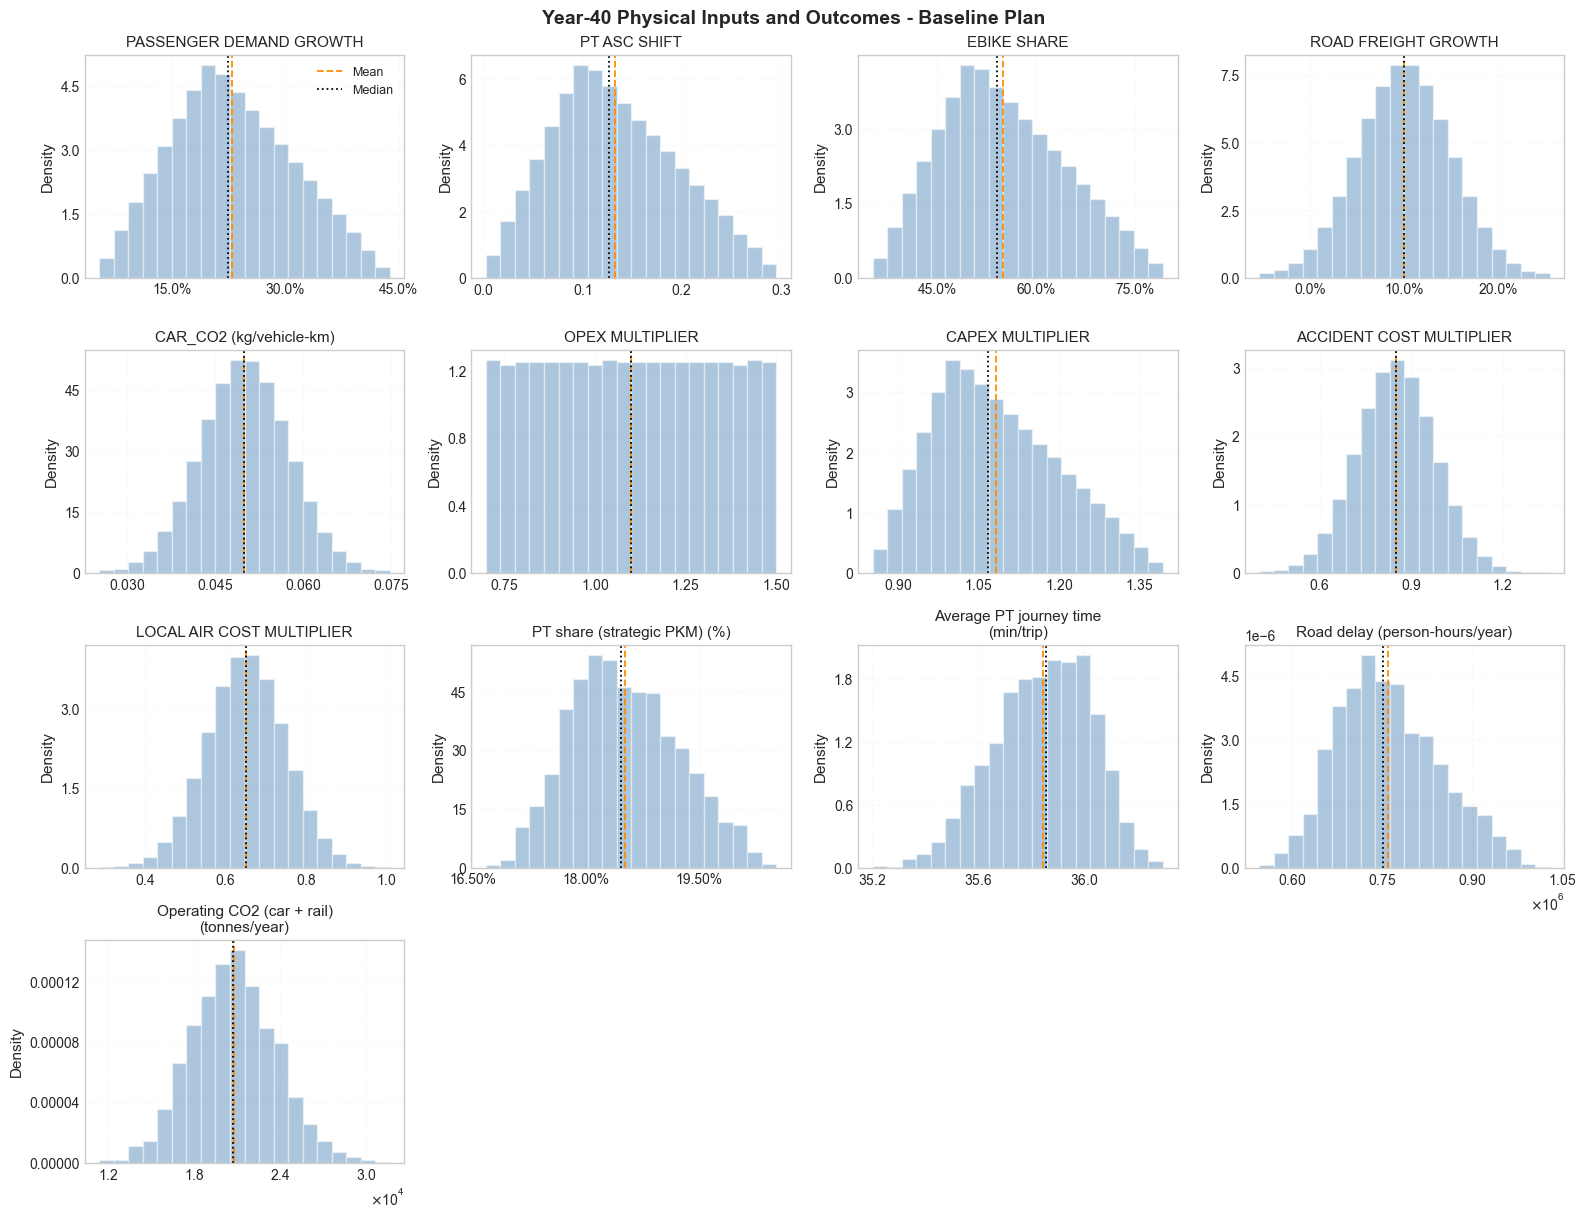

In [25]:
# Convert quantiles to physical endpoints for this display only.
from textwrap import fill

HISTOGRAM_UNCERTAINTIES = U_COLS_FULL.copy()  # Or a subset of the sampled keys.
HISTOGRAM_INDICATORS = ["pt_share", "pt_journey_time_min", "congestion_delay_hours", "co2_tonnes"]
histogram_indicators = select_indicators(HISTOGRAM_INDICATORS, df_baseline)
unknown = set(HISTOGRAM_UNCERTAINTIES) - set(U_COLS_FULL)
if unknown:
    raise ValueError(f"Histogram uncertainties must be sampled keys: {sorted(unknown)}")
physical_rows = []
for draws in df_baseline[U_COLS_FULL].itertuples(index=False, name=None):
    paths = _paths_from_draws(dict(zip(U_COLS_FULL, draws)))
    physical_rows.append({name: uc.target_path(paths, name)[-1] for name in U_COLS_FULL})
physical_inputs_y40 = pd.DataFrame(physical_rows, index=df_baseline.index, columns=U_COLS_FULL)
plot_cols = HISTOGRAM_UNCERTAINTIES + [f"{name}_y40" for name in histogram_indicators]
plot_frame = pd.concat([physical_inputs_y40, df_baseline[[name for name in plot_cols if name not in U_COLS_FULL]]], axis=1)

histogram_labels = {f"{key}_y40": indicator_label(key) for key in histogram_indicators}
histogram_labels["CAR_CO2_KG_PER_VEHICLE_KM"] = "CAR_CO2 (kg/vehicle-km)"
percentage_inputs = {"PASSENGER_DEMAND_GROWTH", "ROAD_FREIGHT_GROWTH", "EBIKE_SHARE"}
if plot_cols:
    n_cols = 4
    n_rows = int(np.ceil(len(plot_cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.1 * n_rows))
    axes = np.asarray(axes).ravel()
    
    for ax, col in zip(axes, plot_cols):
        values = plot_frame[col].dropna()
        if has_variation(values):
            ax.hist(values, bins=20, density=True, color="steelblue", alpha=0.45, edgecolor="white")
        else:
            val = values.mean()
            padding = max(abs(val) * .05, .05)
            ax.set_xlim(val - padding, val + padding)
            ax.text(.97, .92, "Fixed", transform=ax.transAxes, ha="right", va="top")
        ax.axvline(values.mean(), color="darkorange", linestyle="--", linewidth=1.3, label="Mean")
        ax.axvline(values.median(), color="black", linestyle=":", linewidth=1.3, label="Median")
        ax.set_title(fill(histogram_labels.get(col, col.replace("_", " ")), width=30), fontsize=11)
        ax.xaxis.set_major_locator(mtick.MaxNLocator(nbins=4))
        ax.yaxis.set_major_locator(mtick.MaxNLocator(nbins=4))
        if col in percentage_inputs or (col.endswith("_y40") and INDICATOR_CATALOG[col[:-4]].get("format") == "percent"):
            ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
        else:
            ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, 4), useMathText=True)
        ax.set_ylabel("Density" if has_variation(values) else "")
        ax.grid(alpha=0.2, linestyle=":")
    
    for ax in axes[len(plot_cols):]:
        ax.remove()
    axes[0].legend(fontsize=9, loc="best")
    fig.suptitle("Year-40 Physical Inputs and Outcomes - Baseline Plan", fontsize=14, fontweight="bold")
    fig.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_baseline_distributions.png").stem, figure=fig)
    exports.save_outputs("03_baseline_distributions", tables={"": plot_frame[plot_cols]})
    plt.show()
else:
    print("No histogram indicators or uncertainties selected.")


## 4.7 Mapping outcomes onto the uncertainty space (tutorial/supporting task)

Choose `SCATTER_INDICATORS` below to colour the sampled futures by Year-40 outcomes. The axes are the two selected demonstration uncertainty quantiles. Use these plots to identify combinations associated with favourable or unfavourable outcomes.


cell running: 00:00

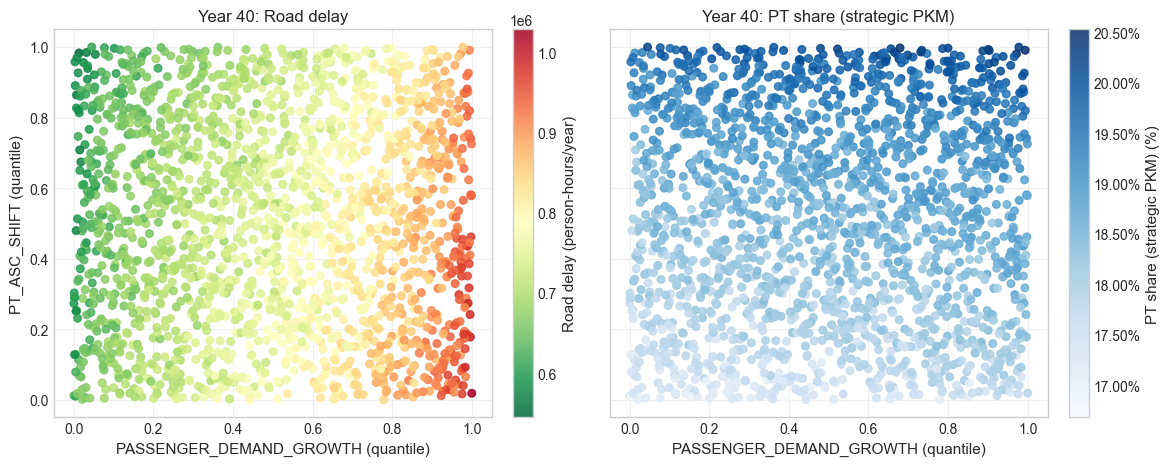

In [26]:
SCATTER_INDICATORS = ["congestion_delay_hours", "pt_share"]
scatter_indicators = select_indicators(SCATTER_INDICATORS, df_baseline)
if HAS_TWO_INPUTS and scatter_indicators:
    fig, axes = plt.subplots(1, len(scatter_indicators), figsize=(6 * len(scatter_indicators), 4.8),
                             squeeze=False, sharex=True, sharey=True)
    for ax, key in zip(axes.flat, scatter_indicators):
        spec = INDICATOR_CATALOG[key]
        cmap = "RdYlGn_r" if spec["direction"] == "lower" else "Blues"
        sc = ax.scatter(df_baseline[X_DEMO], df_baseline[Y_DEMO],
                        c=df_baseline[f"{key}_y40"], cmap=cmap, s=30, alpha=.85)
        ax.set(title="Year 40: " + spec["label"], xlabel=X_DEMO + " (quantile)")
        ax.grid(alpha=.3)
        cbar = fig.colorbar(sc, ax=ax, pad=.04)
        cbar.set_label(indicator_label(key))
        if spec.get("format") == "percent":
            cbar.ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    axes[0, 0].set_ylabel(Y_DEMO + " (quantile)")
    fig.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_lhs_scenario_space_outcomes.png").stem, figure=fig)
    exports.save_outputs("03_lhs_scenario_space_outcomes", tables={"": df_baseline[
        ["scenario", X_DEMO, Y_DEMO] + [f"{key}_y40" for key in scatter_indicators]]})
    plt.show()
else:
    print("Choose at least two scenario inputs and one available scatter indicator.")


# Part 5 - What range of outcomes is plausible?

## 5.1 Summarize the baseline outcome range (mandatory task)

Compare the baseline plan's starting values with the Year-40 spread. Select the indicators below using catalogue keys; cycling and walking shares include short trips when the `_share_trips` keys are used.

Average PT journey time includes in-vehicle time, waiting, access, egress and transfer walking for modeled passengers. It excludes crowding and supplementary passengers. It can change because service changes or because a different mix of journeys uses PT. Road delay is shown separately. See the catalogue for the populations and units of the other indicators.


cell running: 00:00

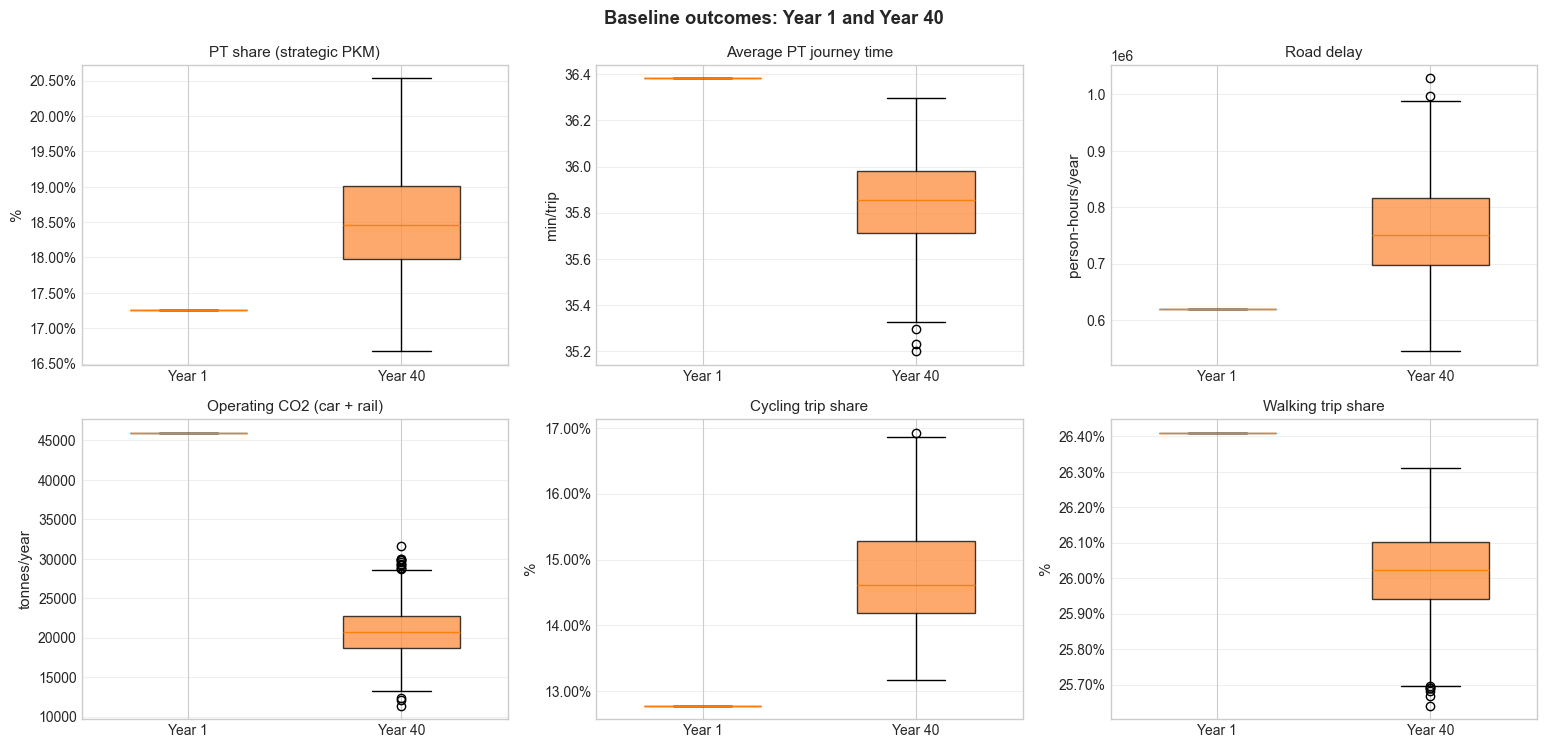

In [27]:
# These choices also set the default for the Year-40 violins in 5.2.
DISTRIBUTION_INDICATORS = [
    "pt_share", "pt_journey_time_min", "congestion_delay_hours", "co2_tonnes",
    "bike_share_trips", "walk_share_trips",
]
distribution_indicators = select_indicators(DISTRIBUTION_INDICATORS, df_baseline)
if distribution_indicators:
    n_cols = min(3, len(distribution_indicators))
    n_rows = int(np.ceil(len(distribution_indicators) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.8 * n_rows), squeeze=False)
    for ax, key in zip(axes.flat, distribution_indicators):
        data = [df_baseline[f"{key}_{year}"].dropna() for year in ("y1", "y40")]
        bp = ax.boxplot(data, tick_labels=["Year 1", "Year 40"], patch_artist=True, widths=.55)
        for box, color in zip(bp["boxes"], ("#9ecae1", "#fd8d3c")):
            box.set_facecolor(color)
            box.set_alpha(.75)
        ax.set_title(INDICATOR_CATALOG[key]["label"], fontsize=11)
        ax.set_ylabel(INDICATOR_CATALOG[key]["unit"])
        format_indicator_axis(ax, key)
        ax.grid(axis="y", alpha=.3)
    for ax in axes.flat[len(distribution_indicators):]:
        ax.remove()
    fig.suptitle("Baseline outcomes: Year 1 and Year 40", fontweight="bold")
    fig.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_baseline_year1_vs_year40_summary.png").stem, figure=fig)
    exports.save_outputs("03_baseline_year1_vs_year40_summary", tables={"": df_baseline[
        ["scenario"] + [f"{key}_{year}" for key in distribution_indicators for year in ("y1", "y40")]]})
    plt.show()
else:
    print("No available distribution indicators selected.")


## 5.2 Year-40 outcome distributions and Year-1 references (mandatory task)

The orange violins show Year-40 outcome distributions for the baseline plan, with quartile marks inside. Blue markers show the Year-1 reference. Under the current settings, physical outcomes are fixed in Year 1. If initial uncertainty is introduced, the blue marker shows the median and its vertical bar shows the 10th-90th percentile range.

Each indicator is min-max normalized to $[0, 1]$ using values pooled across both years. This keeps the starting reference and future distribution on the same scale. A constant indicator is placed at 0.5. The distance from the reference shows the direction and size of change relative to that indicator's sampled range; the violin shows its Year-40 spread. These normalized distances do not compare absolute magnitudes across indicators.

The shapes describe the sampled experiment, not a forecast of real-world probabilities.


cell running: 00:00

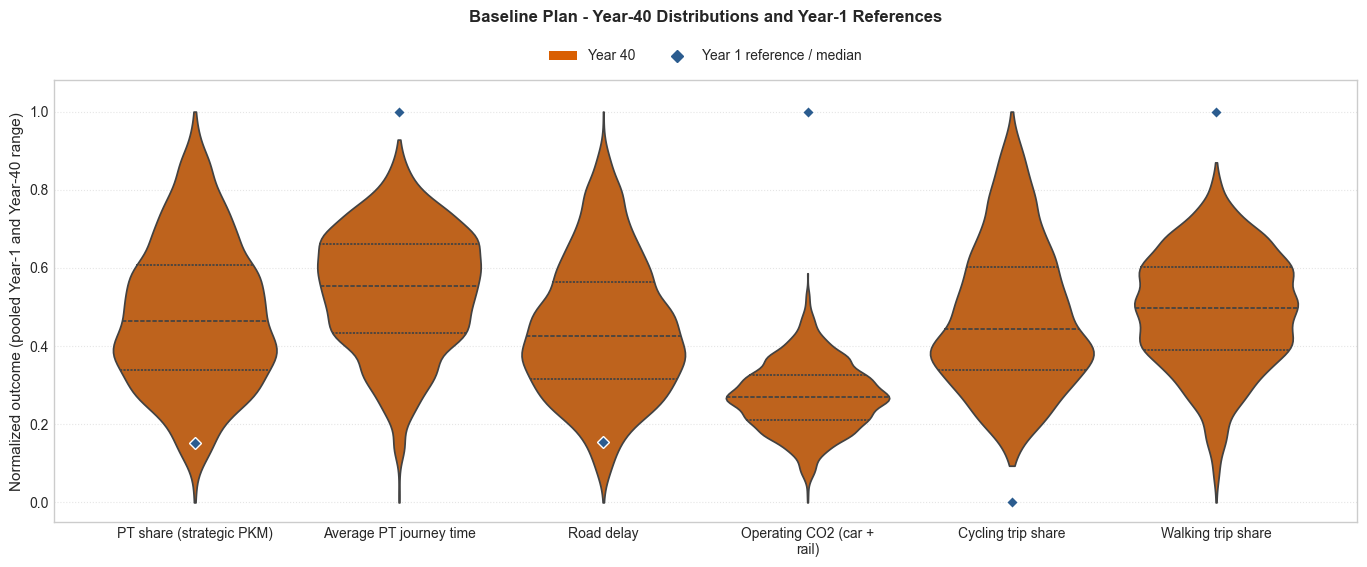

In [28]:
# Year-40 distributions with Year-1 references on shared normalized scales.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

VIOLIN_INDICATORS = DISTRIBUTION_INDICATORS.copy()  # Or choose a different catalogue subset.
PARCOORD_OBJS = select_indicators(VIOLIN_INDICATORS, df_baseline)
from textwrap import fill
PARCOORD_LABELS = {key: fill(INDICATOR_CATALOG[key]["label"], 24) for key in PARCOORD_OBJS}

long_rows, year1_references, constant_endpoints, normalization_rows = [], [], [], []
for obj in PARCOORD_OBJS:
    y1 = df_baseline[f"{obj}_y1"].dropna().to_numpy()
    y40 = df_baseline[f"{obj}_y40"].dropna().to_numpy()
    pooled = np.r_[y1, y40]
    lo, hi = pooled.min(), pooled.max()
    normalization_rows.append({"indicator": obj, "minimum": lo, "maximum": hi})
    if hi > lo:
        y1_norm, y40_norm = (y1 - lo) / (hi - lo), (y40 - lo) / (hi - lo)
    else:
        y1_norm, y40_norm = np.full_like(y1, .5), np.full_like(y40, .5)
    label = PARCOORD_LABELS[obj]
    # Constant outcomes use markers: a density is not defined for one value.
    if has_variation(y40):
        long_rows.extend({"objective": label, "norm_value": value} for value in y40_norm)
    else:
        constant_endpoints.append((label, float(np.median(y40_norm))))
    if len(y1_norm):
        year1_references.append((label, *np.quantile(y1_norm, [.1, .5, .9])))

parcoord_df = pd.DataFrame(long_rows, columns=["objective", "norm_value"])
labels = [PARCOORD_LABELS[obj] for obj in PARCOORD_OBJS]
if PARCOORD_OBJS:
    fig, ax = plt.subplots(figsize=(max(12, 2.3 * len(PARCOORD_OBJS)), 5.8))
    if not parcoord_df.empty:
        sns.violinplot(
            data=parcoord_df, x="objective", y="norm_value", order=labels,
            inner="quart", density_norm="width", common_norm=False,
            bw_adjust=0.8, cut=0, color="#d95f02", ax=ax,
        )
    for label, value in constant_endpoints:
        ax.plot(labels.index(label), value, marker="_", markersize=24,
                markeredgewidth=3, color="#d95f02", linestyle="none", zorder=4)
    for label, low, median, high in year1_references:
        position = labels.index(label)
        ax.vlines(position, low, high, color="#2b5c8f", linewidth=2, zorder=5)
        ax.plot(position, median, marker="D", markersize=6, color="#2b5c8f",
                markeredgecolor="white", linestyle="none", zorder=6)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_ylim(-.05, 1.08)
    ax.set_ylabel("Normalized outcome (pooled Year-1 and Year-40 range)")
    ax.set_xlabel("")
    ax.set_title("Baseline Plan - Year-40 Distributions and Year-1 References", fontweight="bold", pad=42)
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.legend(handles=[
        Patch(facecolor="#d95f02", label="Year 40"),
        Line2D([], [], color="#2b5c8f", marker="D", linestyle="none", label="Year 1 reference / median"),
    ], loc="lower center", bbox_to_anchor=(.5, 1.01), ncol=2)
    fig.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_parcoords_violin.png").stem, figure=fig)
    exports.save_outputs("03_parcoords_violin", tables={
        "year40": parcoord_df,
        "year1_references": pd.DataFrame(year1_references, columns=["objective", "p10", "median", "p90"]),
        "fixed_year40": pd.DataFrame(constant_endpoints, columns=["objective", "value"]),
        "normalization": pd.DataFrame(normalization_rows),
    })
    plt.show()
else:
    print("No available violin indicators selected.")


# Part 6 — Which uncertain drivers explain the outcome spread?

*"Which uncertainties matter most?"*

Given the futures already evaluated, sensitivity analysis can be used to understand which uncertain inputs best explain why the outcomes differ? We use three complementary methods:

1. **Feature Scoring**: a fast, non-parametric screening pass across the physical-outcome uncertainties (mandatory).
2. **Morris screening**: a structured, efficient method to narrow the parameters down to key drivers (advanced).
3. **Sobol $S_1$ / $S_T$ indices**: a formal, variance-based global sensitivity analysis on the prioritised subset (advanced).

**An important distinction:** Feature Scoring (using an Extra-Trees regressor) evaluates *"how useful is this input for predicting the output variation"*, acting as a fast proxy for sensitivity. Morris asks whether an input has a large average effect and whether that effect varies through non-linearity or interaction. Sobol indices directly measure *"what fraction of the output's variance is explained by this input"*. These numbers are not interchangeable. Feature Scoring scores as should be read as the **"normalised relative importance"** of the uncertainties, which is different from the "percentage of variance explained" (which is reserved for a Sobol analysis).

| | What it actually measures | Cost (model evaluations) | Separates interactions? |
|---|---|---|---|
| **Feature Scoring** | Predictive usefulness of an input for an Extra-Trees model fit to the *already-sampled* data (reuses `df_baseline`, no new runs) | Free (reuses existing sample) | No — one score per input, interactions are invisible |
| **Morris screening** | Mean absolute elementary effect ($\mu^*$) and its spread ($\sigma$) from small, structured one-at-a-time steps | Cheap: $N 	imes (D+1)$ | Only flags that interactions/non-linearity *might* be present (via large $\sigma$), doesn't quantify them |
| **Sobol indices** | Formal variance decomposition: what share of output variance is attributable to each input (and combination of inputs) | Expensive: $N 	imes (2D+2)$ | Yes — explicitly, via $S_1$, $S_2$, and $S_T$ (below) |

**Sobol's three index types** (this is the only method in this notebook that actually decomposes variance):
- **$S_1$ (first-order):** the share of output variance explained by this input *acting alone*, averaged over all the others.
- **$S_2$ (second-order):** the *additional* share explained by a specific *pair* of inputs acting together, beyond what each explains alone — i.e. a genuine interaction effect between exactly those two.
- **$S_T$ (total-order):** the share explained by this input alone plus *every* interaction it participates in (with any other input, not just pairs). $S_T \geq S_1$ always; a large gap $S_T - S_1$ means this input matters mostly *through* interactions, not on its own.

We use these three methods as a funnel — Feature Scoring is a free first look, Morris cheaply narrows the full input set down to the ones worth a formal Sobol run, and Sobol is the only one that can actually tell you *how much* of the variance is interaction rather than direct effect.

---

## 6.1 Feature scoring: Year-40 outcomes (mandatory task)

Using the locked `df_baseline` sample, Extra Trees ranks how useful each selected scenario uncertainty is for predicting **the selected Year-40 indicators**. With fixed initial conditions there is no Year-1 physical-outcome spread to explain. Every input is eligible at each tree split (`max_features=1.0`), with a fixed random seed. The chart shows **normalised relative importance** (the bars are relative to each other). They are not Sobol-style shares of explained variance.

Choose `SENSITIVITY_INDICATORS` below from the physical indicator catalogue. These outcomes are used throughout feature scoring, Morris and Sobol. `DETAIL_INDICATOR` chooses one of them for the detailed feature chart, interaction heatmap, convergence plot and ranking comparison. Rerun Part 6 after changing the selection. The top-ranked driver can change with the outcome, so do not generalise a ranking from one indicator alone.

These scores concern physical outcomes. Monetary cost and valuation inputs remain in the selected scenario set for later appraisal, but do not change these physical indicators.


In [29]:
# Choose physical indicators from INDICATOR_CATALOG; unavailable outputs are skipped.
SENSITIVITY_INDICATORS = ["pt_share", "congestion_delay_hours", "co2_tonnes"]
SENSITIVITY_INDICATORS = select_indicators(SENSITIVITY_INDICATORS, frame=df_baseline)
SENSITIVITY_TARGETS = [f"{key}_y40" for key in SENSITIVITY_INDICATORS]

# Change this to another selected indicator for the detailed plots below.
DETAIL_INDICATOR = SENSITIVITY_INDICATORS[0] if SENSITIVITY_INDICATORS else None
if DETAIL_INDICATOR is not None and DETAIL_INDICATOR not in SENSITIVITY_INDICATORS:
    raise ValueError("DETAIL_INDICATOR must be selected in SENSITIVITY_INDICATORS, or None.")
DETAIL_TARGET = f"{DETAIL_INDICATOR}_y40" if DETAIL_INDICATOR is not None else None

feature_scores = {}
if SCENARIO_NAMES and SENSITIVITY_TARGETS:
    x_full = df_baseline[U_COLS_FULL]
    feature_scores = {
        target: feature_scores_for(x_full, df_baseline[target].values, target)
        for target in SENSITIVITY_TARGETS
    }
    show_table('03_feature_scores', pd.DataFrame(feature_scores).style.background_gradient(cmap="Blues").format("{:.3f}"))
    print("Feature scores are normalised predictive rankings.")
elif not SENSITIVITY_TARGETS:
    print("Sensitivity analysis skipped: no available indicators selected.")
else:
    print("Sensitivity analysis skipped: all scenario quantities follow nominal paths.")


cell running: 00:00

,pt_share_y40,congestion_delay_hours_y40,co2_tonnes_y40
0,,,
ACCIDENT_COST_MULTIPLIER,0.002,0.002,0.002
CAPEX_MULTIPLIER,0.002,0.002,0.001
CAR_CO2_KG_PER_VEHICLE_KM,0.002,0.002,0.838
EBIKE_SHARE,0.091,0.051,0.003
LOCAL_AIR_COST_MULTIPLIER,0.002,0.002,0.001
OPEX_MULTIPLIER,0.002,0.002,0.001
PASSENGER_DEMAND_GROWTH,0.033,0.893,0.150
PT_ASC_SHIFT,0.863,0.044,0.002
ROAD_FREIGHT_GROWTH,0.003,0.003,0.001


Feature scores are normalised predictive rankings.


In [30]:
if feature_scores:
    top_driver_table = pd.DataFrame({
        target: pd.Series(scores[scores > 0].sort_values(ascending=False).head(5).index)
        for target, scores in feature_scores.items()
    })
    print("Positive baseline-outcome scores only; empty columns have no identified driver:")
    show_table('03_top_drivers', top_driver_table)
else:
    print("No feature scores to rank; select available indicators and varying scenario inputs above.")


cell running: 00:00

Positive baseline-outcome scores only; empty columns have no identified driver:


,pt_share_y40,congestion_delay_hours_y40,co2_tonnes_y40
0,PT_ASC_SHIFT,PASSENGER_DEMAND_GROWTH,CAR_CO2_KG_PER_VEHICLE_KM
1,EBIKE_SHARE,EBIKE_SHARE,PASSENGER_DEMAND_GROWTH
2,PASSENGER_DEMAND_GROWTH,PT_ASC_SHIFT,EBIKE_SHARE
3,ROAD_FREIGHT_GROWTH,ROAD_FREIGHT_GROWTH,PT_ASC_SHIFT
4,LOCAL_AIR_COST_MULTIPLIER,CAR_CO2_KG_PER_VEHICLE_KM,ACCIDENT_COST_MULTIPLIER


In [31]:
# Use the canonical parameter keys on all uncertainty plots.


cell running: 00:00

cell running: 00:00

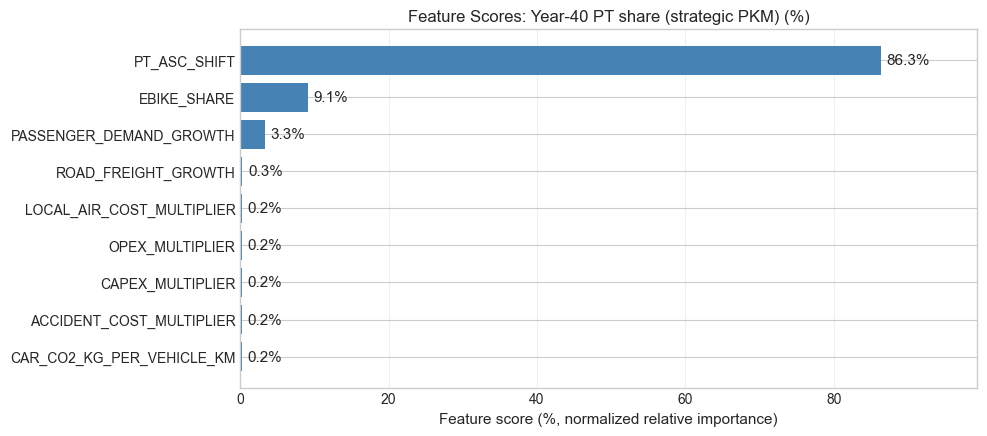

In [32]:
detail_values = (df_baseline[DETAIL_TARGET].to_numpy(dtype=float)
                 if DETAIL_TARGET in feature_scores else np.array([]))
detail_values = detail_values[np.isfinite(detail_values)]
if DETAIL_TARGET in feature_scores and len(detail_values) >= 2 and has_variation(detail_values):
    detail_feature_scores = (100 * feature_scores[DETAIL_TARGET]).sort_values()
    fig, ax = plt.subplots(figsize=(10, max(4.5, .4 * len(detail_feature_scores))))
    bars = ax.barh(detail_feature_scores.index, detail_feature_scores.values, color="steelblue")
    ax.bar_label(bars, labels=[f"{value:.1f}%" for value in detail_feature_scores], padding=4)
    ax.set_xlim(0, max(1, detail_feature_scores.max() * 1.15))
    ax.set_xlabel("Feature score (%, normalized relative importance)")
    ax.set_title(f"Feature Scores: Year-40 {indicator_label(DETAIL_INDICATOR)}")
    ax.grid(axis="x", alpha=.3)
    fig.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_feature_scores_stacked.png").stem, figure=fig)
    exports.save_outputs("03_feature_scores_detail", tables={"": detail_feature_scores.rename("percent").rename_axis("parameter").to_frame().assign(outcome=DETAIL_TARGET)})
    plt.show()
elif DETAIL_TARGET in feature_scores:
    print(f"Year-40 {indicator_label(DETAIL_INDICATOR)} has insufficient finite outcome variation; feature importance is not defined.")
else:
    print("Detail feature plot skipped: choose an indicator with feature scores above.")


## 6.2 Morris screening (advanced task)

**Morris screening** ranks the physical-outcome uncertainties before a focused Sobol decomposition. The run count is calculated dynamically as trajectories times $(D+1)$:

* **$\mu^*$ (mean absolute effect)**: Average magnitude of the elementary effect, conditional on the sampled values of other inputs.
* **$\sigma$ (standard deviation)**: Variation in the elementary effect, which can indicate non-linearity, interactions, or both; Morris does not separate those causes.

Screening runs on all selected `SENSITIVITY_TARGETS` at once. A parameter is retained for Sobol if it has a measurable effect on *any* of them. `MORRIS_PLOT_INDICATORS` controls which of those results are shown, with one panel per indicator. The default shows all selected indicators; edit the list to focus on a subset.

Normal and log-normal inputs use quantiles 0.001–0.999 for Morris and the focused Sobol screening, so endpoint steps have finite, representative values. Bounded distributions use their full range. Ordinary MC/LHS scenario draws retain their configured distributions.


In [33]:
morris_df = pd.DataFrame(columns=["target", "parameter", "mu_star", "sigma"])
REDUCED_PARAMS = []
N_REDUCED = 0
if SCENARIO_NAMES and SENSITIVITY_TARGETS:
    # Morris elementary-effects screening across the full uncertainty set: cheap
    # (N * (D+1) runs) relative to Sobol, used here to cut the dimensionality down
    # to REDUCED_PARAMS before running the much more expensive Sobol analysis.
    N_MORRIS = 40
    ema_model_screening = Model("ForchScreening", function=forch_snapshot_model)
    ema_model_screening.uncertainties = [screening_input(name) for name in SCENARIO_NAMES]
    ema_model_screening.outcomes = [ScalarOutcome(o) for o in OUTCOMES]
    with SequentialEvaluator(ema_model_screening) as evaluator:
        morris_experiments, morris_outcomes = perform_experiments(
            ema_model_screening, N_MORRIS, evaluator=evaluator,
            uncertainty_sampling=Samplers.MORRIS, log_progress=True,
        )
    exports.save_outputs("03_morris_experiments", tables={"": morris_experiments.assign(**morris_outcomes)})
    problem_full = get_SALib_problem(ema_model_screening.uncertainties)
    X_morris = morris_experiments[problem_full["names"]].values
    morris_rows = []
    for target in SENSITIVITY_TARGETS:
        if not np.isfinite(morris_outcomes[target]).all():
            print(f"{target}: undefined sampled outcomes (for example, no PT journeys); structured-design rows cannot be dropped, so this target is skipped.")
            continue
        if not has_variation(morris_outcomes[target]):
            print(f"{target}: no outcome variation in the screening sample.")
            continue
        Si = morris_analyze.analyze(problem_full, X_morris, morris_outcomes[target], print_to_console=False)
        for name, mu_star, sigma in zip(problem_full["names"], Si["mu_star"], Si["sigma"]):
            morris_rows.append({"target": target, "parameter": name, "mu_star": mu_star, "sigma": sigma})
    morris_df = pd.DataFrame(morris_rows, columns=["target", "parameter", "mu_star", "sigma"])

    # Union of parameters with at least 10% of the largest Morris effect for any
    # baseline outcome. All original scenario inputs remain in the plan comparisons.
    selected = []
    for target, group in morris_df.groupby("target"):
        cutoff = max(group["mu_star"].max() * .10, 1e-12)
        selected.extend(group.loc[group["mu_star"] >= cutoff, "parameter"])
    REDUCED_PARAMS = [name for name in U_COLS_FULL if name in set(selected)]
    if not REDUCED_PARAMS:
        print("No inputs have measurable effects on these baseline targets; focused Sobol is skipped.")
    N_REDUCED = len(REDUCED_PARAMS)
    if not morris_df.empty:
        show_table('03_morris_mu_star', morris_df.pivot(index="parameter", columns="target", values="mu_star").style.background_gradient(cmap="Greens"))
    print(f"Reduced union for Sobol ({N_REDUCED} parameters): {REDUCED_PARAMS}")
else:
    print("Morris screening skipped: select available indicators and varying scenario inputs above.")

exports.save_outputs("03_morris_indices", tables={"": morris_df})


cell running: 00:00

target,co2_tonnes_y40,congestion_delay_hours_y40,pt_share_y40
parameter,,,
ACCIDENT_COST_MULTIPLIER,0.000000,0.000000,0.000000
CAPEX_MULTIPLIER,0.000000,0.000000,0.000000
CAR_CO2_KG_PER_VEHICLE_KM,14624.369167,0.000000,0.000000
EBIKE_SHARE,817.890926,89287.423276,0.009786
LOCAL_AIR_COST_MULTIPLIER,0.000000,0.000000,0.000000
OPEX_MULTIPLIER,0.000000,0.000000,0.000000
PASSENGER_DEMAND_GROWTH,5249.712343,344328.407998,0.005891
PT_ASC_SHIFT,628.965129,84785.223237,0.028813
ROAD_FREIGHT_GROWTH,78.439577,26347.888116,0.002079


Reduced union for Sobol (4 parameters): ['PASSENGER_DEMAND_GROWTH', 'PT_ASC_SHIFT', 'EBIKE_SHARE', 'CAR_CO2_KG_PER_VEHICLE_KM']


{'table:': WindowsPath('C:/Users/Enea/Documents/GitHub/IP-HS26-MehrSpur-CaseStudy-IP/results/03_uncertainty_modeling/03_morris_indices.csv')}

cell running: 00:00

c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\matplotlib\_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\matplotlib\_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\pyparsing\util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\matplotlib\_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


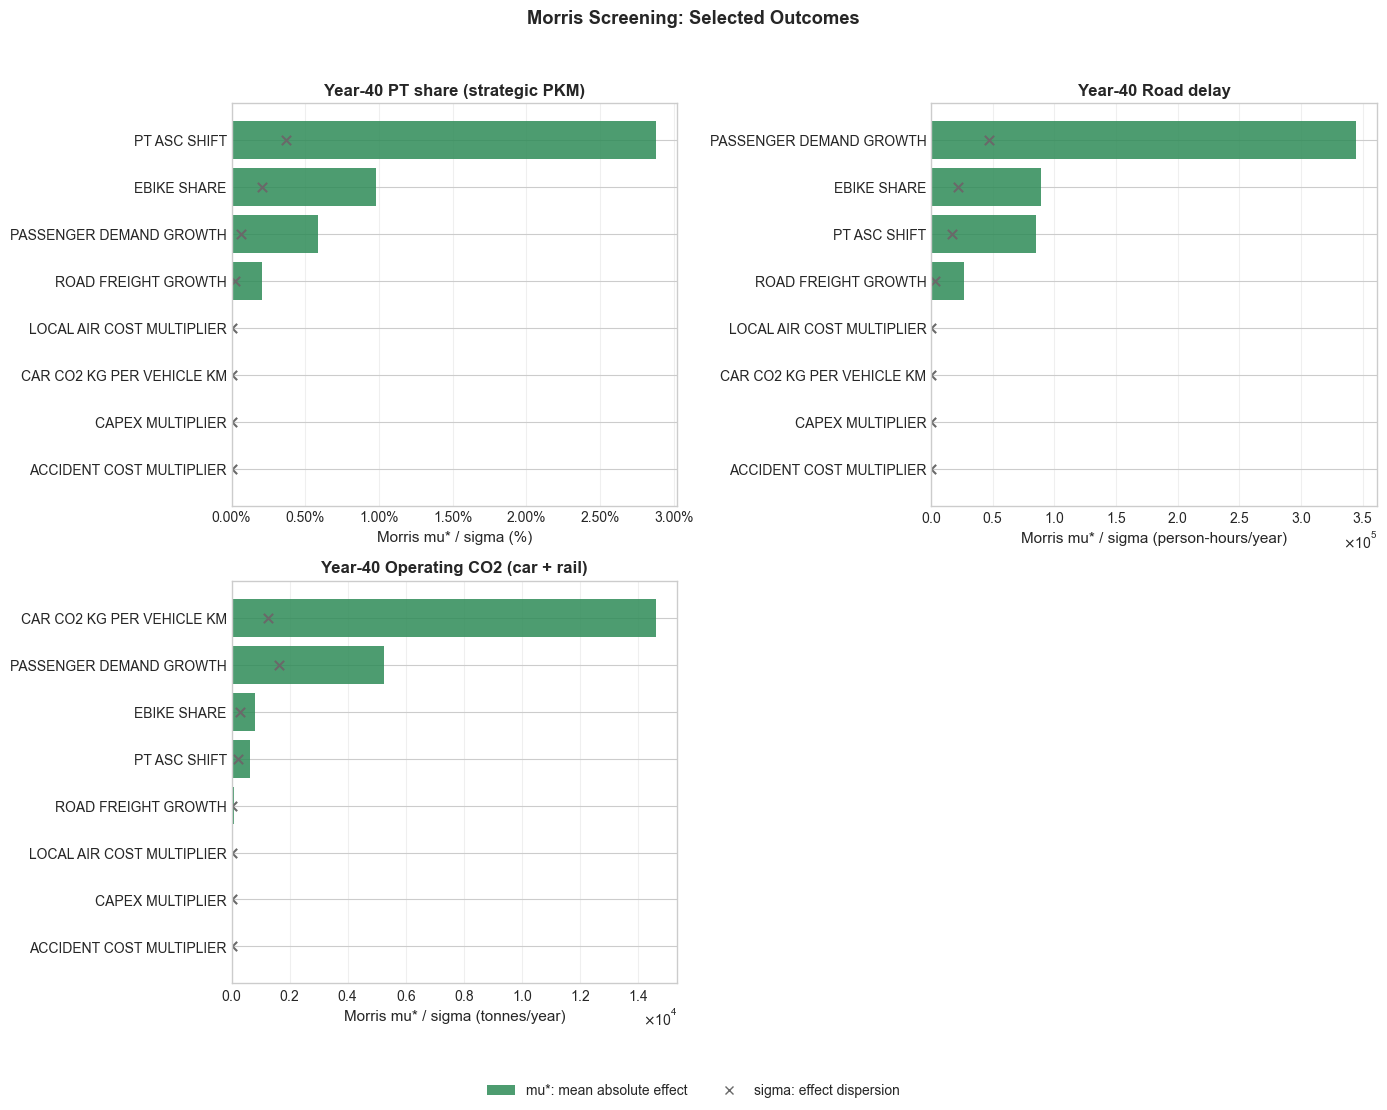

In [34]:
# Edit this list to show any subset of the indicators screened above.
MORRIS_PLOT_INDICATORS = list(SENSITIVITY_INDICATORS)
morris_requested = select_indicators(MORRIS_PLOT_INDICATORS, frame=df_baseline)
morris_available = set(morris_df["target"])
morris_shown = [key for key in morris_requested if f"{key}_y40" in morris_available]
for key in morris_requested:
    if key not in morris_shown:
        print(f"No Morris result for {key}: include it in SENSITIVITY_INDICATORS and run screening; constant or undefined outcomes have no result.")

if morris_shown:
    from textwrap import fill
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch

    # Bars show mu*, crosses show sigma (effect dispersion, not uncertainty).
    n_cols = min(2, len(morris_shown))
    n_rows = int(np.ceil(len(morris_shown) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 5.6 * n_rows), squeeze=False)
    for ax, key in zip(axes.flat, morris_shown):
        target = f"{key}_y40"
        top = morris_df.loc[morris_df["target"] == target].sort_values("mu_star", ascending=False).head(8).sort_values("mu_star")
        labels = [fill(str(name).replace("_", " "), 26) for name in top["parameter"]]
        ax.barh(labels, top["mu_star"], color="seagreen", alpha=0.85)
        ax.scatter(top["sigma"], labels, marker="x", color="dimgray",
                   s=45, label="sigma: effect dispersion")
        ax.set_xlabel(fill(f"Morris mu* / sigma ({INDICATOR_CATALOG[key]['unit']})", 40))
        ax.set_title(fill(f"Year-40 {INDICATOR_CATALOG[key]['label']}", 40), fontweight="bold")
        ax.tick_params(axis="both", labelsize=10)
        if INDICATOR_CATALOG[key].get("format") != "percent":
            ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, 4), useMathText=True)
        format_indicator_axis(ax, key, axis="x")
        ax.grid(axis="x", alpha=0.3)
    for ax in axes.flat[len(morris_shown):]:
        ax.remove()
    fig.suptitle("Morris Screening: Selected Outcomes", fontweight="bold")
    fig.legend(handles=[
        Patch(facecolor="seagreen", alpha=.85, label="mu*: mean absolute effect"),
        Line2D([], [], color="dimgray", marker="x", linestyle="none", label="sigma: effect dispersion"),
    ], loc="lower center", ncol=2, frameon=False, fontsize=10)
    fig.tight_layout(rect=(0, .055, 1, .96))
    exports.save_outputs(Path(FIGURES_DIR / "03_morris_screening.png").stem, figure=fig)
    plt.show()
else:
    print("Morris plot skipped: no selected indicator has screening results.")


**Reading this chart:** Each row is one uncertainty. Bar length shows $\mu^*$, the mean absolute elementary effect; the cross shows $\sigma$, its dispersion, on the same horizontal scale. A large $\sigma$ relative to $\mu^*$ suggests non-linearity or interactions. Morris cannot separate those causes. $\sigma$ is **not** an estimation error bar on $\mu^*$.

Read each indicator's panel separately: effects have that indicator's units, so their magnitudes cannot be compared directly across panels. Rankings can differ. For example, PT share mainly tracks transport inputs, while CO2 can also move with car emission intensity. Rail CO2 follows each configuration's timetable.


## 6.3 Focused Sobol analysis on the Morris-reduced set (advanced task)

We now run one **focused Sobol** design on the union retained by Morris, extracting all three index types described in the Part 6 introduction: $S_1$, $S_T$, and the pairwise $S_2$ interaction matrix. The same evaluations are analysed separately for PT share, congestion, and CO₂, to show how baseline sensitivities differ by outcome.


In [35]:
SOBOL_AVAILABLE = False
sobol_reduced_df = pd.DataFrame(columns=["target", "parameter", "S1", "ST"])
sobol_s2_by_target = {}
if REDUCED_PARAMS and SENSITIVITY_TARGETS:
    # Run the full second-order Sobol design (N=256 base points, so
    # N*(2D+2) evaluations) restricted to REDUCED_PARAMS, and report all three
    # sensitivity index types per outcome: S1 (first-order), ST (total-order),
    # and S2 (pairwise interaction matrix, kept separately since it's DxD).
    ema_model_reduced = Model("ForchReduced", function=forch_snapshot_model)
    ema_model_reduced.uncertainties = [screening_input(name) for name in REDUCED_PARAMS]
    ema_model_reduced.outcomes = [ScalarOutcome(o) for o in OUTCOMES]
    N_SOBOL_REDUCED = 256
    with SequentialEvaluator(ema_model_reduced) as evaluator:
        sob_experiments, sob_outcomes = perform_experiments(
            ema_model_reduced, N_SOBOL_REDUCED, evaluator=evaluator,
            uncertainty_sampling=Samplers.SOBOL, log_progress=True,
        )
    exports.save_outputs("03_sobol_experiments", tables={"": sob_experiments.assign(**sob_outcomes)})
    problem_reduced = get_SALib_problem(ema_model_reduced.uncertainties)
    sobol_rows = []
    for target in SENSITIVITY_TARGETS:
        if not np.isfinite(sob_outcomes[target]).all():
            print(f"{target}: undefined sampled outcomes (for example, no PT journeys); structured-design rows cannot be dropped, so this target is skipped.")
            continue
        if not has_variation(sob_outcomes[target]):
            print(f"{target}: no outcome variation; Sobol indices are not defined.")
            continue
        Si = sobol_analyze.analyze(problem_reduced, sob_outcomes[target], calc_second_order=True, print_to_console=False)
        for name, s1, st in zip(problem_reduced["names"], Si["S1"], Si["ST"]):
            sobol_rows.append({"target": target, "parameter": name, "S1": s1, "ST": st})
        sobol_s2_by_target[target] = pd.DataFrame(
            Si["S2"], index=problem_reduced["names"], columns=problem_reduced["names"]
        )
    sobol_reduced_df = pd.DataFrame(sobol_rows, columns=["target", "parameter", "S1", "ST"])
    SOBOL_AVAILABLE = not sobol_reduced_df.empty
    print(f"Focused Sobol: {len(sob_experiments):,} model evaluations for {N_REDUCED} retained inputs.")
    if SOBOL_AVAILABLE:
        show_table('03_sobol_total_order', sobol_reduced_df.pivot(index="parameter", columns="target", values="ST").style.format(precision=3))
else:
    print("Focused Sobol skipped: no varying baseline targets or no selected inputs.")

exports.save_outputs("03_sobol_indices", tables={"": sobol_reduced_df})
exports.save_outputs("03_sobol_interactions", tables=sobol_s2_by_target)


cell running: 00:00

Focused Sobol: 2,560 model evaluations for 4 retained inputs.


c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\SALib\util\__init__.py:274: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  names = list(pd.unique(groups))


target,co2_tonnes_y40,congestion_delay_hours_y40,pt_share_y40
parameter,,,
CAR_CO2_KG_PER_VEHICLE_KM,0.845,0.000,0.000
EBIKE_SHARE,0.004,0.055,0.096
PASSENGER_DEMAND_GROWTH,0.151,0.905,0.037
PT_ASC_SHIFT,0.002,0.050,0.871


{'table:pt_share_y40': WindowsPath('C:/Users/Enea/Documents/GitHub/IP-HS26-MehrSpur-CaseStudy-IP/results/03_uncertainty_modeling/03_sobol_interactions_pt_share_y40.csv'),
 'table:congestion_delay_hours_y40': WindowsPath('C:/Users/Enea/Documents/GitHub/IP-HS26-MehrSpur-CaseStudy-IP/results/03_uncertainty_modeling/03_sobol_interactions_congestion_delay_hours_y40.csv'),
 'table:co2_tonnes_y40': WindowsPath('C:/Users/Enea/Documents/GitHub/IP-HS26-MehrSpur-CaseStudy-IP/results/03_uncertainty_modeling/03_sobol_interactions_co2_tonnes_y40.csv')}

cell running: 00:00

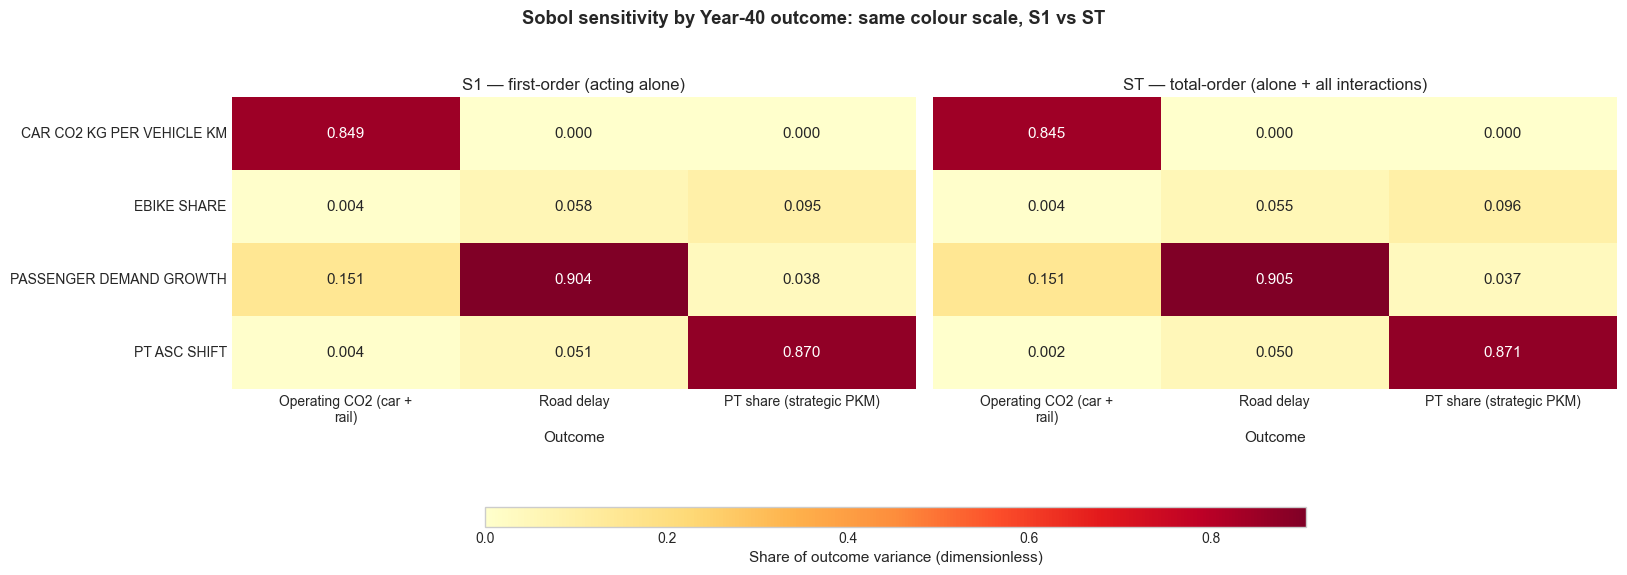

In [36]:
if SOBOL_AVAILABLE:
    from textwrap import fill

    # S1 and ST side by side (not just ST): the gap between them, cell by cell,
    # is exactly how much of that input's influence runs through interactions.
    sobol_s1_plot = sobol_reduced_df.pivot(index="parameter", columns="target", values="S1").fillna(0)
    sobol_st_plot = sobol_reduced_df.pivot(index="parameter", columns="target", values="ST").fillna(0)
    plot_index = [name for name in sobol_st_plot.index]
    sobol_s1_plot.index = plot_index
    sobol_st_plot.index = plot_index

    plot_width = max(15, 5 + 3.8 * len(sobol_st_plot.columns))
    plot_height = max(5.5, .75 * len(sobol_st_plot))
    fig, axes = plt.subplots(1, 2, figsize=(plot_width, plot_height), sharey=True)
    vmax = max(sobol_s1_plot.values.max(), sobol_st_plot.values.max())
    sns.heatmap(sobol_s1_plot, annot=True, fmt=".3f", cmap="YlOrRd", vmin=0, vmax=vmax, ax=axes[0], cbar=False)
    sns.heatmap(sobol_st_plot, annot=True, fmt=".3f", cmap="YlOrRd", vmin=0, vmax=vmax, ax=axes[1], cbar=False)
    axes[0].set(title="S1 — first-order (acting alone)", xlabel="Outcome", ylabel="")
    axes[1].set(title="ST — total-order (alone + all interactions)", xlabel="Outcome", ylabel="")
    outcome_labels = [fill(INDICATOR_CATALOG[target[:-4]]["label"], 24)
                      for target in sobol_st_plot.columns]
    parameter_labels = [fill(str(name).replace("_", " "), 26)
                        for name in sobol_st_plot.index]
    for ax in axes:
        ax.set_xticklabels(outcome_labels, rotation=0, fontsize=10)
    axes[0].set_yticklabels(parameter_labels, rotation=0, fontsize=10)
    plt.suptitle("Sobol sensitivity by Year-40 outcome: same colour scale, S1 vs ST", fontweight="bold")

    fig.tight_layout(rect=[0, 0.16, 1, .95])
    # Shared bar under both panels: cax is [left, bottom, width, height] in figure coordinates.
    cbar_ax = fig.add_axes([0.3, 0.04, 0.50, 0.035])
    fig.colorbar(axes[1].collections[0], cax=cbar_ax, orientation="horizontal",
                 label="Share of outcome variance (dimensionless)")
    exports.save_outputs(Path(FIGURES_DIR / "03_sobol_reduced.png").stem, figure=plt.gcf()); plt.show()
else:
    print('Sensitivity analysis skipped: all scenario quantities follow nominal paths.')

Compare $S_1$ and $S_T$ for each selected outcome. Similar values suggest mostly direct effects; a larger gap $S_T - S_1$ suggests interactions. Interpret small differences cautiously because these are finite-sample estimates. The next heatmap examines individual pairs for `DETAIL_INDICATOR`, chosen in Section 6.1.


cell running: 00:00

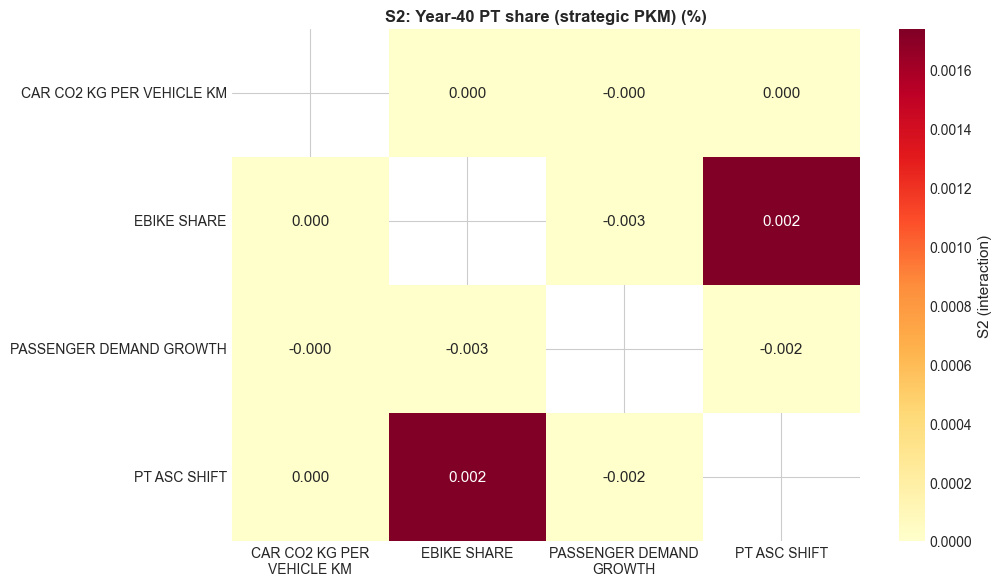

In [37]:
if SOBOL_AVAILABLE and N_REDUCED >= 2 and DETAIL_TARGET in sobol_s2_by_target:
    from textwrap import fill

    # SALib fills the upper triangle; mirror it for a symmetric heatmap.
    s2_matrix = sobol_s2_by_target[DETAIL_TARGET].copy()
    s2_symmetric = s2_matrix.fillna(0) + s2_matrix.fillna(0).T
    np.fill_diagonal(s2_symmetric.values, np.nan)
    s2_symmetric.index = [name for name in s2_symmetric.index]
    s2_symmetric.columns = s2_symmetric.index

    size = len(s2_symmetric)
    fig, ax = plt.subplots(figsize=(max(9, 1.6 * size + 4), max(6, .8 * size + 2.5)))
    s2_limit = max(float(np.nanmax(s2_symmetric.to_numpy())), 1e-9)
    sns.heatmap(s2_symmetric, annot=True, fmt=".3f", cmap="YlOrRd",
                vmin=0, vmax=s2_limit, ax=ax,
                mask=s2_symmetric.isna(), cbar_kws={"label": "S2 (interaction)"})
    ax.set(xlabel="", ylabel="")
    ax.set_title(f"S2: Year-40 {indicator_label(DETAIL_INDICATOR)}", fontweight="bold")
    ax.set_xticklabels([fill(str(name).replace("_", " "), 18)
                        for name in s2_symmetric.columns], rotation=0, fontsize=10)
    ax.set_yticklabels([fill(str(name).replace("_", " "), 26)
                        for name in s2_symmetric.index], rotation=0, fontsize=10)
    plt.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_sobol_s2_interactions.png").stem, figure=plt.gcf())
    plt.show()
else:
    print("Pairwise interaction plot needs a selected outcome with Sobol results and at least two retained uncertainties.")


**What to read from these three charts**

- **$S_1$ / $S_T$ panels:** for each retained parameter and outcome, $S_1$ is the direct (main) effect. The gap $S_T - S_1$ is influence that comes through interactions with other inputs.
- **$S_2$ heatmap:** which pairs may interact strongly for the selected `DETAIL_INDICATOR`.
- **Signs and small values:** finite-sample Sobol estimates can be slightly negative or positive around zero. Do not over-read small values without confidence intervals or a larger convergence study.
- **Morris vs Sobol:** a large Morris $\sigma$ is a reason to look for interactions. It does not guarantee a clear $S_2$ partner on this heatmap.
- **Reduced model:** Sobol here is run on the Morris-retained subset. Indices are conditional on the excluded inputs being fixed at their nominal values.


cell running: 00:00

c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\.venv\Lib\site-packages\SALib\util\__init__.py:274: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  names = list(pd.unique(groups))


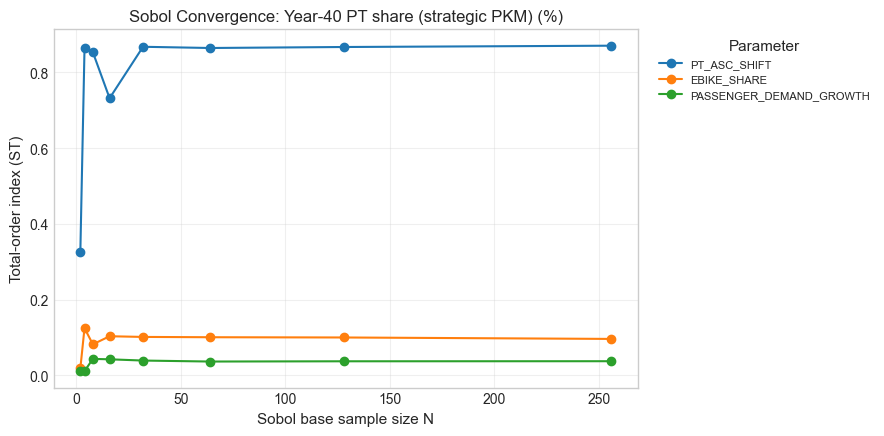

In [38]:
if SOBOL_AVAILABLE and DETAIL_TARGET in sobol_s2_by_target and has_variation(sob_outcomes[DETAIL_TARGET]):
    # Re-analyze the same Sobol samples at increasing base sample sizes N to see
    # how many runs it actually takes for the top parameters' ST estimates to
    # stop moving (converge), rather than trusting the full-N result blindly.
    D = len(problem_reduced["names"])
    block = 2 * D + 2
    N_values = [
        n for n in [2, 4, 8, 16, 32, 64, 128, 256, 512] if n <= N_SOBOL_REDUCED
    ]
    rows = []

    for N in N_values:
      Si = sobol_analyze.analyze(
          problem_reduced,
          sob_outcomes[DETAIL_TARGET][: N * block],
          calc_second_order=True,
          print_to_console=False,
      )
      rows += [
          {"N": N, "parameter": p, "ST": st}
          for p, st in zip(problem_reduced["names"], Si["ST"])
      ]

    sobol_convergence = pd.DataFrame(rows)
    top = sobol_convergence.query("N == @N_values[-1]").nlargest(3, "ST")[
        "parameter"
    ]

    fig, ax = plt.subplots(figsize=(9, 4.5))

    for parameter in top:
      d = sobol_convergence.query("parameter == @parameter")
      label = parameter
      ax.plot(d["N"], d["ST"], marker="o", label=label)

    ax.set_xlabel("Sobol base sample size N")
    ax.set_ylabel("Total-order index (ST)")
    ax.set_title(f"Sobol Convergence: Year-40 {indicator_label(DETAIL_INDICATOR)}")
    ax.legend(
        title="Parameter",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8,
    )
    ax.grid(alpha=0.3)
    plt.tight_layout()

    exports.save_outputs(Path(FIGURES_DIR / "03_sobol_convergence.png").stem, figure=plt.gcf())
    exports.save_outputs("03_sobol_convergence", tables={"": sobol_convergence.assign(outcome=DETAIL_TARGET)})
    plt.show()
else:
    print("Sobol convergence plot skipped: the selected detail indicator has no varying Sobol result.")


## 6.4 Compare rankings: Feature Scoring vs. Sobol (advanced task)

For the selected `DETAIL_INDICATOR`, we compare every parameter retained by Morris screening (`REDUCED_PARAMS`) ranked by **Feature Scoring** against the **Sobol total-order ($S_T$) indices**, rather than truncating to either method's own top-3. Note that a parameter that both methods agree is unimportant is itself a useful check. Agreement strengthens confidence that a driver is important, but disagreement is not automatically an error because the methods answer different questions and react differently to interactions.


cell running: 00:00

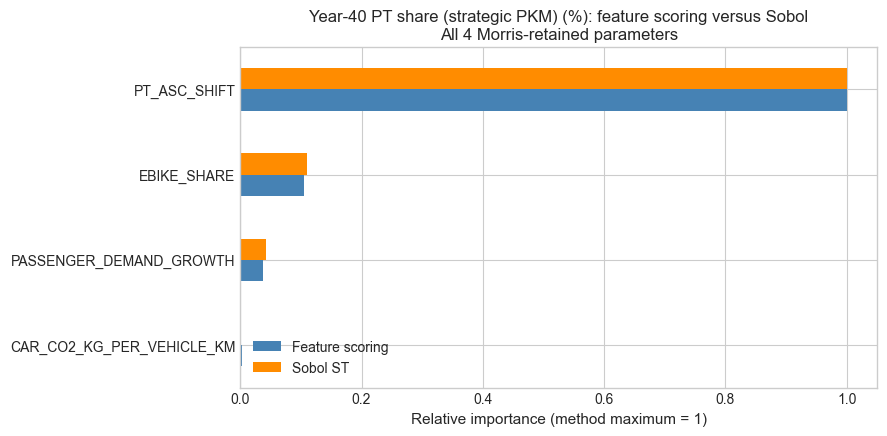

In [39]:
if SOBOL_AVAILABLE and DETAIL_TARGET in feature_scores and DETAIL_TARGET in sobol_s2_by_target:
    # Compare all Morris-retained inputs; normalize each method by its maximum.
    feature_scores_all = feature_scores[DETAIL_TARGET].reindex(REDUCED_PARAMS, fill_value=0)
    sobol_scores_all = (
        sobol_reduced_df.loc[sobol_reduced_df["target"] == DETAIL_TARGET]
        .set_index("parameter")["ST"].reindex(REDUCED_PARAMS, fill_value=0)
    )
    comparison = pd.DataFrame({"Feature scoring": feature_scores_all, "Sobol ST": sobol_scores_all})
    comparison = comparison.div(comparison.max().replace(0, 1))
    comparison = comparison.sort_values("Sobol ST")
    comparison.index = [name for name in comparison.index]
    comparison.plot(kind="barh", figsize=(9, max(4.5, 0.4 * len(comparison))), color=["steelblue", "darkorange"])
    plt.xlabel("Relative importance (method maximum = 1)")
    plt.title(f"Year-40 {indicator_label(DETAIL_INDICATOR)}: feature scoring versus Sobol\nAll {len(REDUCED_PARAMS)} Morris-retained parameters")
    plt.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_extratrees_vs_sobol.png").stem, figure=plt.gcf())
    exports.save_outputs("03_extratrees_vs_sobol", tables={"": comparison.rename_axis("parameter").assign(outcome=DETAIL_TARGET)})
    plt.show()
else:
    print("Ranking comparison skipped: the selected detail indicator needs both feature scores and Sobol results.")


# Part 7 — Compare static plans under the same scenarios

## 7.1 Build the paired plan-comparison dataset (mandatory task)

The same uncertainty draws are evaluated for Stage 0 (`baseline`), Stage 1 (`static1`), and Stages 1 + 2 (`static2`). These are annual operating snapshots. Construction totals are listed separately in Part 3; their scheduling and carbon costs enter the full plan appraisal in Notebooks 04 and 05. NB04 reuses the same fitted transport model while tracing 40-year policies.


In [40]:
# Run every static plan (baseline/static1/static2) through the SAME set of
# sampled scenarios, then
# verify each scenario's draws really were shared identically across plans.
# 1. Register model with plan categorical lever
ema_model_plan = Model("ForchPlan", function=forch_snapshot_model)
ema_model_plan.uncertainties = [
    RealParameter(name, 0.0, 1.0) for name in SCENARIO_NAMES
]
ema_model_plan.levers = [CategoricalParameter("plan", STATIC_PLANS)]
ema_model_plan.outcomes = [ScalarOutcome(o) for o in OUTCOMES]

# 2. Define EMA plans for each static plan
ema_plans = [Policy(key, **{"plan": key}) for key in STATIC_PLANS]

plan_experiments, plan_outcomes = evaluate_design(
    ema_model_plan, N_SCENARIOS, Samplers.LHS, policies=ema_plans,
)

df_plan = plan_experiments.copy()
for col, arr in plan_outcomes.items():
  df_plan[col] = arr

print(
    f"Total runs: {len(df_plan)}  ({plan_experiments.scenario.nunique()} scenarios x"
    f" {len(STATIC_PLANS)} plans)"
)

# 3. Verify every uncertainty draw is identical across plans per scenario
draw_checks = []
for uncertainty in SCENARIO_NAMES:
    check = df_plan.pivot_table(
        index="scenario", columns="plan", values=uncertainty, observed=True
    )
    draw_checks.append(check.nunique(axis=1).eq(1).all())
assert all(draw_checks), "Plans were not run on identical uncertainty draws."
print(
    "Checks passed: all plans share identical uncertainty draws per"
    " scenario."
)

exports.save_outputs("03_experiments_outcomes", tables={"": df_plan})


cell running: 00:00

c:\Users\Enea\Documents\GitHub\IP-HS26-MehrSpur-CaseStudy-IP\code\additional\uncertainty.py:229: UserWarning: ROAD_FREIGHT_GROWTH exceeds its surrogate training range; clipping the trajectory to [-0.05451161530839066, 0.25451161530839067]. Review uncertainty tails or rebuild with wider coverage.
  return clip_transport_paths({key: get_trajectory(key, draws.get(key), shapes.get(key, "linear"), nominal=nominal)
100%|█████████████████████████████████████| 6000/6000 [00:34<00:00, 174.71it/s]


Total runs: 6000  (2000 scenarios x 3 plans)
Checks passed: all plans share identical uncertainty draws per scenario.


{'table:': WindowsPath('C:/Users/Enea/Documents/GitHub/IP-HS26-MehrSpur-CaseStudy-IP/results/03_uncertainty_modeling/03_experiments_outcomes.csv')}

## 7.2 Outcome distributions by plan (mandatory task)

Select `PLAN_INDICATORS` below. The default comparisons are PT strategic share, annual road delay and operating CO2. Every plan sees the same uncertainty draws, so differences reflect the plan rather than a different scenario sample.

Each indicator uses the same vertical scale in the Year-1 and Year-40 panels. With fixed initial conditions, the Year-1 boxes collapse to lines. Absolute outcomes show whether conditions are acceptable; the paired changes below show the effect of the intervention within each future.


cell running: 00:00

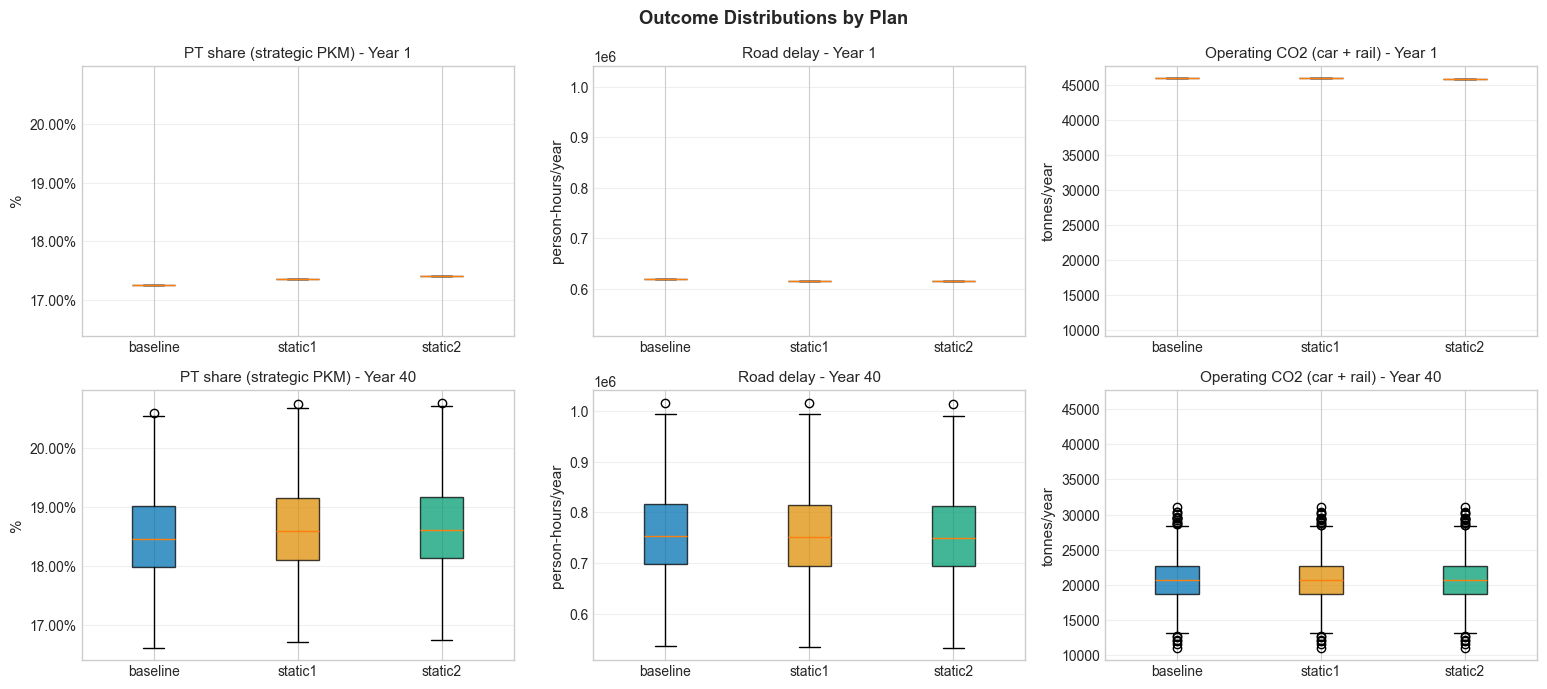

In [41]:
PLAN_INDICATORS = ["pt_share", "congestion_delay_hours", "co2_tonnes"]
plan_indicators = select_indicators(PLAN_INDICATORS, df_plan)
PLAN_COLORS = dict(zip(STATIC_PLANS, sns.color_palette("colorblind", len(STATIC_PLANS))))
if plan_indicators:
    # Each pair of rows shares limits within an indicator; units differ across columns.
    n_cols = min(3, len(plan_indicators))
    n_blocks = int(np.ceil(len(plan_indicators) / n_cols))
    fig, axes = plt.subplots(2 * n_blocks, n_cols, figsize=(5.2 * n_cols, 7 * n_blocks), squeeze=False)
    for position, key in enumerate(plan_indicators):
        block, column = divmod(position, n_cols)
        top, bottom = axes[2 * block, column], axes[2 * block + 1, column]
        bottom.sharey(top)
        for ax, year, title in ((top, "y1", "Year 1"), (bottom, "y40", "Year 40")):
            values = [df_plan.loc[df_plan["plan"] == plan, f"{key}_{year}"].dropna() for plan in STATIC_PLANS]
            bp = ax.boxplot(values, tick_labels=STATIC_PLANS, patch_artist=True)
            for box, plan in zip(bp["boxes"], STATIC_PLANS):
                box.set(facecolor=PLAN_COLORS[plan], alpha=.75)
            ax.set_title(f"{INDICATOR_CATALOG[key]['label']} - {title}", fontsize=11)
            ax.set_ylabel(INDICATOR_CATALOG[key]["unit"])
            format_indicator_axis(ax, key)
            ax.grid(axis="y", alpha=.3)
    for position in range(len(plan_indicators), n_blocks * n_cols):
        block, column = divmod(position, n_cols)
        axes[2 * block, column].remove()
        axes[2 * block + 1, column].remove()
    fig.suptitle("Outcome Distributions by Plan", fontweight="bold")
    fig.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_plan_distributions.png").stem, figure=fig)
    plt.show()
else:
    print("No available plan indicators selected.")


### 7.2.1 Exact percentile summary by plan (tutorial/supporting task)

The table reports medians and 10th/90th percentiles for the same distributions. Use it when exact values and uncertainty ranges are more useful than visually estimating boxplot edges.

In [42]:
SUMMARY_INDICATORS = PLAN_INDICATORS.copy()
summary_indicators = select_indicators(SUMMARY_INDICATORS, df_plan)
summary_columns = [f"{key}_y40" for key in summary_indicators]
if summary_columns:
    plan_percentiles = df_plan.groupby("plan", observed=True)[summary_columns].quantile([.1, .5, .9])
    show_table('03_plan_percentiles', plan_percentiles.rename_axis(index=["plan", "quantile"]))


cell running: 00:00

pt_share_y40  congestion_delay_hours_y40  co2_tonnes_y40
plan     quantile                                                          
baseline 0.1           0.176145               653655.879311    16990.798750
         0.5           0.184617               753098.240816    20682.519133
         0.9           0.195213               878706.981255    24882.514604
static1  0.1           0.177355               650899.580434    16965.045631
         0.5           0.185909               750910.032336    20656.121492
         0.9           0.196583               877319.843858    24845.934408
static2  0.1           0.177625               649772.881096    16962.727610
         0.5           0.186148               748745.919774    20650.885145
         0.9           0.196802               875158.932670    24842.362897

### 7.2.2 Paired changes relative to the baseline

For each future, subtract the baseline outcome from the plan outcome **in that same future**. The zero line means no change. Negative values are reductions; share differences are in percentage points. The summary reports the fraction improving according to the catalogue's preferred direction; contextual indicators have no improvement score.

The first figure uses the system indicators selected in 7.2. The second focuses on PT journey time and optional section effects. Replace either selection for a cycling, walking or other project. These comparisons reuse `df_plan`; they run no transport simulations.


cell running: 00:00

Unavailable indicators: ['section_load_ratio', 'section_crowding_penalty_min']. Check section settings or whether the mode has passengers. Omitted from this display.


C:\Users\Enea\AppData\Local\Temp\ipykernel_2964\1906036833.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  if frame.groupby("scenario")[uncertainty].nunique(dropna=False).gt(1).any():


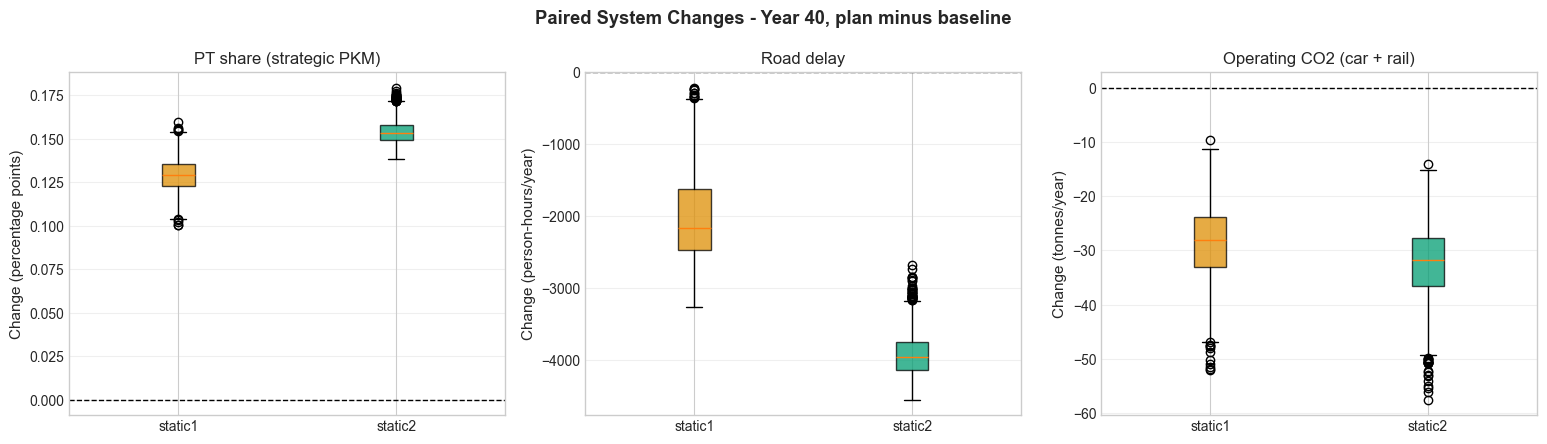

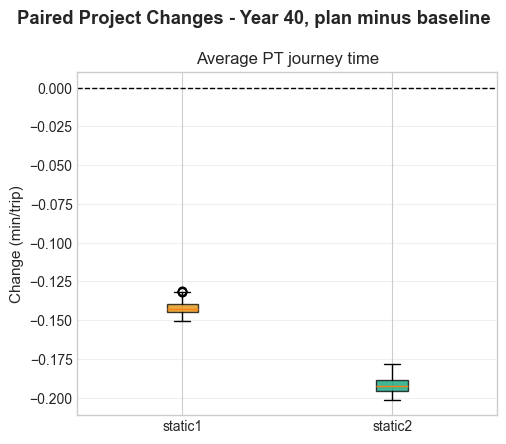

,indicator,plan,unit,valid_pairs,p10,median,p90,fraction_improving
0,pt_share,static1,percentage points,2000,0.116973,0.129250,0.141499,1.0
1,pt_share,static2,percentage points,2000,0.145929,0.153119,0.163710,1.0
2,congestion_delay_hours,static1,person-hours/year,2000,-2704.903653,-2160.983813,-1134.549445,1.0
3,congestion_delay_hours,static2,person-hours/year,2000,-4261.013011,-3958.830067,-3535.745702,1.0
4,co2_tonnes,static1,tonnes/year,2000,-37.676920,-28.103273,-20.866993,1.0
5,co2_tonnes,static2,tonnes/year,2000,-41.180215,-31.819199,-24.689958,1.0
6,pt_journey_time_min,static1,min/trip,2000,-0.146478,-0.142492,-0.136875,1.0
7,pt_journey_time_min,static2,min/trip,2000,-0.197441,-0.192525,-0.184937,1.0


{'table:': WindowsPath('C:/Users/Enea/Documents/GitHub/IP-HS26-MehrSpur-CaseStudy-IP/results/03_uncertainty_modeling/03_paired_changes.csv')}

In [43]:
PAIRED_INDICATORS = PLAN_INDICATORS.copy()
PROJECT_INDICATORS = ["pt_journey_time_min", "section_load_ratio", "section_crowding_penalty_min"]
# For a cycling project, for example: ["bike_share_trips", "walk_share_trips", "car_vehicle_km"]
REFERENCE_PLAN = "baseline"

def paired_changes(frame, names, reference=REFERENCE_PLAN):
    keys = select_indicators(names, frame)
    if frame.duplicated(["scenario", "plan"]).any():
        raise ValueError("Paired changes require one row per scenario and plan.")
    plans = frame["plan"].drop_duplicates().tolist()
    if reference not in plans:
        raise ValueError(f"Reference plan {reference!r} is absent.")
    scenario_sets = [set(frame.loc[frame["plan"] == plan, "scenario"]) for plan in plans]
    if any(ids != scenario_sets[0] for ids in scenario_sets):
        raise ValueError("Plan comparisons require the same scenario IDs for every plan.")
    for uncertainty in U_COLS_FULL:
        if frame.groupby("scenario")[uncertainty].nunique(dropna=False).gt(1).any():
            raise ValueError(f"Plans use different {uncertainty} draws in the same scenario.")
    rows = []
    for key in keys:
        wide = frame.pivot(index="scenario", columns="plan", values=f"{key}_y40")
        spec = INDICATOR_CATALOG[key]
        multiplier = 100.0 if spec.get("format") == "percent" else 1.0
        unit = "percentage points" if multiplier == 100 else spec["unit"]
        for plan in plans:
            if plan != reference:
                changes = (wide[plan] - wide[reference]) * multiplier
                rows.extend({"scenario": scenario, "plan": plan, "indicator": key,
                             "change": float(value), "unit": unit}
                            for scenario, value in changes.items())
    return pd.DataFrame(rows, columns=["scenario", "plan", "indicator", "change", "unit"])

def plot_paired_changes(changes, names, title, filename):
    keys = [key for key in dict.fromkeys(names) if key in changes["indicator"].unique()]
    alternatives = [plan for plan in STATIC_PLANS if plan != REFERENCE_PLAN]
    if not keys or not alternatives:
        print("No available paired indicators selected.")
        return
    n_cols = min(3, len(keys))
    fig, axes = plt.subplots(int(np.ceil(len(keys) / n_cols)), n_cols,
                             figsize=(5.2 * n_cols, 4.5 * int(np.ceil(len(keys) / n_cols))), squeeze=False)
    for ax, key in zip(axes.flat, keys):
        sub = changes.loc[changes["indicator"] == key]
        data = [sub.loc[sub["plan"] == plan, "change"].dropna() for plan in alternatives]
        bp = ax.boxplot(data, tick_labels=alternatives, patch_artist=True)
        for box, plan in zip(bp["boxes"], alternatives):
            box.set(facecolor=PLAN_COLORS[plan], alpha=.75)
        ax.axhline(0, color="black", linewidth=1, linestyle="--")
        ax.set(title=INDICATOR_CATALOG[key]["label"], ylabel="Change (" + sub["unit"].iloc[0] + ")")
        ax.grid(axis="y", alpha=.3)
    for ax in axes.flat[len(keys):]:
        ax.remove()
    fig.suptitle(title + f" - Year 40, plan minus {REFERENCE_PLAN}", fontweight="bold")
    fig.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / filename).stem, figure=fig)
    plt.show()

paired_df = paired_changes(df_plan, list(dict.fromkeys(PAIRED_INDICATORS + PROJECT_INDICATORS)))
plot_paired_changes(paired_df, PAIRED_INDICATORS, "Paired System Changes", "03_paired_system_changes.png")
plot_paired_changes(paired_df, PROJECT_INDICATORS, "Paired Project Changes", "03_paired_project_changes.png")
paired_rows = []
for (key, plan), group in paired_df.groupby(["indicator", "plan"], sort=False):
    changes = group["change"].dropna()
    direction = INDICATOR_CATALOG[key]["direction"]
    improving = ((changes > 1e-12) if direction == "higher" else (changes < -1e-12))
    paired_rows.append({"indicator": key, "plan": plan, "unit": group["unit"].iloc[0],
        "valid_pairs": len(changes), "p10": changes.quantile(.1), "median": changes.median(),
        "p90": changes.quantile(.9), "fraction_improving": improving.mean() if direction != "context" and len(changes) else np.nan})
paired_summary = pd.DataFrame(paired_rows)
show_table('03_paired_change_summary', paired_summary)
exports.save_outputs("03_paired_changes", tables={"": paired_df})


## 7.3 Parallel coordinates - plan profiles across futures (tutorial/supporting task)

Choose `PARALLEL_INDICATORS` below; they default to the system comparisons in 7.2. Outcomes are min-max normalized across all plans so indicators with different units share the same vertical scale. Each objective uses the pooled min and max of Year 1 and Year 40, so a shift between panels is a real change, not a rescaling.

The top panel shows Year 1 and the bottom panel shows Year 40. Lines connect plan medians; thin bars show the 10th-90th percentile range and thick bars show the 25th-75th range. Fixed Year-1 outcomes appear as markers without a spread. Greater separation indicates larger plan differences relative to that indicator's range; overlapping intervals indicate that the plans' outcome ranges overlap.

Normalization preserves the original direction: a larger value is not necessarily better. Use the catalogue to interpret each indicator.


cell running: 00:00

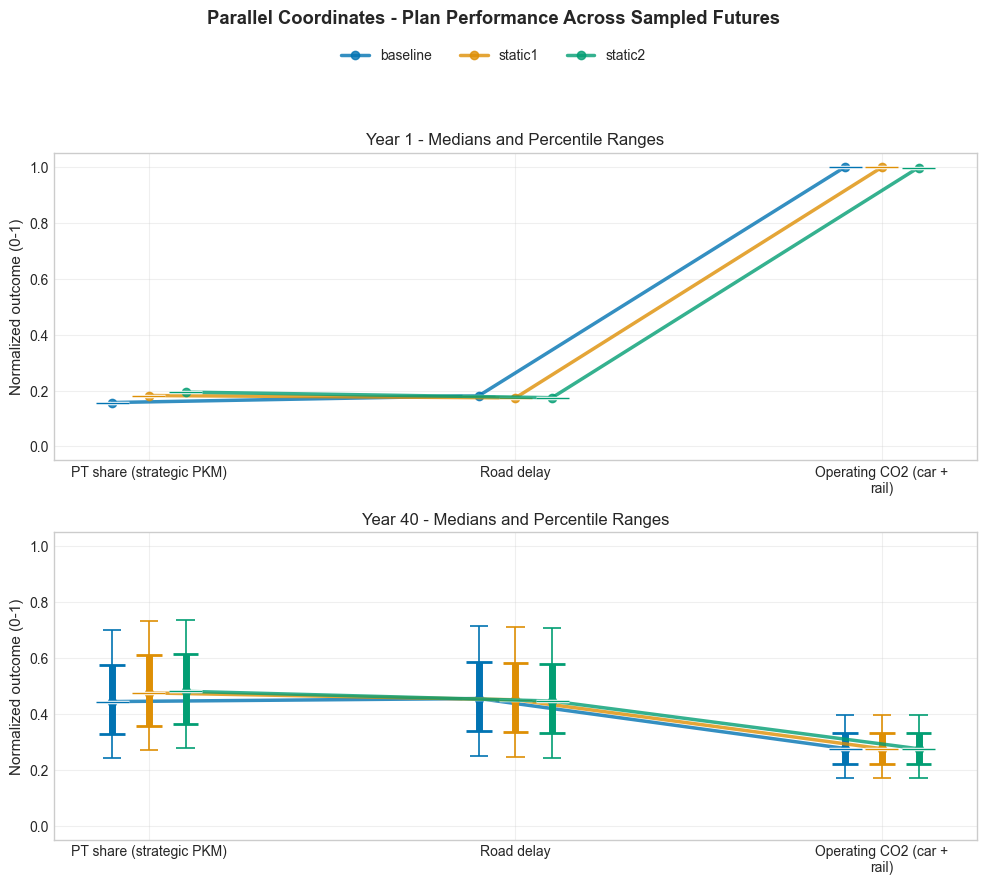

In [44]:
# Parallel coordinates: Year-1 and Year-40 medians with percentile ranges.
# Each objective is min-max normalized using the pooled Year-1 and Year-40 range.
PARALLEL_INDICATORS = PLAN_INDICATORS.copy()
PARCOORD_OBJS = select_indicators(PARALLEL_INDICATORS, df_plan)
from textwrap import fill
PARCOORD_LABELS = [fill(INDICATOR_CATALOG[key]["label"], 25) for key in PARCOORD_OBJS]

pc_df = df_plan[["scenario", "plan"]].copy()
normalization_rows = []
for obj in PARCOORD_OBJS:
    both = df_plan[[f"{obj}_y1", f"{obj}_y40"]]
    lo, hi = both.min().min(), both.max().max()
    normalization_rows.append({"indicator": obj, "minimum": lo, "maximum": hi})
    span = hi - lo
    for year in ("y1", "y40"):
        pc_df[f"{obj}_{year}"] = (df_plan[f"{obj}_{year}"] - lo) / span if span > 0 else .5

x = np.arange(len(PARCOORD_OBJS))
offsets = dict(zip(STATIC_PLANS, np.linspace(-0.10, 0.10, len(STATIC_PLANS))))


def _plot_percentiles(ax, cols):
    for plan in STATIC_PLANS:
        data = pc_df.loc[pc_df["plan"] == plan, cols]
        color, xs = PLAN_COLORS[plan], x + offsets[plan]
        p10, p25, p50, p75, p90 = data.quantile([0.10, 0.25, 0.50, 0.75, 0.90]).values
        ax.plot(xs, p50, color=color, linewidth=2.5, alpha=0.8, marker="o", label=plan)
        ax.vlines(xs, p10, p90, color=color, linewidth=1.2)
        ax.vlines(xs, p25, p75, color=color, linewidth=5)
        for xi, q10, q25, q50, q75, q90 in zip(xs, p10, p25, p50, p75, p90):
            ax.hlines([q10, q90], xi - 0.025, xi + 0.025, color=color, linewidth=1.2)
            ax.hlines([q25, q75], xi - 0.035, xi + 0.035, color=color, linewidth=2)
            ax.hlines(q50, xi - 0.045, xi + 0.045, color="white", linewidth=2.5)
            ax.hlines(q50, xi - 0.045, xi + 0.045, color=color, linewidth=1)


if PARCOORD_OBJS:
    fig, axes = plt.subplots(2, 1, figsize=(max(10, 2.5 * len(PARCOORD_OBJS)), 9), sharey=True)
    for row, year, year_label in ((0, "y1", "Year 1"), (1, "y40", "Year 40")):
        cols = [f"{obj}_{year}" for obj in PARCOORD_OBJS]
        _plot_percentiles(axes[row], cols)
        axes[row].set_title(f"{year_label} - Medians and Percentile Ranges")
        axes[row].set_ylabel("Normalized outcome (0-1)")
        axes[row].set_xticks(x, PARCOORD_LABELS)
        axes[row].set_ylim(-.05, 1.05)
        axes[row].grid(alpha=0.3)
    
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5, .95),
               ncol=len(STATIC_PLANS), frameon=False)
    fig.suptitle("Parallel Coordinates - Plan Performance Across Sampled Futures", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, .90))
    exports.save_outputs(Path(FIGURES_DIR / "03_plan_parallel_coordinates.png").stem, figure=fig)
    exports.save_outputs("03_plan_parallel_coordinates", tables={
        "normalized": pc_df, "normalization": pd.DataFrame(normalization_rows),
    })
    plt.show()
else:
    print("No available parallel-coordinate indicators selected.")


## 7.4 Feature scores by plan (mandatory task)

Select `PLAN_FEATURE_INDICATOR` below. Feature scoring compares which uncertainties explain the Year-40 outcome across plans. It reuses the same paired experiments and allows every input at each tree split. Constant outcomes have no defined feature importance.


cell running: 00:00

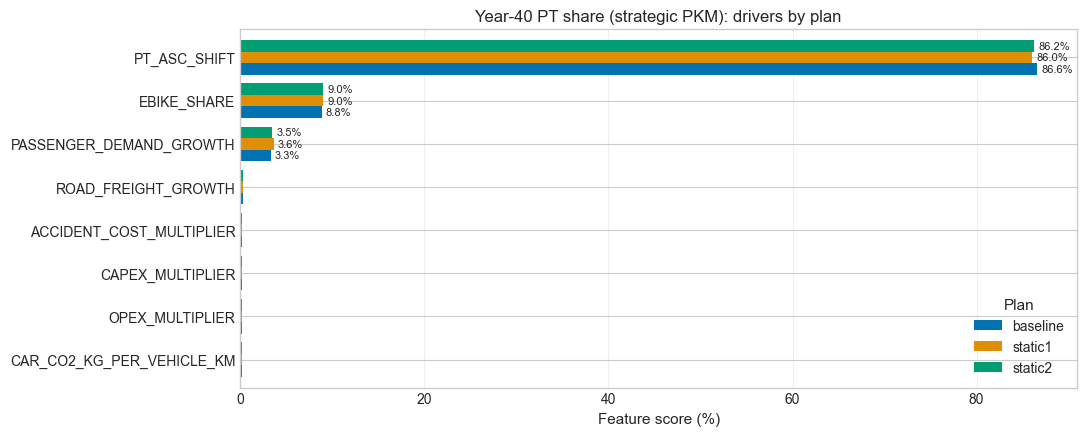

In [45]:
PLAN_FEATURE_INDICATOR = "pt_share"  # For example, bike_share_trips or section_load_ratio.
selected = select_indicators([PLAN_FEATURE_INDICATOR], df_plan)
if SCENARIO_NAMES and selected:
    target = f"{PLAN_FEATURE_INDICATOR}_y40"
    U_COLS_PLAN = [u.name for u in ema_model_plan.uncertainties]
    scores = {}
    for plan in STATIC_PLANS:
        sub = df_plan.loc[df_plan["plan"] == plan]
        scores[plan] = feature_scores_for(sub[U_COLS_PLAN], sub[target].values, f"{plan}: {target}")
    score_df = pd.DataFrame(scores) * 100
    exports.save_outputs("03_feature_scores_by_plan", tables={"": score_df.rename_axis("parameter").assign(outcome=target, unit="percent")})
    if score_df.to_numpy().any():
        plot_df = score_df.loc[score_df.max(axis=1).nlargest(8).sort_values().index]
        fig, ax = plt.subplots(figsize=(11, max(4.5, .5 * len(plot_df))))
        plot_df.plot(kind="barh", ax=ax, width=.8, color=[PLAN_COLORS[key] for key in STATIC_PLANS])
        for container in ax.containers:
            ax.bar_label(container, labels=[f"{value:.1f}%" if value >= .5 else "" for value in container.datavalues], padding=3, fontsize=8)
        ax.set(xlabel="Feature score (%)", ylabel="", title="Year-40 " + INDICATOR_CATALOG[PLAN_FEATURE_INDICATOR]["label"] + ": drivers by plan")
        ax.legend(title="Plan", loc="lower right")
        ax.grid(axis="x", alpha=.3)
        fig.tight_layout()
        exports.save_outputs(Path(FIGURES_DIR / "03_feature_scores_by_plan.png").stem, figure=fig)
        plt.show()
    else:
        print("No varying outcome available for the selected plan feature indicator.")
else:
    print("Plan feature scoring skipped: select uncertainties and an available indicator.")


# Part 8 - Which scenarios create vulnerabilities or opportunities? - Scenario discovery

Sensitivity identifies influential inputs; scenario discovery searches for combinations of their values associated with failure. The **Patient Rule Induction Method (PRIM)** describes these regions with rectangular bounds.

## 8.1 Defining vulnerability/opportunity (mandatory task)

Edit `VULNERABILITY_RULES` below to define **failure** using one or more Year-40 indicators. Each rule specifies an indicator key, a comparison operator and a threshold in that indicator's native units. For example, a share of 35% is entered as `0.35`. `VULNERABILITY_MATCH = "any"` flags a future if **at least one** rule holds; `"all"` requires **every** rule to hold. A rule defines a failure condition, so use `<` for a minimum target or `>` for a maximum acceptable value.

The default preserves the public-transport benchmark: Year-40 `pt_share < p.PT_SHARE_TARGET`. Choose and justify benchmarks for your own project. The supplied threshold is a teaching value only. The rule table below prints the actual settings.

Modal-share indicators (`car_share`, `pt_share`, `bike_share`, `walk_share`) are **strategic passenger-kilometre shares**: they weight retained OD pairs touching the corridor and meeting `MIN_STRATEGIC_PKM_DISTANCE` by distance. Section passenger counts and unweighted trip shares are separate indicators. Consult the indicator catalogue for each selected indicator's units and scope.


In [ ]:
# Edit these failure rules; indicator keys and units come from the catalogue.
VULNERABILITY_RULES = [
    {"indicator": "pt_share", "operator": "<", "threshold": float(p.PT_SHARE_TARGET)},
]
VULNERABILITY_MATCH = "any"  # "any": at least one rule; "all": every rule.

import operator as _comparison

_failure_operators = {
    "<": _comparison.lt, "<=": _comparison.le,
    ">": _comparison.gt, ">=": _comparison.ge,
    "==": _comparison.eq, "!=": _comparison.ne,
}
if VULNERABILITY_MATCH not in ("any", "all"):
    raise ValueError('VULNERABILITY_MATCH must be "any" or "all".')
if not isinstance(VULNERABILITY_RULES, list) or not VULNERABILITY_RULES:
    raise ValueError("VULNERABILITY_RULES must contain at least one failure rule.")

validated_vulnerability_rules = []
_failure_flags = []
_rule_descriptions = []
for number, rule in enumerate(VULNERABILITY_RULES, start=1):
    if not isinstance(rule, dict) or not {"indicator", "operator", "threshold"} <= rule.keys():
        raise ValueError(f"Failure rule {number} needs indicator, operator and threshold.")
    key, comparison = rule["indicator"], rule["operator"]
    if not isinstance(key, str):
        raise ValueError(f"Failure rule {number}: indicator must be a catalogue key string.")
    select_indicators([key], frame=df_plan, year="y40", required=True)
    if not isinstance(comparison, str) or comparison not in _failure_operators:
        raise ValueError(f"Failure rule {number}: operator must be one of {list(_failure_operators)}.")
    try:
        threshold = float(rule["threshold"])
    except (TypeError, ValueError) as exc:
        raise ValueError(f"Failure rule {number}: threshold must be a finite number.") from exc
    if isinstance(rule["threshold"], (bool, np.bool_)) or not np.isfinite(threshold):
        raise ValueError(f"Failure rule {number}: threshold must be a finite number.")
    column = f"{key}_y40"
    values = pd.to_numeric(df_plan[column], errors="coerce").to_numpy(dtype=float, na_value=np.nan)
    invalid = ~np.isfinite(values)
    if invalid.any():
        raise ValueError(f"Failure rule {number}: {column} has {int(invalid.sum())} missing or non-finite values. "
                         "Check the indicator requirements and rerun the plan comparison before defining vulnerability.")
    _failure_flags.append(_failure_operators[comparison](values, threshold))
    validated_vulnerability_rules.append({"indicator": key, "operator": comparison, "threshold": threshold})
    _rule_descriptions.append(f"Year 40: {indicator_label(key)} {comparison} {indicator_format(threshold, key)}")

_failure_matrix = np.column_stack(_failure_flags)
df_plan["vulnerable"] = (_failure_matrix.any(axis=1) if VULNERABILITY_MATCH == "any"
                         else _failure_matrix.all(axis=1))
VULNERABILITY_DEFINITION = (" OR " if VULNERABILITY_MATCH == "any" else " AND ").join(
    f"({description})" for description in _rule_descriptions
)
print("Failure rule combination:", VULNERABILITY_MATCH)
print(VULNERABILITY_DEFINITION)
show_table('03_vulnerability_rules', pd.DataFrame(validated_vulnerability_rules).assign(
    label=[indicator_label(rule["indicator"]) for rule in validated_vulnerability_rules],
    formatted_threshold=[indicator_format(rule["threshold"], rule["indicator"])
                         for rule in validated_vulnerability_rules],
))

overall_rate = df_plan["vulnerable"].mean()
print(f"Share of vulnerable sampled plan-scenario futures: {overall_rate:.0%} "
      "(conditional on the selected uncertainty ranges and sampling assumptions)")
fail_by_plan = (df_plan.groupby("plan", observed=True)["vulnerable"]
                .mean().reindex(STATIC_PLANS))
print("\nFraction of sampled futures meeting the configured failure condition, by plan:")
print((fail_by_plan * 100).round(1).astype(str) + "%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
pie_vals = [overall_rate, 1 - overall_rate]
pie_lbls = ["Vulnerable", "Not vulnerable"]
pie_cols = ["crimson", "lightgray"]
active_indices = [i for i, value in enumerate(pie_vals) if value > 1e-6]
axes[0].pie([pie_vals[i] for i in active_indices],
            labels=[pie_lbls[i] for i in active_indices], autopct="%1.0f%%",
            colors=[pie_cols[i] for i in active_indices], startangle=90,
            wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[0].set_title(f"All plans pooled (n={len(df_plan)})", fontsize=11)

bars = axes[1].bar(STATIC_PLANS, fail_by_plan.values * 100,
                   color=[PLAN_COLORS[key] for key in STATIC_PLANS], width=0.55)
for bar, value in zip(bars, fail_by_plan.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2.0,
                 f"{value:.0%}", ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("Vulnerable sampled futures (%)")
axes[1].set_title("Fraction of sampled futures meeting the failure condition", fontsize=11)
axes[1].grid(axis="y", alpha=0.3)
plt.suptitle("How often does each plan meet the configured failure condition?",
             fontsize=12, fontweight="bold", y=1.03)
plt.tight_layout()
exports.save_outputs(Path(FIGURES_DIR / "03_vulnerability_by_plan.png").stem, figure=plt.gcf())
exports.save_outputs("03_vulnerability_by_plan", tables={"": fail_by_plan.rename("failure_fraction")})
exports.save_outputs("03_vulnerability_cases", tables={"": df_plan})
plt.show()

# Defaults also support skipping the optional PRIM fit.
base_df = df_plan[df_plan["plan"] == "baseline"]


## 8.2 Where in the uncertainty space does baseline failure occur? (mandatory task)

The Patient Rule Induction Method **PRIM**, implemented in the EMA Workbench, looks for a box: upper and lower bounds on the uncertainty inputs that cover the defined vulnerability/opportunity region. The futures inside those bounds are the ones PRIM associates with failure.

Two numbers describe the box:

- **Density** is the fraction of sampled futures inside the box that fail.
- **Coverage** is the fraction of all sampled failures that fall inside the box.

A useful box is dense and still covers a substantial share of failures. A very small box can be almost pure failure and still miss most failures. A very large box can include almost every failure and also many futures that meet the target.

By default, the search uses every selected scenario uncertainty, including post-modelling inputs that can affect indicators such as emissions. Edit `PRIM_INPUTS` below to choose a justified subset, and `PRIM_PLOT_INPUTS` to choose the two displayed inputs. All must be selected scenario inputs. The search is run on baseline (Stage 0), so the box describes futures in which building nothing meets the configured failure condition.

A qualifying box must have at least 75% failure density and restrict at least one input. The plot draws the box on two inputs. Bounds on any other inputs that PRIM narrowed are listed in the table.


In [ ]:
# PRIM scenario discovery on the baseline plan: find the smallest box in
# uncertainty space (a range on each selected input) that concentrates most
# of the vulnerable scenarios under the configured rules, skipped automatically
# if either class has too few cases to fit a reliable box.
# Edit these input lists; they do not change the sampled scenarios.
PRIM_INPUTS = SCENARIO_NAMES.copy()
PRIM_PLOT_INPUTS = PRIM_INPUTS[:2]
if not isinstance(PRIM_INPUTS, list) or any(not isinstance(name, str) for name in PRIM_INPUTS):
    raise ValueError("PRIM_INPUTS must be a list of selected scenario uncertainty names.")
if len(set(PRIM_INPUTS)) != len(PRIM_INPUTS) or set(PRIM_INPUTS) - set(SCENARIO_NAMES):
    raise ValueError("PRIM_INPUTS must contain unique names from SCENARIO_NAMES.")
if not isinstance(PRIM_PLOT_INPUTS, list) or len(PRIM_PLOT_INPUTS) > 2:
    raise ValueError("PRIM_PLOT_INPUTS must contain at most two input names.")
if any(not isinstance(name, str) for name in PRIM_PLOT_INPUTS):
    raise ValueError("PRIM_PLOT_INPUTS must contain input-name strings.")
if any(name not in PRIM_INPUTS for name in PRIM_PLOT_INPUTS) or len(set(PRIM_PLOT_INPUTS)) != len(PRIM_PLOT_INPUTS):
    raise ValueError("PRIM_PLOT_INPUTS must contain distinct names from PRIM_INPUTS.")
HAS_TWO_PRIM = len(PRIM_PLOT_INPUTS) == 2
X_PRIM, Y_PRIM = PRIM_PLOT_INPUTS if HAS_TWO_PRIM else (None, None)

MIN_CASES_PER_CLASS_FOR_PRIM = 15
PRIM_DENSITY_THRESHOLD = 0.75

base_df = df_plan[df_plan["plan"] == "baseline"]
x_prim = base_df[PRIM_INPUTS]
y_prim = base_df["vulnerable"].values
n_failures = int(y_prim.sum())
n_successes = int((~y_prim).sum())

print(
    f"Baseline: {n_failures} failures and {n_successes} successes "
    f"out of {len(y_prim)} scenarios."
)

PRIM_AVAILABLE = bool(PRIM_INPUTS) and min(n_failures, n_successes) >= MIN_CASES_PER_CLASS_FOR_PRIM
BASELINE_PRIM_ACCEPTED = False
prim_alg = None
box_baseline = None
bounds_baseline = pd.DataFrame()

if PRIM_AVAILABLE:
    prim_alg = prim.Prim(
        x_prim, y_prim, threshold=PRIM_DENSITY_THRESHOLD, peel_alpha=0.1,
    )
    box_baseline = prim_alg.find_box()
    BASELINE_PRIM_ACCEPTED = accepted_prim_box(box_baseline)
    PRIM_AVAILABLE = BASELINE_PRIM_ACCEPTED
    exports.save_outputs("03_prim_baseline", tables={
        "peeling": box_baseline.peeling_trajectory,
        "bounds": box_baseline.box_lim.T.rename_axis("parameter"),
        "status": pd.DataFrame([{"accepted": BASELINE_PRIM_ACCEPTED,
            "density": box_baseline.density, "coverage": box_baseline.coverage,
            "density_threshold": PRIM_DENSITY_THRESHOLD}]),
    })
    box_baseline.show_tradeoff()
    plt.title(
        "PRIM Peeling Trajectory — Baseline Plan", fontsize=11, fontweight="bold"
    )
    plt.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_prim_tradeoff.png").stem, figure=plt.gcf())
    plt.show()
    if BASELINE_PRIM_ACCEPTED:
        box_baseline.inspect(style="table")
        bounds_baseline = prim_alg.boxes_to_dataframe()
        print("\nQualifying baseline box bounds:")
        print(bounds_baseline)
        endpoint_bounds = pd.DataFrame({
            name: [uc.get_trajectory(name, float(q))[-1] for q in box_baseline.box_lim[name]]
            for name in PRIM_INPUTS
        }, index=["Year-40 lower", "Year-40 upper"])
        print("Selected box in endpoint parameter units:")
        show_table('03_prim_baseline_endpoint_bounds', endpoint_bounds.T)
    else:
        print(f"No baseline box meets the {PRIM_DENSITY_THRESHOLD:.0%} density criterion. "
              "The pass/fail scatter is still shown; no discovered box is overlaid.")

else:
    print("PRIM needs selected scenario inputs, and both pass and fail classes need at least "
          f"{MIN_CASES_PER_CLASS_FOR_PRIM} cases.")


### 8.2.1 Interpreting the PRIM peeling trajectory (advanced task)

PRIM begins with a box containing all sampled scenarios and progressively removes ("peels") small slices from the edges of the uncertainty space. At each step, it selects the peel that produces the highest concentration of vulnerable scenarios inside the remaining box.

The peeling trajectory shows the trade-off between:
- **Coverage:** the share of all vulnerable scenarios captured by the box.
- **Density:** the share of scenarios inside the box that are vulnerable.
- **Mass:** the share of all sampled scenarios contained in the box.

The selected box balances a high failure concentration (density) with capturing a meaningful share of all failures (coverage).

### 8.2.2 A clearer picture of the box (mandatory task)

The chart below visualizes the discovered failure region: every sampled scenario plotted by the two inputs in `PRIM_PLOT_INPUTS`, coloured by the configured failure condition, with the PRIM box overlaid as a dashed rectangle. The rectangle is a two-dimensional projection; density and coverage use all box bounds.


In [ ]:
if HAS_TWO_PRIM and len(base_df) > 1:
    # Four-panel view of the baseline PRIM box: marginal KDEs of the two displayed
    # uncertainties split by vulnerability status, the raw scenario
    # scatter, and a 5x5 local-vulnerability-rate heatmap, with the discovered box
    # overlaid (continued below).
    from matplotlib.lines import Line2D
    from matplotlib.patches import Rectangle

    fig = plt.figure(figsize=(14, 8.5))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 3], hspace=0.32, wspace=0.10)

    ax_beta = fig.add_subplot(gs[0, 0])
    ax_demand = fig.add_subplot(gs[0, 1])
    axes = [fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]

    palette = {False: "lightgray", True: "crimson"}

    # 1. Top: marginal uncertainty distributions by vulnerability status
    sns.kdeplot(
        data=base_df,
        x=Y_PRIM,
        hue="vulnerable",
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        cut=0,
        legend=False,
        ax=ax_beta,
    )
    sns.kdeplot(
        data=base_df,
        x=X_PRIM,
        hue="vulnerable",
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        cut=0,
        legend=False,
        ax=ax_demand,
    )

    ax_beta.set_title(
        Y_PRIM, fontsize=10
    )
    ax_demand.set_title(
        X_PRIM, fontsize=10
    )
    ax_beta.set_xlabel(Y_PRIM + " (quantile)")
    ax_demand.set_xlabel(X_PRIM + " (quantile)")

    for ax in [ax_beta, ax_demand]:
      ax.set_xlim(0, 1)
      ax.set_ylabel("Density")
      ax.grid(alpha=0.3)

    # 2. Bottom-left: individual sampled scenarios
    ax = axes[0]
    ax.scatter(
        base_df.loc[~base_df["vulnerable"], X_PRIM],
        base_df.loc[~base_df["vulnerable"], Y_PRIM],
        color="lightgray",
        s=22,
        alpha=0.8,
    )
    ax.scatter(
        base_df.loc[base_df["vulnerable"], X_PRIM],
        base_df.loc[base_df["vulnerable"], Y_PRIM],
        color="crimson",
        s=22,
        alpha=0.8,
    )
    ax.set_title("Individual sampled futures", fontsize=11)

    # 3. Bottom-right: vulnerability rate within each 5x5 grid cell
    bins = np.linspace(0, 1, 6)
    total, xedges, yedges = np.histogram2d(
        base_df[X_PRIM], base_df[Y_PRIM], bins=[bins, bins]
    )
    failed, _, _ = np.histogram2d(
        base_df.loc[base_df["vulnerable"], X_PRIM],
        base_df.loc[base_df["vulnerable"], Y_PRIM],
        bins=[bins, bins],
    )
    density = np.divide(
        failed, total, out=np.full_like(failed, np.nan), where=total > 0
    )

    ax = axes[1]
    mesh = ax.pcolormesh(
        xedges, yedges, density.T, cmap="Reds", vmin=0, vmax=1, shading="flat"
    )
    cbar = fig.colorbar(mesh, ax=ax, pad=0.02)
    cbar.set_label("Vulnerable sampled futures")
    ax.set_title("Local vulnerability rate (5 × 5 grid)", fontsize=11)

    # 4. Overlay the PRIM box only when the minimum-failure guard passed
    box_args = None
    if PRIM_AVAILABLE and X_PRIM in PRIM_INPUTS and Y_PRIM in PRIM_INPUTS:
      box_limits = box_baseline.box_lim
      y_box_lo, y_box_hi = box_limits[Y_PRIM]
      x_box_lo, x_box_hi = box_limits[X_PRIM]
      box_args = (
          (x_box_lo, y_box_lo),
          x_box_hi - x_box_lo,
          y_box_hi - y_box_lo,
      )

    for ax in axes:
      if box_args is not None:
        ax.add_patch(
            Rectangle(
                *box_args, fill=False, edgecolor="black",
                linewidth=2.5, linestyle="--", clip_on=False,
            )
        )
      ax.set_xlabel(X_PRIM + " (quantile)")
      ax.set_xlim(-0.03, 1.03)
      ax.set_ylim(-0.03, 1.03)
      ax.grid(alpha=0.3)

    axes[0].set_ylabel(
        Y_PRIM + " (quantile)"
    )
    axes[1].tick_params(axis="y", labelleft=False)

    legend_handles = [
        Line2D([0], [0], marker="o", linestyle="none", color="lightgray", markersize=7, label="Not vulnerable"),
        Line2D([0], [0], marker="o", linestyle="none", color="crimson", markersize=7, label="Vulnerable"),
    ]
    if PRIM_AVAILABLE:
      legend_handles.append(Rectangle((0, 0), 1, 1, fill=False, edgecolor="black", linewidth=2, linestyle="--", label="PRIM box"))

    fig.suptitle(
        "Baseline Plan - Where the Configured Failure Condition Occurs\n"
        + (f"PRIM Box: coverage={box_baseline.coverage:.0%}, density={box_baseline.density:.0%}"
           if PRIM_AVAILABLE else "No qualifying baseline box"),
        fontsize=12,
        fontweight="bold",
        y=0.99,
    )

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.91),
        ncol=3,
        frameon=False,
        fontsize=9,
    )
    fig.subplots_adjust(top=0.82, bottom=0.08, left=0.08, right=0.93)

    exports.save_outputs(Path(FIGURES_DIR / "03_prim_box_overlay.png").stem, figure=plt.gcf())
    exports.save_outputs("03_prim_box_overlay", tables={"grid": pd.DataFrame({
        "x_input": X_PRIM, "y_input": Y_PRIM,
        "x_lower": np.repeat(xedges[:-1], len(yedges)-1),
        "x_upper": np.repeat(xedges[1:], len(yedges)-1),
        "y_lower": np.tile(yedges[:-1], len(xedges)-1),
        "y_upper": np.tile(yedges[1:], len(xedges)-1),
        "total": total.ravel(), "failures": failed.ravel(), "failure_fraction": density.ravel(),
    })})
    plt.show()
else:
    print('Two-input vulnerability plot skipped: choose two selected scenario inputs in PRIM_PLOT_INPUTS.')


## 8.3 Do the built stages still have vulnerabilities worth explaining? (mandatory task)

We repeat the PRIM search for Static 1 and Static 2, using the same 75% density criterion. Each panel shows that plan's non-vulnerable and vulnerable futures under the same configured rules. If a plan has no qualifying box, the baseline box is drawn as a reference when available. Reference density and coverage are recalculated for the displayed plan; the reference is not a discovered box for that plan.

The rectangles show the two displayed input bounds. Density and coverage use all box bounds, including any additional restrictions listed in the table.


In [ ]:
# Compare each plan's failure region; use the baseline box when no plan box qualifies.
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

static_prim_results = {}
plan_titles = {"static1": "Static 1 — Stations", "static2": "Static 2 — Both stages"}

if HAS_TWO_PRIM:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)

for position, plan in enumerate(("static1", "static2")):
    sub = df_plan.loc[df_plan["plan"] == plan]
    n_fail = int(sub["vulnerable"].sum())
    n_pass = len(sub) - n_fail
    print(f"{plan}: {n_fail} failing scenarios out of {len(sub)}.")
    box_s = None
    if PRIM_INPUTS and min(n_fail, n_pass) >= MIN_CASES_PER_CLASS_FOR_PRIM:
        prim_s = prim.Prim(sub[PRIM_INPUTS], sub["vulnerable"].to_numpy(),
                           threshold=PRIM_DENSITY_THRESHOLD, peel_alpha=0.1)
        box_s = prim_s.find_box()

    accepted = accepted_prim_box(box_s)
    reference = accepted_prim_box(box_baseline)
    shown_box = box_s if accepted else (box_baseline if reference else None)
    box_label = "Plan PRIM box" if accepted else "Baseline reference box"
    if accepted:
        print(f"  Qualifying box: coverage={box_s.coverage:.0%}, density={box_s.density:.0%}.")
        show_table(f"03_prim_{plan}_accepted_bounds", prim_s.boxes_to_dataframe())
    else:
        print(f"  No qualifying box at {PRIM_DENSITY_THRESHOLD:.0%} density with the current class-count and box-size settings.")
        print("  Showing the baseline reference." if reference else "  No qualifying baseline reference is available.")

    density = coverage = None
    if shown_box is not None:
        inside = np.ones(len(sub), dtype=bool)
        for name in PRIM_INPUTS:
            lo, hi = shown_box.box_lim[name]
            inside &= sub[name].between(lo, hi).to_numpy()
        failures_inside = int(sub.loc[inside, "vulnerable"].sum())
        density = failures_inside / inside.sum() if inside.any() else 0.0
        coverage = failures_inside / n_fail if n_fail else 0.0
        if not accepted:
            print(f"  Reference in this plan: coverage={coverage:.0%}, density={density:.0%}.")
    static_prim_results[plan] = {"accepted": accepted,
                                "box_source": plan if accepted else ("baseline" if reference else None),
                                "density": density, "coverage": coverage}

    exports.save_outputs(f"03_prim_{plan}", tables={
        "shown_bounds": (shown_box.box_lim.T.rename_axis("parameter") if shown_box is not None
                         else pd.DataFrame(columns=["lower", "upper"]).rename_axis("parameter")),
        "peeling": box_s.peeling_trajectory if box_s is not None else pd.DataFrame(columns=["density", "coverage"]),
    })

    if HAS_TWO_PRIM:
        ax = axes[position]
        for failed, color in ((False, "lightgray"), (True, "crimson")):
            points = sub.loc[sub["vulnerable"] == failed]
            ax.scatter(points[X_PRIM], points[Y_PRIM], color=color, s=22, alpha=.8)
        handles = [
            Line2D([], [], marker="o", linestyle="none", color="lightgray", label="Not vulnerable"),
            Line2D([], [], marker="o", linestyle="none", color="crimson", label="Vulnerable"),
        ]
        if shown_box is not None:
            x0, x1 = shown_box.box_lim[X_PRIM]
            y0, y1 = shown_box.box_lim[Y_PRIM]
            rectangle = Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                  edgecolor="black", linewidth=2.5, linestyle="--", zorder=5,
                                  label=box_label)
            ax.add_patch(rectangle)
            handles.append(rectangle)
            subtitle = f"{box_label}: density={density:.0%}, coverage={coverage:.0%}"
        else:
            subtitle = "No qualifying box or baseline reference"
        if not accepted:
            subtitle = f"No plan box meets {PRIM_DENSITY_THRESHOLD:.0%} density\n" + subtitle
        ax.set(title=plan_titles[plan] + "\n" + subtitle,
               xlabel=X_PRIM + " (quantile)", xlim=(-.03, 1.03), ylim=(-.03, 1.03))
        ax.legend(handles=handles, loc="upper right", fontsize=9)
        ax.grid(alpha=.3)

if HAS_TWO_PRIM:
    axes[0].set_ylabel(Y_PRIM + " (quantile)")
    fig.tight_layout()
    exports.save_outputs(Path(FIGURES_DIR / "03_prim_static_plans.png").stem, figure=fig)
    plt.show()
else:
    print("The two-panel plot needs two selected scenario inputs in PRIM_PLOT_INPUTS.")

exports.save_outputs("03_prim_static_summary", tables={"": pd.DataFrame.from_dict(static_prim_results, orient="index").rename_axis("plan")})


# Summary — you're done with Notebook 03!

Below is a quick overview of what we've done in this notebook/phase 03. In the next notebook we will trace these same physical uncertainties and the surrogate family through 40-year adaptive pathways. Here's a quick summary of all the tasks:

As in Notebook 02, the task labels mean:
1. **M = mandatory/expected:** define and justify the uncertainty set, validate the surrogate for your case study, establish the working sample, report outcome distributions and stage comparisons, define the vulnerability criterion, and use scenario discovery to investigate failures.
2. **T = tutorial/supporting:** use the visual and convergence exercises to understand what the methods do; these are normally not separate report deliverables.
3. **A = advanced:** extend the analysis with individual OD inspection, discrepancy diagnostics, Morris/Sobol sensitivity, and interpretation of the PRIM peeling trajectory.

Task types follow the section headings; — marks sections without an explicit task label.

| § | Section | Task type |
|---|---|---|
| **Part 1 — What uncertain inputs change the transport model?** | | |
| 1.1 | Modelling the uncertainties | M |
| **Part 2 — Register uncertainty quantiles and map them to trajectories** | | |
| 2.1 | Connecting the uncertainties to the EMA Workbench | M |
| 2.2 | From today's baseline to uncertain Year 40 | T |
| 2.3 | Visualising transport uncertainty | T |
| **Part 3 - The fast transport surrogate model** | | |
| 3.1 | Why use a surrogate? | T |
| 3.2 | How accurate is the OD-delay approximation? | M |
| 3.3 | Inspect an OD relation | A |
| 3.4 | Keep the evidence and its limits visible | — |
| 3.5 | From OD delays to reported outcomes | — |
| 3.6 | Minimal worked example: two selected inputs | T |
| 3.7 | Full uncertainty model: all selected scenario inputs | M |
| **Part 4 — How we generate future scenarios** | | |
| 4.1 | Compare sampling designs in a visible 2D example | T |
| 4.2 | Does the estimated outcome mean stabilize? | T |
| 4.3 | Convergence in the full uncertainty space | T |
| 4.4 | Quantifying coverage and discrepancy | A |
| 4.5 | Establishing the working dataset | M |
| 4.6 | Visual overview of the working dataset | T |
| 4.7 | Mapping outcomes onto the uncertainty space | T |
| **Part 5 - What range of outcomes is plausible?** | | |
| 5.1 | Summarize the baseline outcome range | M |
| 5.2 | Year-40 outcome distributions and Year-1 references | M |
| **Part 6 — Which uncertain drivers explain the outcome spread?** | | |
| 6.1 | Feature scoring: Year-40 outcomes | M |
| 6.2 | Morris screening | A |
| 6.3 | Focused Sobol analysis on the Morris-reduced set | A |
| 6.4 | Compare rankings: Feature Scoring vs. Sobol | A |
| **Part 7 — Compare static plans under the same scenarios** | | |
| 7.1 | Build the paired plan-comparison dataset | M |
| 7.2 | Outcome distributions by plan | M |
| 7.2.1 | Exact percentile summary by plan | T |
| 7.2.2 | Paired changes relative to the baseline | — |
| 7.3 | Parallel coordinates - plan profiles across futures | T |
| 7.4 | Feature scores by plan | M |
| **Part 8 - Which scenarios create vulnerabilities or opportunities? - Scenario discovery** | | |
| 8.1 | Defining vulnerability/opportunity | M |
| 8.2 | Where in the uncertainty space does baseline failure occur? | M |
| 8.2.1 | Interpreting the PRIM peeling trajectory | A |
| 8.2.2 | A clearer picture of the box | M |
| 8.3 | Do the built stages still have vulnerabilities worth explaining? | M |

## What you should take away

This notebook has moved from a single forecast to a structured uncertainty argument. It separated physical transport drivers from post-modelling appraisal factors, checked a single OD-delay emulator against saved assignment validation cases, generated joint futures with appropriate sampling designs, compared outcome distributions and static stages, and identified both influential drivers and interpretable failure regions. Notebook 04 now uses those same physical uncertainties and surrogate family to ask when an adaptive plan should change stage over time.

## Export results

Save the plan-comparison dataset and vulnerability/PRIM summary for reuse. The exported schema uses `plan` consistently with `code/adaptive_planning.py`.

You can find more information in the exercise sheet and, as always, contact the TAs if you have any questions!


In [ ]:
# Export the complete experiment and vulnerability records, and the shared
# uncertainty schema NB04 checks against its own surrogate.
import json

df_plan["surrogate_fingerprint"] = SURROGATE_MANIFEST["model_fingerprint"]
df_plan["surrogate_artifact_sha256"] = SURROGATE_ARTIFACT_SHA256
df_plan["response_table_fingerprint"] = SURROGATE_MANIFEST["response_table"]["fingerprint"]
df_plan.to_csv(RESULTS_DIR / "03_experiments_outcomes.csv", index=False)
exports.save_outputs("03_experiments_outcomes", tables={"": df_plan})

prim_summary = None
if PRIM_AVAILABLE:
    box_limits = box_baseline.box_lim
    prim_summary = {
        "density_threshold": PRIM_DENSITY_THRESHOLD,
        "coverage": float(box_baseline.coverage),
        "density": float(box_baseline.density),
        "endpoint_parameter_ranges": {name: [float(uc.get_trajectory(name, float(q))[-1]) for q in box_limits[name]]
                                      for name in PRIM_INPUTS if name in box_limits},
        "uncertainty_ranges": {name: [float(v) for v in box_limits[name]]
                               for name in PRIM_INPUTS if name in box_limits},
    }
vulnerability_summary = {
    "n_scenarios": int(df_plan.scenario.nunique()),
    "plans": STATIC_PLANS,
    "outcomes": OUTCOMES,
    "indicator_catalog": {key: dict(INDICATOR_CATALOG[key]) for key in OUTCOME_BASE},
    "prim_inputs": PRIM_INPUTS,
    "prim_plot_inputs": PRIM_PLOT_INPUTS,
    "n_uncertainties": len(U_COLS_FULL),
    "vulnerability": {
        "definition": VULNERABILITY_DEFINITION,
        "rules": validated_vulnerability_rules,
        "match": VULNERABILITY_MATCH,
        "year": "y40",
        "threshold": (validated_vulnerability_rules[0]["threshold"]
                      if len(validated_vulnerability_rules) == 1 else None),
        "overall_failure_rate": float(overall_rate),
        "failure_rate_by_plan": {
            key: float(fail_by_plan[key]) for key in STATIC_PLANS
        },
    },
    "prim_box_baseline": prim_summary,
}

with open(RESULTS_DIR / "03_vulnerability_definitions.json", "w", encoding="utf-8") as f:
    json.dump(vulnerability_summary, f, indent=2)
print("Exported to", RESULTS_DIR)

with open(RESULTS_DIR / "03_surrogate_validation.json", "w", encoding="utf-8") as handle:
    json.dump(SURROGATE_MANIFEST, handle, indent=2)
uncertainty_schema = {
    "surrogate_fingerprint": SURROGATE_MANIFEST["model_fingerprint"],
    "surrogate_artifact_sha256": SURROGATE_ARTIFACT_SHA256,
    "response_table_fingerprint": SURROGATE_MANIFEST["response_table"]["fingerprint"],
    "surrogate_format_version": SURROGATE_MANIFEST["format_version"],
    "transport_uncertainties": TRANSPORT_UNCERTAINTY_NAMES,
    "post_modelling_uncertainties": POST_UNCERTAINTY_NAMES,
    "scenario_uncertainties": SCENARIO_NAMES,
    "physical_domain": SURROGATE_MANIFEST["input_domain"],
    "stages": SURROGATE_MANIFEST["stages"],
}
with open(RESULTS_DIR / "03_uncertainty_schema.json", "w", encoding="utf-8") as handle:
    json.dump(uncertainty_schema, handle, indent=2)
print("Exported validation manifest and shared uncertainty schema for NB04.")

if SAVE_OUTPUTS:
    report_dir = RESULTS_DIR / "03_uncertainty_modeling"
    report_dir.mkdir(parents=True, exist_ok=True)
    for name, payload in (("03_vulnerability_definitions", vulnerability_summary),
                          ("03_surrogate_validation", SURROGATE_MANIFEST),
                          ("03_uncertainty_schema", uncertainty_schema)):
        with (report_dir / f"{name}.json").open("w", encoding="utf-8") as handle:
            json.dump(payload, handle, indent=2)
    print("Figures and tables saved in the 03_uncertainty_modeling folders.")


In [ ]:
#total runtime notebook03
print(f"__NOTEBOOK_RUNTIME_SECONDS__={_time.perf_counter() - _NB_START:.3f}")
print(f"__NOTEBOOK_RUNTIME_MINUTES__={(_time.perf_counter() - _NB_START) / 60:.3f}")